<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

NOME COMPLETO:

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://)

LINK PARA SEU PRÓPRIO GITHUB: [Aqui](https://)

LINK PARA SEU VÍDEO NO YOUTUBE: [Aqui](https://)

<center>

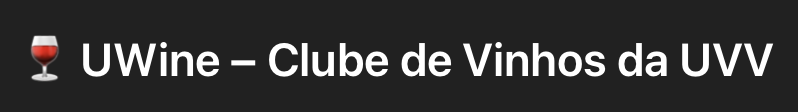

<center>

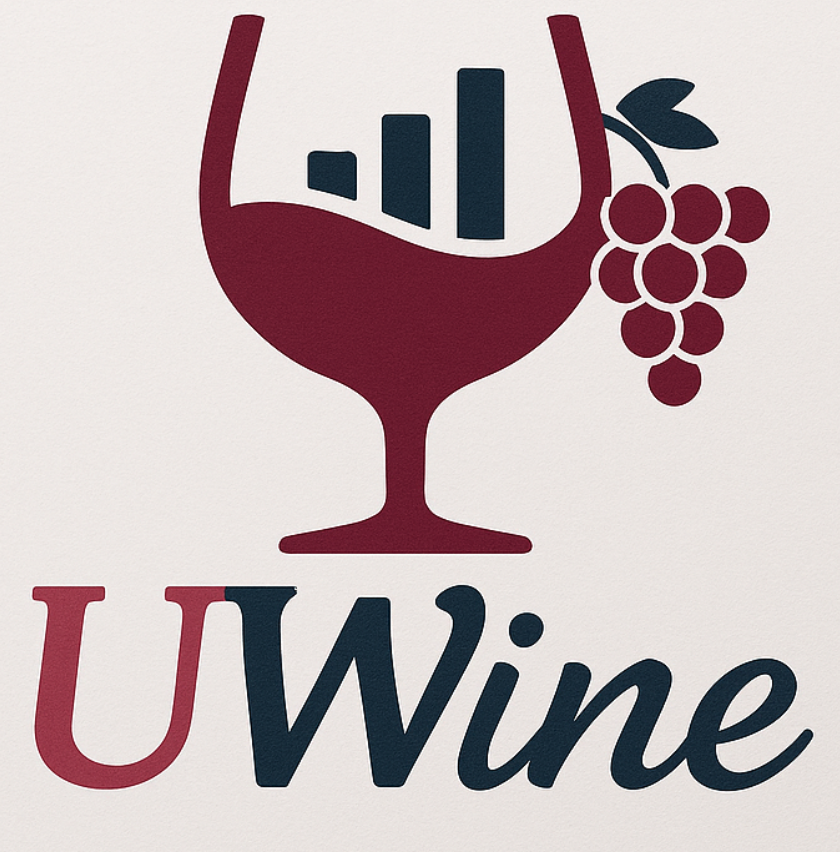

# **Cenário Fictício**:

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [1]:
# =====================================================================
# BIBLIOTECAS
# =====================================================================
import warnings
warnings.filterwarnings("ignore")

# Estruturação dos Dados: NDArray / Pandas
import numpy as np
import pandas as pd

# Inferência Estatística
import scipy.stats as stats
from scipy.stats import bootstrap
from statsmodels.stats.diagnostic import normal_ad

# Visualização dos Dados
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# =====================================================================
# PARÂMETROS GLOBAIS DO PROJETO
# =====================================================================
SEED = 42                      # semente: reprodutibilidade de todos os sorteios
ALPHA = 0.05                   # nível de significância dos testes de hipóteses
CONFIANCA = 0.95               # nível de confiança dos intervalos (bootstrap)
TARGET = "TOTAL (R$)"          # variável-alvo y
ESTRATO = "TIPO DA CONTA"      # variável de estratificação
CATEGORIAS = ["ESSENTIAL", "VIP", "PRIME", "GERAL"]
RESULTADOS = {}                # resultados consolidados para o RELATÓRIO FINAL

In [2]:
# load do seu TABLE: Número 49
CAMINHO_CSV = "table49.csv"    # Colab: faça o upload do arquivo (ou ajuste o caminho do Drive)
table49 = pd.read_csv(CAMINHO_CSV, index_col=0)

In [3]:
table49.head()

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,MEAN: ash,MEAN: alcalinity_of_ash,MEAN: magnesium,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,5599877,SUDESTE,MASCULINO,CASADO,1,3114.01,Funcionou bem e me atendeu no prazo certo a UV...,68.68,13.889469,0.888319,2.025148,15.031399,110.624206,2.373509,0.841325,0.434833,0.820013,3.292646,0.619036,1.740782,666.913966,ESSENTIAL,406.81
1,6073278,SUDESTE,MASCULINO,SOLTEIRO,1,3260.75,"Serviço eficiente, recomendo o clube: UVVine",68.68,13.176769,2.992842,2.007320,20.476971,121.278103,1.881114,2.779478,0.491869,1.415403,-1.711567,0.745543,3.223039,1271.902869,ESSENTIAL,425.89
2,6778574,SUDESTE,MASCULINO,DESQUITADO(A) / VIÚVO(A),0,3284.96,Funcionou bem e me atendeu no prazo certo a UV...,68.68,13.937095,3.233748,2.512778,19.827285,102.373312,2.149912,5.274161,0.368151,1.063499,4.021672,0.951387,1.235455,478.614213,ESSENTIAL,527.58
3,6233408,SUDESTE,MASCULINO,CASADO,1,3360.87,Gostei do atendimento prestado pela UVVine,68.68,12.655221,1.580153,2.238747,21.221193,91.232302,1.839967,2.140321,0.418517,0.790636,9.277366,1.042782,2.708610,881.604929,ESSENTIAL,539.73
4,6078448,SUL,MASCULINO,CASADO,2,7893.79,"Serviço eficiente, recomendo o clube: UVVine",68.68,13.676911,2.345487,1.957430,13.279484,109.989187,3.028276,2.432882,0.158512,2.397300,8.472973,1.181180,2.983931,848.548449,VIP,712.43


In [4]:
table49.shape

(1120000, 23)

In [5]:
# Verificação inicial da qualidade dos dados
print("Valores ausentes (total)  :", table49.isna().sum().sum())
print("Notas fiscais duplicadas  :", table49["NOTA FISCAL"].duplicated().sum())
print("\nTipos das variáveis:")
print(table49.dtypes.value_counts())
print("\nDistribuição dos estratos (TIPO DA CONTA):")
print(table49[ESTRATO].value_counts(normalize=True).round(4))

# Conferência da base completa (table49 = 1.120.000 linhas x 23 colunas)
LINHAS_ESPERADAS = 1_120_000
if table49.shape != (LINHAS_ESPERADAS, 23):
    print(f"\n⚠️ ATENÇÃO: a base carregada tem {table49.shape[0]:,} linhas e {table49.shape[1]} colunas "
          f"(esperado: {LINHAS_ESPERADAS:,} x 23). O upload do CSV pode estar incompleto – "
          "os resultados vão diferir.")
else:
    print("\n✅ Base completa carregada.")

Valores ausentes (total)  : 0
Notas fiscais duplicadas  : 0

Tipos das variáveis:
float64    16
object      5
int64       2
Name: count, dtype: int64

Distribuição dos estratos (TIPO DA CONTA):
TIPO DA CONTA
ESSENTIAL    0.5801
VIP          0.2411
PRIME        0.1788
Name: proportion, dtype: float64

✅ Base completa carregada.


## Funções do professor (TÓPICO I e Tamanho Ideal da Amostra)

In [6]:
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    value_column : str
        Numerical target variable used to estimate the mean.

    strata_column : str
        Categorical stratification variable.

    n_min : int, default=100
        Minimum total sample size evaluated.

    n_max : int, default=50000
        Maximum total sample size evaluated.

    step : int, default=100
        Increment between consecutive sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum relative reduction accepted for standard error stabilization.
        Example: 0.01 means 1%.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions that must remain below
        the stabilization threshold.

    plot : bool, default=True
        If True, plot the standard error stabilization curve.

    Returns
    -------
    summary : pandas.DataFrame
        Sample allocation per stratum.

    results : dict
        Dictionary containing:
        - optimal_n
        - optimal_standard_error
        - sample_sizes
        - standard_error_curve
        - marginal_reduction
        - stabilization_threshold
        - consecutive_points
        - strata_statistics
    """

    # Keep only the required columns and remove missing values
    data = df[[value_column, strata_column]].dropna().copy()

    # Convert the target variable to numeric
    data[value_column] = pd.to_numeric(data[value_column], errors="coerce")
    data = data.dropna()

    if data.empty:
        raise ValueError("The dataset is empty after removing missing or invalid values.")

    # Estimate stratum weights
    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    # Estimate stratum standard deviations
    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    # Align both series
    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError(
            "At least one stratum has insufficient observations "
            "to calculate standard deviation."
        )

    if np.any(Sh == 0):
        print(
            "Warning: At least one stratum has zero standard deviation. "
            "Neyman allocation may assign a very small sample to this stratum."
        )

    # Neyman allocation weights
    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError(
            "Neyman weights are zero. Check the variability of the target variable."
        )

    sample_sizes = np.arange(n_min, n_max + step, step)

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = n * neyman_weights / neyman_weights.sum()

        se = np.sqrt(
            np.sum(
                (Wh ** 2) * (Sh ** 2) / nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    # Marginal relative reduction of the standard error
    marginal_reduction = (
        np.abs(np.diff(standard_errors)) / standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(0, len(marginal_reduction) - consecutive_points + 1):

        window = marginal_reduction[i:i + consecutive_points]

        if np.all(window < stabilization_threshold):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No consecutive stabilization point found within the evaluated interval. "
            "Try increasing n_max, increasing step, or using a larger threshold."
        )

    optimal_index = stable_sequence_index + consecutive_points

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(optimal_allocation).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")
        plt.title("Consecutive Marginal Stabilization of the Standard Error")
        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mpl_toolkits.axes_grid1.inset_locator import (
    inset_axes,
    mark_inset
)


def optimal_sample_size(
    df,
    value_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the operational sample size for an infinite population
    using consecutive marginal stabilization of the standard error.

    Stabilization is confirmed when the marginal reduction in the
    projected standard error is less than or equal to the specified
    threshold for a given number of consecutive sample-size increments.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the reference or pilot data.

    value_column : str
        Name of the numerical variable used to estimate variability.

    n_min : int, default=100
        Minimum candidate sample size.

    n_max : int, default=50000
        Maximum candidate sample size.

    step : int, default=100
        Increment between candidate sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum acceptable marginal reduction in the standard error.
        For a monetary variable, 0.01 represents R$ 0.01.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions required to confirm
        stabilization.

    plot : bool, default=True
        If True, displays the standard-error curve, the mean
        standard-error line and a zoom window around the stabilization
        sequence.

    Returns
    -------
    dict
        Dictionary containing:

        - optimal_sample_size:
          Sample size at which stabilization is confirmed.

        - stabilization_start:
          First sample size in the confirmed sequence.

        - standard_error:
          Standard error at the recommended sample size.

        - mean_standard_error:
          Mean of the projected standard errors.

        - marginal_reduction:
          Marginal reduction at the confirmation point.

        - population_standard_deviation:
          Standard deviation estimated from the reference data.

        - stabilization_found:
          Indicates whether stabilization was found.

        - results:
          DataFrame containing all calculated points.

    Notes
    -----
    For an infinite population, the projected standard error is:

        SE(n) = s / sqrt(n)

    The marginal reduction is:

        Delta_SE(n) = SE(n - step) - SE(n)

    No finite population correction is applied.

    The returned sample size is an operational recommendation conditioned
    on the parameters of the function. It is not a universal mathematical
    optimum.
    """

    # ==============================================================
    # 1. Input validation
    # ==============================================================
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if value_column not in df.columns:
        raise KeyError(
            f"Column '{value_column}' was not found in the DataFrame."
        )

    if (
        not isinstance(n_min, int)
        or isinstance(n_min, bool)
        or n_min < 2
    ):
        raise ValueError(
            "n_min must be an integer greater than or equal to 2."
        )

    if (
        not isinstance(n_max, int)
        or isinstance(n_max, bool)
        or n_max <= n_min
    ):
        raise ValueError(
            "n_max must be an integer greater than n_min."
        )

    if (
        not isinstance(step, int)
        or isinstance(step, bool)
        or step <= 0
    ):
        raise ValueError(
            "step must be a positive integer."
        )

    if (
        not isinstance(stabilization_threshold, (int, float))
        or isinstance(stabilization_threshold, bool)
        or not np.isfinite(stabilization_threshold)
        or stabilization_threshold <= 0
    ):
        raise ValueError(
            "stabilization_threshold must be a finite number "
            "greater than zero."
        )

    if (
        not isinstance(consecutive_points, int)
        or isinstance(consecutive_points, bool)
        or consecutive_points < 1
    ):
        raise ValueError(
            "consecutive_points must be a positive integer."
        )

    # ==============================================================
    # 2. Numerical data preparation
    # ==============================================================
    values = pd.to_numeric(
        df[value_column],
        errors="coerce"
    ).dropna()

    if len(values) < 2:
        raise ValueError(
            "The selected column must contain at least two valid "
            "numerical observations."
        )

    standard_deviation = float(
        values.std(ddof=1)
    )

    if not np.isfinite(standard_deviation):
        raise ValueError(
            "The standard deviation could not be estimated."
        )

    if standard_deviation == 0:
        raise ValueError(
            "The selected variable has zero variability."
        )

    # ==============================================================
    # 3. Candidate sample sizes
    # ==============================================================
    sample_sizes = np.arange(
        n_min,
        n_max + 1,
        step,
        dtype=int
    )

    if len(sample_sizes) <= consecutive_points:
        raise ValueError(
            "The search interval must contain more candidate sizes "
            "than consecutive_points."
        )

    # Projected standard error for an infinite population:
    # SE(n) = s / sqrt(n)
    standard_errors = (
        standard_deviation / np.sqrt(sample_sizes)
    )

    # Mean of the projected standard errors
    mean_standard_error = float(
        np.mean(standard_errors)
    )

    # Marginal reduction:
    # SE at the previous point minus SE at the current point
    marginal_reductions = np.full(
        len(standard_errors),
        np.nan,
        dtype=float
    )

    marginal_reductions[1:] = (
        standard_errors[:-1]
        - standard_errors[1:]
    )

    # A point is stable when the marginal reduction is less than
    # or equal to the defined threshold.
    stable_points = np.zeros(
        len(sample_sizes),
        dtype=bool
    )

    stable_points[1:] = (
        marginal_reductions[1:]
        <= stabilization_threshold
    )

    # ==============================================================
    # 4. Consecutive stabilization search
    # ==============================================================
    confirmation_index = None
    consecutive_count = 0

    for index in range(1, len(sample_sizes)):

        if stable_points[index]:
            consecutive_count += 1
        else:
            consecutive_count = 0

        if consecutive_count >= consecutive_points:
            confirmation_index = index
            break

    if confirmation_index is not None:

        start_index = (
            confirmation_index
            - consecutive_points
            + 1
        )

        stabilization_indices = np.arange(
            start_index,
            confirmation_index + 1
        )

        stabilization_start = int(
            sample_sizes[start_index]
        )

        optimal_n = int(
            sample_sizes[confirmation_index]
        )

        optimal_se = float(
            standard_errors[confirmation_index]
        )

        optimal_reduction = float(
            marginal_reductions[confirmation_index]
        )

        stabilization_found = True

    else:

        start_index = None

        stabilization_indices = np.array(
            [],
            dtype=int
        )

        stabilization_start = None
        optimal_n = None
        optimal_se = None
        optimal_reduction = None
        stabilization_found = False

    # ==============================================================
    # 5. Complete result table
    # ==============================================================
    results = pd.DataFrame({
        "sample_size": sample_sizes,
        "standard_error": standard_errors,
        "marginal_reduction": marginal_reductions,
        "stable_point": stable_points,
        "consecutive_confirmation": False
    })

    if stabilization_found:
        results.loc[
            stabilization_indices,
            "consecutive_confirmation"
        ] = True

    # ==============================================================
    # 6. Visualization
    # ==============================================================
    if plot:

        # Constrained layout avoids the tight_layout warning.
        figure, axis = plt.subplots(
            figsize=(15, 8),
            layout="constrained"
        )

        # Main standard-error curve
        axis.plot(
            sample_sizes,
            standard_errors,
            color="#2878B5",
            linewidth=2.6
        )

        # Mean standard-error horizontal line
        axis.axhline(
            y=mean_standard_error,
            color="#D62728",
            linestyle="--",
            linewidth=2
        )

        # Identification of the mean standard-error line
        axis.text(
            n_max,
            mean_standard_error,
            (
                "  Erro-padrão médio = "
                f"{mean_standard_error:.4f}"
            ),
            color="#D62728",
            fontsize=10,
            va="bottom",
            ha="right"
        )

        if stabilization_found:

            zoom_x = sample_sizes[
                stabilization_indices
            ]

            zoom_y = standard_errors[
                stabilization_indices
            ]

            # Consecutive stabilization points
            axis.scatter(
                zoom_x,
                zoom_y,
                s=95,
                color="#FF9F1C",
                edgecolor="white",
                linewidth=1.2,
                zorder=5
            )

            # Recommended sample size
            axis.scatter(
                optimal_n,
                optimal_se,
                s=190,
                color="#D62728",
                edgecolor="white",
                linewidth=1.8,
                zorder=6
            )

            # Vertical line at the confirmation point
            axis.axvline(
                x=optimal_n,
                color="#D62728",
                linestyle=":",
                linewidth=1.8
            )

            annotation = (
                f"n recomendado = {optimal_n:,}\n"
                f"EP = {optimal_se:.4f}\n"
                f"ΔEP = {optimal_reduction:.4f}"
            ).replace(",", ".")

            axis.annotate(
                annotation,
                xy=(optimal_n, optimal_se),
                xytext=(20, 38),
                textcoords="offset points",
                fontsize=10.5,
                bbox={
                    "boxstyle": "round,pad=0.45",
                    "facecolor": "white",
                    "edgecolor": "#D62728",
                    "alpha": 0.95
                },
                arrowprops={
                    "arrowstyle": "->",
                    "color": "#D62728",
                    "linewidth": 1.4
                }
            )

            # ======================================================
            # 6.1 Zoom window
            # ======================================================
            inset_axis = inset_axes(
                axis,
                width="43%",
                height="43%",
                loc="upper right",
                borderpad=1.8
            )

            # Includes one point before and one point after the
            # stabilization sequence, whenever available.
            context_start = max(
                start_index - 1,
                0
            )

            context_end = min(
                confirmation_index + 1,
                len(sample_sizes) - 1
            )

            context_indices = np.arange(
                context_start,
                context_end + 1
            )

            # Standard-error curve inside the zoom window
            inset_axis.plot(
                sample_sizes[context_indices],
                standard_errors[context_indices],
                color="#2878B5",
                linewidth=2.2,
                marker="o",
                markersize=5
            )

            # Consecutive stabilization points
            inset_axis.scatter(
                zoom_x,
                zoom_y,
                s=90,
                color="#FF9F1C",
                edgecolor="white",
                linewidth=1.1,
                zorder=5
            )

            # Confirmation point
            inset_axis.scatter(
                optimal_n,
                optimal_se,
                s=145,
                color="#D62728",
                edgecolor="white",
                linewidth=1.5,
                zorder=6
            )

            # Mean standard-error line inside the zoom
            inset_axis.axhline(
                y=mean_standard_error,
                color="#D62728",
                linestyle="--",
                linewidth=1.2,
                alpha=0.8
            )

            # Numerical labels for consecutive stabilization points
            for point_number, point_index in enumerate(
                stabilization_indices,
                start=1
            ):

                point_n = sample_sizes[point_index]
                point_se = standard_errors[point_index]

                inset_axis.annotate(
                    str(point_number),
                    xy=(point_n, point_se),
                    xytext=(0, 10),
                    textcoords="offset points",
                    ha="center",
                    fontsize=9,
                    fontweight="bold",
                    color="#8C4A00"
                )

            # Horizontal limits of the zoom window
            x_margin = max(
                step * 0.4,
                1
            )

            inset_axis.set_xlim(
                sample_sizes[context_start] - x_margin,
                sample_sizes[context_end] + x_margin
            )

            # Vertical limits of the zoom window
            local_standard_errors = standard_errors[
                context_indices
            ]

            y_range = float(
                local_standard_errors.max()
                - local_standard_errors.min()
            )

            if y_range == 0:

                y_margin = max(
                    abs(
                        float(
                            local_standard_errors.mean()
                        )
                    ) * 0.05,
                    1e-6
                )

            else:

                y_margin = y_range * 0.30

            inset_axis.set_ylim(
                float(local_standard_errors.min())
                - y_margin,
                float(local_standard_errors.max())
                + y_margin
            )

            inset_axis.set_title(
                (
                    "Janela ampliada: "
                    f"{consecutive_points} pontos consecutivos"
                ),
                fontsize=10,
                fontweight="bold"
            )

            inset_axis.set_xlabel(
                "Tamanho da amostra",
                fontsize=8
            )

            inset_axis.set_ylabel(
                "Erro-padrão",
                fontsize=8
            )

            inset_axis.tick_params(
                axis="both",
                labelsize=8
            )

            inset_axis.grid(
                True,
                linestyle="--",
                linewidth=0.6,
                alpha=0.5
            )

            # Rectangle and connectors identifying the zoom region
            mark_inset(
                axis,
                inset_axis,
                loc1=2,
                loc2=4,
                fc="none",
                ec="#E76F8A",
                linewidth=1.5
            )

            title = (
                "Estabilização Marginal Consecutiva "
                "do Erro-Padrão\n"
                f"Estabilização confirmada em n = {optimal_n:,}"
            ).replace(",", ".")

        else:

            title = (
                "Estabilização Marginal Consecutiva "
                "do Erro-Padrão\n"
                "Estabilização não encontrada no intervalo analisado"
            )

        axis.set_title(
            title,
            fontsize=15,
            fontweight="bold",
            pad=12
        )

        axis.set_xlabel(
            "Tamanho total da amostra (n)",
            fontsize=12
        )

        axis.set_ylabel(
            "Erro-padrão",
            fontsize=12
        )

        axis.grid(
            True,
            linestyle="--",
            linewidth=0.7,
            alpha=0.45
        )

        # A legenda foi intencionalmente retirada.
        # Não utilizar axis.legend() ou plt.legend().

        plt.show()

    # ==============================================================
    # 7. Structured return
    # ==============================================================
    return {
        "optimal_sample_size": optimal_n,
        "stabilization_start": stabilization_start,
        "standard_error": optimal_se,
        "mean_standard_error": mean_standard_error,
        "marginal_reduction": optimal_reduction,
        "population_standard_deviation": standard_deviation,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "step": step,
        "stabilization_found": stabilization_found,
        "results": results
    }

In [8]:
def statistic(_dataset):
    """
      Compute descriptive statistics for a numerical dataset.

      This function extends the standard pandas `describe()` method
      by removing the count metric and adding:
      - Range (max - min)
      - Mode

      The output is a table of descriptive statistics commonly used
      in Exploratory Data Analysis (EDA).

      Parameters
      ----------
      _dataset : pandas.Series or pandas.DataFrame
          Input dataset containing numerical values.

      Returns
      -------
      pandas.DataFrame
          A DataFrame with descriptive statistics (excluding count),
          including range and mode, sorted and rounded to two decimals.
    """

    # Generate basic descriptive statistics using pandas
    # (count, mean, std, min, quartiles, and max)
    _describe = _dataset.describe()

    # Remove the 'count' row, as it is not used in this analysis
    _describe = _describe.drop('count')

    # Compute the range for each numerical column
    # Range = maximum value minus minimum value
    _describe.loc['range'] = _describe.loc['max'] - _describe.loc['min']

    # Compute the mode for each numerical column
    # stats.mode returns both mode and frequency;
    # [0] extracts only the modal value
    _describe.loc['mode'] = stats.mode(
        _dataset,
        keepdims=False,
        nan_policy='omit'
    )[0]

    # Sort the statistics (index) and round all values to two decimal places
    _describe = np.around(_describe.sort_values(), 2)

    # Return the final descriptive statistics table
    return _describe

In [9]:
def PlotarStatistic(dataset, yLabel=None):
    """
      Plot descriptive statistics of a dataset and highlight
      measures of central tendency (mean, median, and mode).

      This function computes descriptive statistics using a
      previously defined `statistic()` function, generates
      a plot with summary measures, and prints the numerical
      descriptive table.

      Parameters
      ----------
      dataset : pandas.Series or pandas.DataFrame
          Input dataset containing numerical values.
          It is expected that the statistic() function
          can process this object.

      yLabel : str, optional
          Label for the y-axis of the plot.

      Returns
      -------
      None
          Displays a plot and prints descriptive statistics.
    """

    # Compute descriptive statistics using a custom function
    _describe = statistic(dataset)

    # -------------------------------------------------------
    # Construction of LaTeX-formatted labels for statistics
    # -------------------------------------------------------

    # Mean (population notation: overline mu)
    # Raw string (r'') avoids invalid escape sequence warnings
    mean_mu = r'MÉDIA:  $\overline{\mu}$ = '
    mean_mu += f'{_describe["mean"]: .2f}'  # Numeric value formatted to 2 decimals

    # Median (tilde mu)
    median_mu = r'MEDIANA: $\tilde{\mu}$ = '
    median_mu += f'{_describe["50%"]: .2f}'

    # Mode (hat mu)
    mode_mu = r'MODA: $\hat{\mu}$ = '
    mode_mu += f'{_describe["mode"]: .2f}'

    # New line separator for legend text composition
    enter = '\n'

    # Concatenated label containing all summary measures
    label = mean_mu + enter + median_mu + enter + mode_mu

    # -------------------------------------------------------
    # Plotting section
    # -------------------------------------------------------

    # Apply the statistic function as an aggregation and plot the result
    # (Assumes dataset supports aggregation and plotting)
    dataset.agg(statistic).plot(
        figsize=[15, 6],
        label='MEDIDAS DE RESUMO: '
    )

    # Plot the mean marker at its corresponding index position
    plt.plot(
        list(_describe.index).index('mean'),
        _describe["mean"],
        'D',
        label=mean_mu
    )

    # Plot the median marker
    plt.plot(
        list(_describe.index).index('50%'),
        _describe["50%"],
        'D',
        label=median_mu
    )

    # Plot the mode marker
    plt.plot(
        list(_describe.index).index('mode'),
        _describe["mode"],
        'D',
        label=mode_mu
    )

    # Set plot title
    plt.title('ESTATÍSTICA DESCRITIVA DO DATASET')

    # Display legend with statistical labels
    plt.legend()

    # Set y-axis label if provided
    plt.ylabel(yLabel)

    # Render the plot
    plt.show()

    # -------------------------------------------------------
    # Textual output
    # -------------------------------------------------------

    # Print descriptive statistics table
    print('ESTATÍSTICA DESCRITIVA DO DATASET:')
    print(_describe)

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats


def normalChart(data, yLabel=None):
    """
    Perform exploratory data analysis and assess distribution normality.

    The function generates a histogram with a kernel density estimate
    (KDE), highlights the mean, median and mode, calculates descriptive
    statistics and provides heuristic and statistical normality
    diagnostics.

    Parameters
    ----------
    data : pandas.Series or array-like
        Numerical observations to be analyzed. Missing and non-numerical
        values are removed before the calculations.

    yLabel : str, optional
        Descriptive name of the analyzed variable. It is used in the
        chart title, horizontal-axis label and diagnostic report.

    Returns
    -------
    dict
        Dictionary containing:

        - variable:
          Name of the analyzed variable.

        - sample_size:
          Number of valid observations.

        - bins:
          Number of histogram bins calculated using Sturges' rule.

        - minimum:
          Minimum observed value.

        - maximum:
          Maximum observed value.

        - range:
          Difference between the maximum and minimum values.

        - mean:
          Arithmetic mean.

        - median:
          Median.

        - mode:
          First mode identified in the data.

        - variance:
          Sample variance.

        - standard_deviation:
          Sample standard deviation.

        - coefficient_of_variation:
          Coefficient of variation expressed as a percentage.

        - skewness:
          Fisher-Pearson sample skewness.

        - kurtosis:
          Fisher's excess kurtosis.

        - quartile_1:
          First quartile.

        - quartile_3:
          Third quartile.

        - interquartile_range:
          Interquartile range.

        - cv_diagnosis:
          Classification of relative dispersion.

        - skewness_diagnosis:
          Classification of distribution asymmetry.

        - kurtosis_diagnosis:
          Classification of distribution shape.

        - heuristic_normality:
          Heuristic conclusion based on skewness and kurtosis.

        - shapiro_statistic:
          Shapiro-Wilk test statistic.

        - shapiro_p_value:
          Shapiro-Wilk test p-value.

        - shapiro_conclusion:
          Statistical conclusion at the 5% significance level.

        - descriptive_statistics:
          DataFrame containing the main descriptive statistics.

    Notes
    -----
    The number of histogram bins is estimated using Sturges' rule:

        k = ceil(1 + log2(n))

    The coefficient of variation is calculated as:

        CV = (s / |mean|) * 100

    where ``s`` is the sample standard deviation.

    The coefficient of variation measures relative dispersion and must
    not be interpreted as a formal normality criterion.

    The heuristic normality assessment uses the following conditions:

        |skewness| <= 0.5
        |excess kurtosis| <= 0.5

    The Shapiro-Wilk test evaluates:

        H0: the data follow a normal distribution.
        H1: the data do not follow a normal distribution.

    At the 5% significance level:

        p-value > 0.05  -> H0 is not rejected.
        p-value <= 0.05 -> H0 is rejected.

    For samples larger than 5,000 observations, the Shapiro-Wilk test
    is applied to a reproducible random sample of 5,000 observations
    because its p-value may be less reliable for larger datasets.

    Visual inspection, descriptive measures and formal statistical
    tests should be interpreted together.
    """

    # ==============================================================
    # 1. Data validation and preparation
    # ==============================================================
    if isinstance(data, pd.DataFrame):
        raise TypeError(
            "data must be a pandas Series or a one-dimensional array."
        )

    values = pd.Series(data, name=yLabel)

    values = pd.to_numeric(
        values,
        errors="coerce"
    ).dropna()

    if len(values) < 3:
        raise ValueError(
            "The analysis requires at least three valid numerical "
            "observations."
        )

    if values.nunique() < 2:
        raise ValueError(
            "The analyzed variable must contain at least two "
            "distinct values."
        )

    variable_name = (
        yLabel
        or getattr(data, "name", None)
        or "Variável"
    )

    # ==============================================================
    # 2. Basic descriptive statistics
    # ==============================================================
    n = int(len(values))

    bins = max(
        1,
        int(np.ceil(1 + np.log2(n)))
    )

    minimum = float(values.min())
    maximum = float(values.max())
    data_range = float(maximum - minimum)

    mean_value = float(values.mean())
    median_value = float(values.median())

    mode_values = values.mode()

    mode_value = (
        float(mode_values.iloc[0])
        if not mode_values.empty
        else np.nan
    )

    variance = float(values.var(ddof=1))
    standard_deviation = float(values.std(ddof=1))

    quartile_1 = float(values.quantile(0.25))
    quartile_3 = float(values.quantile(0.75))
    interquartile_range = float(quartile_3 - quartile_1)

    # The absolute mean prevents a negative CV.
    if np.isclose(mean_value, 0.0):
        coefficient_of_variation = np.nan
    else:
        coefficient_of_variation = float(
            (standard_deviation / abs(mean_value)) * 100
        )

    skewness = float(
        stats.skew(
            values,
            bias=False,
            nan_policy="omit"
        )
    )

    kurtosis = float(
        stats.kurtosis(
            values,
            fisher=True,
            bias=False,
            nan_policy="omit"
        )
    )

    # ==============================================================
    # 3. Exploratory diagnoses
    # ==============================================================
    if np.isnan(coefficient_of_variation):

        cv_diagnosis = (
            "CV indefinido: média igual ou muito próxima de zero"
        )

    elif coefficient_of_variation < 15:

        cv_diagnosis = (
            "Baixa dispersão relativa (CV < 15%)"
        )

    elif coefficient_of_variation < 30:

        cv_diagnosis = (
            "Dispersão relativa moderada (15% ≤ CV < 30%)"
        )

    else:

        cv_diagnosis = (
            "Alta dispersão relativa (CV ≥ 30%)"
        )

    if abs(skewness) <= 0.5:

        skewness_diagnosis = (
            "Distribuição aproximadamente simétrica"
        )

    elif skewness > 0 and abs(skewness) <= 1:

        skewness_diagnosis = (
            "Assimetria moderada à direita (positiva)"
        )

    elif skewness > 1:

        skewness_diagnosis = (
            "Assimetria acentuada à direita (positiva)"
        )

    elif skewness < 0 and abs(skewness) <= 1:

        skewness_diagnosis = (
            "Assimetria moderada à esquerda (negativa)"
        )

    else:

        skewness_diagnosis = (
            "Assimetria acentuada à esquerda (negativa)"
        )

    if abs(kurtosis) <= 0.5:

        kurtosis_diagnosis = (
            "MESOCÚRTICA: formato próximo ao da distribuição normal"
        )

    elif kurtosis > 0.5:

        kurtosis_diagnosis = (
            "LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas"
        )

    else:

        kurtosis_diagnosis = (
            "PLATICÚRTICA: distribuição relativamente mais achatada"
        )

    heuristic_normality_condition = (
        abs(skewness) <= 0.5
        and abs(kurtosis) <= 0.5
    )

    if heuristic_normality_condition:

        heuristic_normality = (
            "Compatível com normalidade pelos critérios heurísticos"
        )

    else:

        heuristic_normality = (
            "Não compatível com normalidade pelos critérios heurísticos"
        )

    # ==============================================================
    # 4. Shapiro-Wilk normality test
    # ==============================================================
    if n <= 5000:

        shapiro_data = values.to_numpy()
        shapiro_sampled = False

    else:

        shapiro_data = values.sample(
            n=5000,
            random_state=42
        ).to_numpy()

        shapiro_sampled = True

    shapiro_result = stats.shapiro(shapiro_data)

    shapiro_statistic = float(
        shapiro_result.statistic
    )

    shapiro_p_value = float(
        shapiro_result.pvalue
    )

    significance_level = 0.05

    if shapiro_p_value > significance_level:

        shapiro_conclusion = (
            "Não se rejeita H₀: os dados são compatíveis com "
            "uma distribuição normal ao nível de 5%."
        )

    else:

        shapiro_conclusion = (
            "Rejeita-se H₀: há evidências de que os dados não "
            "seguem uma distribuição normal ao nível de 5%."
        )

    # ==============================================================
    # 5. Descriptive-statistics table
    # ==============================================================
    descriptive_statistics = pd.DataFrame({
        "Estatística": [
            "Tamanho da amostra",
            "Mínimo",
            "Primeiro quartil (Q1)",
            "Média",
            "Mediana",
            "Moda",
            "Terceiro quartil (Q3)",
            "Máximo",
            "Amplitude",
            "Intervalo interquartil",
            "Variância amostral",
            "Desvio-padrão amostral",
            "Coeficiente de variação (%)",
            "Assimetria",
            "Curtose de excesso"
        ],
        "Valor": [
            n,
            minimum,
            quartile_1,
            mean_value,
            median_value,
            mode_value,
            quartile_3,
            maximum,
            data_range,
            interquartile_range,
            variance,
            standard_deviation,
            coefficient_of_variation,
            skewness,
            kurtosis
        ]
    })

    # ==============================================================
    # 6. Histogram and kernel density estimate
    # ==============================================================
    figure, axis = plt.subplots(
        figsize=(15, 6),
        layout="constrained"
    )

    sns.histplot(
        values,
        bins=bins,
        kde=True,
        stat="count",
        color="steelblue",
        alpha=0.55,
        edgecolor="white",
        linewidth=0.8,
        ax=axis
    )

    axis.axvline(
        mean_value,
        color="#D62728",
        linestyle="--",
        linewidth=2.2,
        label=f"Média: {mean_value:.4f}"
    )

    axis.axvline(
        median_value,
        color="#2CA02C",
        linestyle="-.",
        linewidth=2.2,
        label=f"Mediana: {median_value:.4f}"
    )

    axis.axvline(
        mode_value,
        color="#FF9F1C",
        linestyle=":",
        linewidth=2.4,
        label=f"Moda: {mode_value:.4f}"
    )

    # Invisible entries used to display EDA measures in the legend.
    axis.plot(
        [],
        [],
        color="none",
        label=(
            "CV: indefinido"
            if np.isnan(coefficient_of_variation)
            else f"CV: {coefficient_of_variation:.2f}%"
        )
    )

    axis.plot(
        [],
        [],
        color="none",
        label=f"Assimetria: {skewness:.4f}"
    )

    axis.plot(
        [],
        [],
        color="none",
        label=f"Curtose: {kurtosis:.4f}"
    )

    axis.set_title(
        (
            f"Análise Exploratória da Distribuição: "
            f"{variable_name}\n"
            f"n = {n:,} | Bins de Sturges = {bins}"
        ).replace(",", "."),
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    axis.set_xlabel(
        variable_name,
        fontsize=12
    )

    axis.set_ylabel(
        "Frequência",
        fontsize=12
    )

    axis.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.4
    )

    axis.legend(
        title="Estatísticas descritivas",
        fontsize=10,
        title_fontsize=10,
        frameon=True
    )

    plt.show()

    # ==============================================================
    # 7. Textual EDA report
    # ==============================================================
    cv_text = (
        "indefinido"
        if np.isnan(coefficient_of_variation)
        else f"{coefficient_of_variation:.2f}%"
    )

    sampling_note = (
        "amostra aleatória reprodutível de 5.000 observações"
        if shapiro_sampled
        else f"{n} observações"
    )

    print(f'\n{"=" * 78}')
    print(f"  ANÁLISE EXPLORATÓRIA DOS DADOS: {variable_name}")
    print(f'{"=" * 78}')

    print("\n  1. ESTATÍSTICAS DESCRITIVAS")
    print(f"     Observações   : {n}")
    print(f"     Mínimo        : {minimum:.4f}")
    print(f"     Máximo        : {maximum:.4f}")
    print(f"     Média         : {mean_value:.4f}")
    print(f"     Mediana       : {median_value:.4f}")
    print(f"     Moda          : {mode_value:.4f}")
    print(f"     Desvio-padrão : {standard_deviation:.4f}")
    print(f"     CV            : {cv_text}")

    print("\n  2. DIAGNÓSTICO EXPLORATÓRIO")
    print(f"     Dispersão     : {cv_diagnosis}")
    print(
        f"     Assimetria    : {skewness:.4f} → "
        f"{skewness_diagnosis}"
    )
    print(
        f"     Curtose       : {kurtosis:.4f} → "
        f"{kurtosis_diagnosis}"
    )
    print(f"     Heurística    : {heuristic_normality}")

    print("\n  3. TESTE DE SHAPIRO–WILK")
    print(f"     Dados usados  : {sampling_note}")
    print(f"     Estatística W : {shapiro_statistic:.6f}")
    print(f"     Valor-p       : {shapiro_p_value:.6g}")
    print(f"     Significância : {significance_level:.2f}")
    print(f"     Conclusão     : {shapiro_conclusion}")

    print(f'\n{"=" * 78}\n')

    # ==============================================================
    # 8. Structured return
    # ==============================================================
    return {
        "variable": variable_name,
        "sample_size": n,
        "bins": bins,
        "minimum": minimum,
        "maximum": maximum,
        "range": data_range,
        "mean": mean_value,
        "median": median_value,
        "mode": mode_value,
        "variance": variance,
        "standard_deviation": standard_deviation,
        "coefficient_of_variation": coefficient_of_variation,
        "skewness": skewness,
        "kurtosis": kurtosis,
        "quartile_1": quartile_1,
        "quartile_3": quartile_3,
        "interquartile_range": interquartile_range,
        "cv_diagnosis": cv_diagnosis,
        "skewness_diagnosis": skewness_diagnosis,
        "kurtosis_diagnosis": kurtosis_diagnosis,
        "heuristic_normality": heuristic_normality,
        "shapiro_statistic": shapiro_statistic,
        "shapiro_p_value": shapiro_p_value,
        "shapiro_conclusion": shapiro_conclusion,
        "descriptive_statistics": descriptive_statistics
    }

In [11]:
def SE(dataset):
  '''
    HELP: Standart Error (Erro Padrão)
    O Erro-Padrão é uma métrica única que resume a variabilidade na distribuição de amostragem para uma estatística.
    Ele pode ser estimado utilizando uma estatística baseada no desvio-padrão (Sigma) dos valores da amostra e no tamanho de amostra N:
  '''
  return dataset.std() / (len(dataset) ** 0.5)

In [12]:
def bootstrap_distribution_eda(data, metric=np.mean, bins=30, confidence_level=CONFIANCA,
                               n_resamples=2000, method="percentile", title=None,
                               xlabel="Valor da estatística", plot=True, seed=SEED):
    """
    Compute and visualize the bootstrap sampling distribution of a statistic
    using Seaborn for advanced Exploratory Data Analysis (EDA).

    (Função do TÓPICO I, adaptada com título, rótulos, semente e método.)

    Parameters
    ----------
    data : array-like
        One-dimensional numeric sample.
    metric : callable, default=np.mean
        Statistic applied to each bootstrap resample.
    bins : int, default=30
        Number of histogram bins.
    confidence_level : float, default=CONFIANCA (0.95)
        Confidence level for the bootstrap interval.
    n_resamples : int, default=2000
        Number of bootstrap resamples.
    method : str, default="percentile"
        CI method. "percentile" is used because BCa requires a jackknife of
        cost O(n²), infeasible for samples with tens of thousands of rows.
    title, xlabel : str, optional
        Chart title and x-axis label.
    plot : bool, default=True
        If True, plots the bootstrap distribution.
    seed : int, default=SEED
        Random seed.

    Returns
    -------
    res : BootstrapResult
        Object containing bootstrap distribution, CI, and standard error.
    """
    rng = np.random.default_rng(seed)
    data = (np.asarray(data, dtype=float),)

    # Bootstrap computation (batch limits memory usage)
    res = bootstrap(
        data,
        metric,
        n_resamples=n_resamples,
        confidence_level=confidence_level,
        method=method,
        random_state=rng,
        batch=100
    )

    dist = res.bootstrap_distribution

    if plot:
        plt.figure(figsize=(10, 5))
        sns.histplot(dist, bins=bins, kde=True, stat="density")
        plt.axvline(np.mean(dist), color="black", linestyle="-",
                    label=f"Média bootstrap = {np.mean(dist):.4f}")
        plt.axvline(res.confidence_interval.low, color="red", linestyle="--",
                    label=f"IC inferior = {res.confidence_interval.low:.4f}")
        plt.axvline(res.confidence_interval.high, color="red", linestyle="--",
                    label=f"IC superior = {res.confidence_interval.high:.4f}")
        plt.title(title or "Distribuição Amostral Bootstrap")
        plt.xlabel(xlabel)
        plt.ylabel("Densidade")
        plt.legend()
        plt.show()

        print("CONFIDENCE INTERVAL")
        print(f"LOW  : {res.confidence_interval.low:.4f}")
        print(f"HIGH : {res.confidence_interval.high:.4f}")
        print(f"SE   : {res.standard_error:.4f}")

    return res

## Funções auxiliares e Atividades (modularizadas, com docstring)

In [13]:
def get_categoria(df, categoria, value_column=TARGET, strata_column=ESTRATO):
    """
    Return the target variable for one category of the stratification column.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset (population or sample).
    categoria : str
        "ESSENTIAL", "VIP", "PRIME" or "GERAL" (all rows).
    value_column : str, default=TARGET
        Numerical variable to return.
    strata_column : str, default=ESTRATO
        Stratification column.

    Returns
    -------
    pandas.Series
        Values of `value_column` for the requested category.
    """
    if categoria == "GERAL":
        return df[value_column]
    return df.loc[df[strata_column] == categoria, value_column]


def curva_erro_padrao_empirica(values, categoria, n_min=100, n_max=200_000, step=100,
                               n_destaque=None, janela=5_000, seed=SEED):
    """
    Plot the MEAN STANDARD ERROR chart (procedure of TÓPICO I).

    For each sample size n (n_min, n_min + step, ..., n_max) a random sample
    WITHOUT replacement is drawn from the category and SE = s / sqrt(n) is
    computed. The empirical curve is compared with the theoretical curve
    s_pop / sqrt(n) and with the mean standard error (red dashed line).
    A second panel zooms around the recommended sample size.

    Parameters
    ----------
    values : pandas.Series
        Target variable of the category.
    categoria : str
        Category name (used in titles).
    n_min, n_max, step : int
        Grid of candidate sample sizes (n_max is limited to the category size).
    n_destaque : int, optional
        Recommended sample size to highlight (vertical line and zoom center).
    janela : int, default=5000
        Half-width of the zoom window.
    seed : int, default=SEED
        Random seed.

    Returns
    -------
    dict
        sizes, se_empirico, se_teorico and se_medio (mean standard error).
    """
    rng = np.random.default_rng(seed)
    arr = pd.to_numeric(values, errors="coerce").dropna().to_numpy()
    n_max = min(n_max, len(arr))
    sizes = np.arange(n_min, n_max + 1, step)

    se_emp = np.array([rng.choice(arr, size=n, replace=False).std(ddof=1) / np.sqrt(n)
                       for n in sizes])
    se_teo = arr.std(ddof=1) / np.sqrt(sizes)
    se_medio = float(se_emp.mean())

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")

    ax = axes[0]
    ax.plot(sizes, se_emp, lw=1, color="#2878B5", label="EP empírico (amostras sorteadas)")
    ax.plot(sizes, se_teo, lw=1.5, ls=":", color="black", label="EP teórico  s/√n")
    ax.axhline(se_medio, color="red", ls="--", label=f"EP médio = R$ {se_medio:.2f}")
    if n_destaque:
        ax.axvline(n_destaque, color="#FF9F1C", ls="--",
                   label=f"n recomendado = {n_destaque:,}".replace(",", "."))
    ax.set_title(f"Erro-Padrão Médio – {categoria}: R$ {se_medio:.2f}", fontweight="bold")
    ax.set_xlabel("TAMANHO DA AMOSTRA (n)")
    ax.set_ylabel("ERRO PADRÃO (R$)")
    ax.legend()

    centro = n_destaque or int(sizes[len(sizes) // 2])
    mask = (sizes >= centro - janela) & (sizes <= centro + janela)
    ax = axes[1]
    ax.plot(sizes[mask], se_emp[mask], marker=".", lw=1, color="#2878B5", label="EP empírico")
    ax.plot(sizes[mask], se_teo[mask], ls=":", color="black", label="EP teórico")
    if n_destaque:
        ax.axvline(n_destaque, color="#FF9F1C", ls="--", label="n recomendado")
    ax.set_title(f"Zoom: n entre {max(centro - janela, n_min):,} e {centro + janela:,}".replace(",", "."),
                 fontweight="bold")
    ax.set_xlabel("TAMANHO DA AMOSTRA (n)")
    ax.set_ylabel("ERRO PADRÃO (R$)")
    ax.legend()
    plt.show()

    return {"sizes": sizes, "se_empirico": se_emp, "se_teorico": se_teo, "se_medio": se_medio}


def gerar_amostras_estratificadas(df, n_total, strata_column=ESTRATO, seed=SEED):
    """
    Draw SAMPLE 1 and SAMPLE 2: two DISJOINT stratified random samples
    (without replacement), each one with `n_total` rows and PROPORTIONAL
    allocation (n_h = n * W_h).

    Proportional allocation is self-weighting: the proportions of every
    variable (SEXO, REGIÃO, OPINIÃO...) are preserved, so descriptive
    statistics and the satisfaction survey can be computed directly.
    Each sample is shuffled independently, so row i of SAMPLE 1 and row i of
    SAMPLE 2 are random pairs (needed by the independence tests).

    Parameters
    ----------
    df : pandas.DataFrame
        Population.
    n_total : int
        Ideal sample size (A1.1).
    strata_column : str, default=ESTRATO
        Stratification column.
    seed : int, default=SEED
        Random seed.

    Returns
    -------
    tuple of pandas.DataFrame
        (sample1, sample2)
    """
    rng = np.random.default_rng(seed)
    pesos = df[strata_column].value_counts(normalize=True)
    nh = (pesos * n_total).round().astype(int)
    s1, s2 = [], []
    for estrato, n_h in nh.items():
        idx = df.index[df[strata_column] == estrato].to_numpy()
        n_h = min(n_h, len(idx) // 2)   # garante amostras disjuntas mesmo em estratos pequenos
        sorteados = rng.choice(idx, size=2 * n_h, replace=False)
        s1.append(sorteados[:n_h])
        s2.append(sorteados[n_h:])
    idx1 = rng.permutation(np.concatenate(s1))
    idx2 = rng.permutation(np.concatenate(s2))
    return df.loc[idx1].reset_index(drop=True), df.loc[idx2].reset_index(drop=True)


def tabela_testes(linhas, alpha=ALPHA):
    """
    Build a hypothesis-test summary table.

    Parameters
    ----------
    linhas : list of tuple
        (test name, H0, statistic, p_value).
    alpha : float, default=ALPHA
        Significance level.

    Returns
    -------
    pandas.DataFrame
        Columns: Teste, H0, Estatística, p_value, Decisão (α).
    """
    tabela = pd.DataFrame(linhas, columns=["Teste", "H0", "Estatística", "p_value"])
    tabela["Decisão (α = 5%)"] = np.where(tabela["p_value"] > alpha,
                                          "Não rejeita H0", "Rejeita H0")
    return tabela.set_index("Teste")


def bootstrap_p_values(testes, x, y, paired=False, n_boot=500, m=5_000, seed=SEED):
    """
    Bootstrap (repeated subsampling) of the p-values of several tests.

    In each of the `n_boot` iterations, `m` observations are drawn from
    SAMPLE 1 and SAMPLE 2 (same positions when `paired=True`) and every test
    is recomputed. If H0 is true, p-values are ~Uniform(0, 1) and the
    rejection rate stays close to α (5%).

    Parameters
    ----------
    testes : dict
        {name: function(x, y) -> p_value}.
    x, y : numpy.ndarray
        SAMPLE 1 and SAMPLE 2 values.
    paired : bool, default=False
        Keep pairs (x[i], y[i]) – used by the independence tests.
    n_boot : int, default=500
        Number of iterations.
    m : int, default=5000
        Subsample size.
    seed : int, default=SEED
        Random seed.

    Returns
    -------
    pandas.DataFrame
        One column per test with the bootstrap p-values.
    """
    rng = np.random.default_rng(seed)
    saida = {nome: np.empty(n_boot) for nome in testes}
    for b in range(n_boot):
        if paired:
            idx = rng.choice(len(x), size=m, replace=False)
            xb, yb = x[idx], y[idx]
        else:
            xb = rng.choice(x, size=m, replace=False)
            yb = rng.choice(y, size=m, replace=False)
        for nome, funcao in testes.items():
            saida[nome][b] = funcao(xb, yb)
    return pd.DataFrame(saida)


def grafico_bootstrap_p_values(p_boot, titulo, alpha=ALPHA):
    """
    Plot the bootstrap distribution of the p-values of each test.

    Parameters
    ----------
    p_boot : pandas.DataFrame
        Output of `bootstrap_p_values`.
    titulo : str
        Figure title.
    alpha : float, default=ALPHA
        Significance level (red line).

    Returns
    -------
    pandas.DataFrame
        Median p-value and rejection rate (% of p_value <= α) per test.
    """
    k = p_boot.shape[1]
    fig, axes = plt.subplots(1, k, figsize=(5 * k, 4), layout="constrained", squeeze=False)
    for ax, nome in zip(axes[0], p_boot.columns):
        rejeicao = (p_boot[nome] <= alpha).mean() * 100
        sns.histplot(p_boot[nome], bins=20, binrange=(0, 1), ax=ax, color="#2878B5")
        ax.axvline(alpha, color="red", ls="--", label=f"α = {alpha}")
        ax.set_title(f"{nome}\nrejeições de H0: {rejeicao:.1f}%", fontsize=11)
        ax.set_xlabel("p_value")
        ax.set_ylabel("Frequência")
        ax.legend()
    fig.suptitle(titulo, fontweight="bold", fontsize=13)
    plt.show()
    return pd.DataFrame({
        "p_value mediano (bootstrap)": p_boot.median(),
        "Taxa de rejeição de H0 (%)": (p_boot <= alpha).mean() * 100
    })

In [14]:
def AtividadeA1_1(df, n_min=100, n_max=200_000, step=100,
                  threshold_emp=0.001, k_emp=10,
                  threshold_strat=0.001, k_strat=3,
                  confidence_level=CONFIANCA):
    """
    ATIVIDADE A1.1 – Determinar o TAMANHO IDEAL da amostra (TARGET y: TOTAL (R$)).

    1) Procedimento EMPÍRICO (optimal_sample_size), para ESSENTIAL, VIP, PRIME e GERAL:
       EP(n) = s/√n; n ideal = ponto em que a redução marginal
       ΔEP(n) = EP(n-100) - EP(n) fica <= threshold_emp (R$ 0,001)
       por k_emp (10) incrementos consecutivos.
       + Gráfico do ERRO-PADRÃO MÉDIO (sorteios reais sem reposição – TÓPICO I).
       + ANÁLISE BOOTSTRAP da média numa amostra do tamanho recomendado
         (Intervalo de confiança e Erro-padrão).

    2) Procedimento TEÓRICO-EMPÍRICO (optimal_stratified_sample_size):
       estratificação por TIPO DA CONTA + alocação ótima de Neyman +
       redução marginal RELATIVA do EP estratificado < threshold_strat (0,1%)
       por k_strat (3) incrementos consecutivos.

    3) Comparação da precisão no n ideal: Neyman x Proporcional x
       Amostragem Aleatória Simples (AAS).

    Parameters
    ----------
    df : pandas.DataFrame
        População (table49).
    n_min, n_max, step : int
        Grade de tamanhos de amostra avaliados.
    threshold_emp : float, default=0.001
        Limiar absoluto (R$) do procedimento empírico.
    k_emp : int, default=10
        Pontos consecutivos do procedimento empírico.
    threshold_strat : float, default=0.001
        Limiar relativo (0,1%) do procedimento estratificado.
    k_strat : int, default=3
        Pontos consecutivos do procedimento estratificado.
    confidence_level : float, default=CONFIANCA
        Nível de confiança do bootstrap.

    Returns
    -------
    dict
        tabela_empirica, alocacao_neyman, resultado_neyman, comparacao, n_ideal.
    """
    linhas = []
    for categoria in CATEGORIAS:
        display(Markdown(f"## Categoria: **{categoria}**"))
        valores = get_categoria(df, categoria)

        # (a) Procedimento empírico: estabilização marginal do erro-padrão
        res = optimal_sample_size(df=valores.to_frame(TARGET), value_column=TARGET,
                                  n_min=n_min, n_max=n_max, step=step,
                                  stabilization_threshold=threshold_emp,
                                  consecutive_points=k_emp, plot=True)
        n_opt = res["optimal_sample_size"]

        # (b) Gráfico do Erro-Padrão Médio (sorteios reais)
        curva = curva_erro_padrao_empirica(valores, categoria, n_min, n_max, step, n_destaque=n_opt)

        # (c) Análise Bootstrap no tamanho recomendado
        amostra = valores.sample(n=min(n_opt, len(valores)), random_state=SEED)
        boot = bootstrap_distribution_eda(
            amostra, confidence_level=confidence_level,
            title=f"Distribuição Bootstrap da Média – {categoria} (n = {n_opt:,})".replace(",", "."),
            xlabel="Média de TOTAL (R$)")

        media_pop = valores.mean()
        linhas.append({
            "Categoria": categoria,
            "N população": len(valores),
            "Média pop. (R$)": media_pop,
            "Desvio-padrão (R$)": res["population_standard_deviation"],
            "Início estabilização": res["stabilization_start"],
            "n ideal (empírico)": n_opt,
            "EP no n ideal (R$)": res["standard_error"],
            "EP médio da curva (R$)": curva["se_medio"],
            "Média amostral (R$)": amostra.mean(),
            "IC95% inferior (R$)": boot.confidence_interval.low,
            "IC95% superior (R$)": boot.confidence_interval.high,
            "EP bootstrap (R$)": boot.standard_error,
            "Média pop. dentro do IC?": boot.confidence_interval.low <= media_pop <= boot.confidence_interval.high,
        })

    tabela = pd.DataFrame(linhas).set_index("Categoria")
    display(Markdown("## Resumo – Procedimento empírico + Bootstrap (por categoria)"))
    display(tabela.round(4))

    # ---------------- Procedimento teórico-empírico: Neyman ----------------
    display(Markdown("## Procedimento teórico-empírico: Estratificação + Alocação de Neyman"))
    summary, res_st = optimal_stratified_sample_size(
        df, value_column=TARGET, strata_column=ESTRATO,
        n_min=n_min, n_max=n_max, step=step,
        stabilization_threshold=threshold_strat,
        consecutive_points=k_strat, plot=False)
    n_ideal = res_st["optimal_n"]

    # Gráfico da curva do erro-padrão estratificado
    plt.figure(figsize=(11, 6))
    plt.plot(res_st["sample_sizes"], res_st["standard_error_curve"], linewidth=3,
             label="Erro-padrão estratificado")
    plt.scatter(n_ideal, res_st["optimal_standard_error"], s=120, color="red",
                label="Tamanho ideal da amostra", zorder=5)
    plt.axvline(n_ideal, linestyle="--", color="red")
    plt.text(n_ideal, res_st["optimal_standard_error"],
             f"  n = {n_ideal:,}\n  EP = R$ {res_st['optimal_standard_error']:.4f}".replace(",", "."),
             verticalalignment="bottom")
    plt.xlabel("Tamanho total da amostra (n)")
    plt.ylabel("Erro-padrão estratificado (R$)")
    plt.title("Estabilização Marginal Consecutiva do Erro-Padrão Estratificado (Neyman)", fontweight="bold")
    plt.legend()
    plt.show()
    print(f"Tamanho ideal (Neyman): n = {n_ideal:,}".replace(",", "."))
    print(f"Erro-padrão estratificado no ponto ideal: R$ {res_st['optimal_standard_error']:.4f}")
    summary_pt = summary.rename(columns={
        "Stratum": "Estrato", "Population Weight (Wh)": "Peso populacional (Wh)",
        "Std. Deviation (Sh)": "Desvio-padrão (Sh)", "Neyman Weight (Wh x Sh)": "Peso de Neyman (Wh x Sh)",
        "Allocated Sample (nh)": "Amostra alocada (nh)", "Allocated Sample (%)": "Amostra alocada (%)"})
    display(summary_pt.round(4))

    # Curva da redução marginal relativa (%)
    plt.figure(figsize=(11, 4))
    plt.plot(res_st["sample_sizes"][1:], res_st["marginal_reduction"] * 100, lw=2)
    plt.axhline(threshold_strat * 100, color="red", ls="--", label=f"Limiar = {threshold_strat * 100:.2f}%")
    plt.axvline(n_ideal, color="#FF9F1C", ls="--", label=f"n ideal = {n_ideal:,}".replace(",", "."))
    plt.yscale("log")
    plt.xlabel("Tamanho total da amostra (n)")
    plt.ylabel("Redução marginal do EP (%) – escala log")
    plt.title("Redução Marginal Relativa do Erro-Padrão Estratificado", fontweight="bold")
    plt.legend()
    plt.show()

    # ---------------- Comparação de desenhos amostrais no n ideal ----------------
    Wh = summary["Population Weight (Wh)"].to_numpy()
    Sh = summary["Std. Deviation (Sh)"].to_numpy()
    s_total = df[TARGET].std()
    media_total = df[TARGET].mean()
    ep = {
        "Estratificada – Neyman": (Wh * Sh).sum() / np.sqrt(n_ideal),
        "Estratificada – Proporcional": np.sqrt((Wh * Sh ** 2).sum() / n_ideal),
        "Aleatória simples (AAS)": s_total / np.sqrt(n_ideal),
    }
    comparacao = pd.DataFrame({"EP da média (R$)": ep})
    comparacao["Margem de erro 95% (R$)"] = 1.96 * comparacao["EP da média (R$)"]
    comparacao["Margem relativa (%)"] = comparacao["Margem de erro 95% (R$)"] / media_total * 100
    comparacao["n de AAS com a mesma precisão"] = ((s_total / comparacao["EP da média (R$)"]) ** 2).round().astype(int)
    display(Markdown(f"## Precisão dos desenhos amostrais para n = {n_ideal:,}".replace(",", ".")))
    display(comparacao.round(4))

    return {"tabela_empirica": tabela, "alocacao_neyman": summary_pt, "resultado_neyman": res_st,
            "comparacao": comparacao, "n_ideal": n_ideal}

In [15]:
def limites_iqr(serie, k=1.5):
    """
    Tukey fences: Q1 - k*IQR and Q3 + k*IQR.

    Parameters
    ----------
    serie : pandas.Series
        Numerical values.
    k : float, default=1.5
        Fence multiplier.

    Returns
    -------
    tuple of float
        (lower fence, upper fence)
    """
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def AtividadeA1_2(df, sample1, sample2, column=TARGET, strata_column=ESTRATO):
    """
    ATIVIDADE A1.2 – Analisar os outliers da variável-alvo TOTAL (R$).

    - Métodos: Tukey/IQR (1,5·IQR) e Z-score (|z| > 3), por categoria
      (ESSENTIAL, VIP, PRIME e GERAL), na POPULAÇÃO, SAMPLE 1 e SAMPLE 2;
    - Impacto dos outliers na média;
    - Composição dos outliers "gerais" por TIPO DA CONTA;
    - Boxplots por estrato e histograma com os limites de Tukey;
    - Verificação extra de qualidade: valores negativos (fisicamente
      impossíveis) nas variáveis físico-químicas MEAN:*.

    Parameters
    ----------
    df : pandas.DataFrame
        População.
    sample1, sample2 : pandas.DataFrame
        SAMPLE 1 e SAMPLE 2.
    column : str, default=TARGET
        Variável analisada.
    strata_column : str, default=ESTRATO
        Variável de estratificação.

    Returns
    -------
    dict
        tabela (outliers por base/categoria), composicao_outliers_gerais, negativos.
    """
    linhas = []
    for nome_base, base in [("POPULAÇÃO", df), ("SAMPLE 1", sample1), ("SAMPLE 2", sample2)]:
        for categoria in CATEGORIAS:
            v = get_categoria(base, categoria, column)
            li, ls = limites_iqr(v)
            out_iqr = (v < li) | (v > ls)
            out_z = np.abs(stats.zscore(v)) > 3
            linhas.append({
                "Base": nome_base, "Categoria": categoria, "n": len(v),
                "Limite inf. IQR (R$)": li, "Limite sup. IQR (R$)": ls,
                "Outliers IQR": int(out_iqr.sum()), "% IQR": out_iqr.mean() * 100,
                "Outliers |z|>3": int(out_z.sum()), "% z": out_z.mean() * 100,
                "Média c/ outliers (R$)": v.mean(), "Média s/ outliers IQR (R$)": v[~out_iqr].mean(),
            })
    tabela = pd.DataFrame(linhas).set_index(["Base", "Categoria"])
    tabela["Viés ao remover (%)"] = (tabela["Média s/ outliers IQR (R$)"] / tabela["Média c/ outliers (R$)"] - 1) * 100
    display(Markdown("### Outliers de TOTAL (R$) – IQR e Z-score"))
    display(tabela.round(2))

    # Composição dos outliers da categoria GERAL
    _, ls_geral = limites_iqr(df[column])
    composicao = (df.loc[df[column] > ls_geral, strata_column].value_counts(normalize=True) * 100).to_frame("% dos outliers GERAIS")
    display(Markdown(f"### Outliers da categoria GERAL (TOTAL > R$ {ls_geral:,.2f}) por TIPO DA CONTA"))
    display(composicao.round(2))

    # Gráficos
    juntos = pd.concat([sample1.assign(AMOSTRA="SAMPLE 1"), sample2.assign(AMOSTRA="SAMPLE 2")])
    fig, axes = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
    sns.boxplot(data=juntos, x=strata_column, y=column, hue="AMOSTRA",
                order=["ESSENTIAL", "VIP", "PRIME"], ax=axes[0], fliersize=1)
    axes[0].set_title("Boxplot por TIPO DA CONTA", fontweight="bold")
    sns.boxplot(data=juntos, x="AMOSTRA", y=column, ax=axes[1], fliersize=1)
    axes[1].set_title("Boxplot GERAL", fontweight="bold")
    sns.histplot(data=sample1, x=column, hue=strata_column, bins=80, ax=axes[2], element="step")
    li_s1, ls_s1 = limites_iqr(sample1[column])
    axes[2].axvline(ls_s1, color="red", ls="--", label=f"Limite sup. IQR GERAL = {ls_s1:,.0f}")
    axes[2].set_title("Histograma – SAMPLE 1", fontweight="bold")
    axes[2].set_ylabel("Frequência")
    plt.show()

    # Qualidade das variáveis físico-químicas
    quimicas = df.filter(like="MEAN:")
    negativos = (quimicas < 0).sum()
    negativos = negativos[negativos > 0].to_frame("Qtd. negativos (população)")
    negativos["% da base"] = negativos.iloc[:, 0] / len(df) * 100
    display(Markdown("### Qualidade dos dados: valores negativos (impossíveis) nas variáveis MEAN:*"))
    display(negativos.round(3))

    return {"tabela": tabela, "composicao_outliers_gerais": composicao, "negativos": negativos}

In [16]:
def AtividadeA1_3_1(sample, nome, column=TARGET, strata_column=ESTRATO, alpha=ALPHA, n_boot=2000):
    """
    ATIVIDADE A1.3.1 – Teste de Normalidade de Anderson-Darling (AD test).

    H0: os dados seguem uma distribuição normal.
    H1: os dados não seguem uma distribuição normal.

    Aplicado sobre:
      (1) os valores de TOTAL (R$) da amostra (GERAL e por estrato);
      (2) a distribuição BOOTSTRAP da média amostral – pelo Teorema Central
          do Limite ela deve ser normal, o que valida testes paramétricos
          sobre MÉDIAS (A1.3.4) mesmo com dados não normais.

    Decisão: rejeita H0 se A² > valor crítico (5%) ou p_value <= α.

    Parameters
    ----------
    sample : pandas.DataFrame
        SAMPLE 1 ou SAMPLE 2.
    nome : str
        Nome da amostra (títulos).
    column, strata_column : str
        Variável testada e variável de estratificação.
    alpha : float, default=ALPHA
        Nível de significância.
    n_boot : int, default=2000
        Reamostragens bootstrap da média.

    Returns
    -------
    pandas.DataFrame
        A², valor crítico 5%, p_value e decisão.
    """
    def ad(x):
        r = stats.anderson(x, dist="norm")
        crit5 = r.critical_values[list(r.significance_level).index(5.0)]
        p = normal_ad(x)[1]
        return r.statistic, crit5, p

    x = sample[column].to_numpy()
    grupos = {f"{nome} – GERAL (valores)": x}
    for estrato in ["ESSENTIAL", "VIP", "PRIME"]:
        grupos[f"{nome} – {estrato} (valores)"] = sample.loc[sample[strata_column] == estrato, column].to_numpy()
    boot = bootstrap((x,), np.mean, n_resamples=n_boot, method="percentile",
                     random_state=np.random.default_rng(SEED), batch=100).bootstrap_distribution
    grupos[f"{nome} – média bootstrap (TLC)"] = boot

    linhas = []
    for rotulo, valores in grupos.items():
        a2, crit5, p = ad(valores)
        linhas.append({"Amostra / variável": rotulo, "n": len(valores), "A²": a2,
                       "Valor crítico 5%": crit5, "p_value": p,
                       "Decisão (α = 5%)": "Não rejeita H0 (normal)" if (a2 <= crit5 and p > alpha) else "Rejeita H0 (não normal)"})
    tabela = pd.DataFrame(linhas).set_index("Amostra / variável")

    # Gráficos: histograma, QQ-plot e distribuição bootstrap da média
    fig, axes = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
    sns.histplot(x, bins=80, stat="density", ax=axes[0], color="#2878B5")
    grade = np.linspace(x.min(), x.max(), 300)
    axes[0].plot(grade, stats.norm.pdf(grade, x.mean(), x.std()), "r--", label="Normal teórica")
    axes[0].set_title(f"{nome}: histograma de {column}", fontweight="bold")
    axes[0].set_ylabel("Densidade")
    axes[0].legend()
    stats.probplot(x, dist="norm", plot=axes[1])
    axes[1].set_title(f"{nome}: QQ-plot (Normal)", fontweight="bold")
    axes[1].set_xlabel("Quantis teóricos (Normal)")
    axes[1].set_ylabel("Valores ordenados")
    sns.histplot(boot, bins=40, stat="density", ax=axes[2], color="#2CA02C")
    grade_b = np.linspace(boot.min(), boot.max(), 300)
    axes[2].plot(grade_b, stats.norm.pdf(grade_b, boot.mean(), boot.std()), "r--", label="Normal teórica")
    axes[2].set_title(f"{nome}: distribuição bootstrap da média", fontweight="bold")
    axes[2].set_xlabel("Média de TOTAL (R$)")
    axes[2].set_ylabel("Densidade")
    axes[2].legend()
    plt.show()

    display(tabela.round(6))
    return tabela

In [17]:
def AtividadeA1_3_2(sample1, sample2, column=TARGET, alpha=ALPHA, normais=False):
    """
    ATIVIDADE A1.3.2 – Teste de Independência entre SAMPLE 1 e SAMPLE 2.

    H0: SAMPLE 1 e SAMPLE 2 são independentes (correlação = 0 / sem associação).
    H1: existe dependência entre as amostras.

    Testes (pares aleatórios (x_i, y_i)):
      - Pearson (paramétrico, supõe normalidade);
      - Spearman (não paramétrico, postos);
      - Kendall Tau (não paramétrico, postos);
      - Qui-quadrado de independência (quartis de S1 x quartis de S2).
    + Gráfico Bootstrap dos p_values (500 subamostras de 5.000 pares).

    BEST FIT: se as duas amostras forem normais (A1.3.1) → Pearson;
    caso contrário → Spearman (não paramétrico, robusto a assimetria/outliers).

    Parameters
    ----------
    sample1, sample2 : pandas.DataFrame
        SAMPLE 1 e SAMPLE 2.
    column : str, default=TARGET
        Variável testada.
    alpha : float, default=ALPHA
        Nível de significância.
    normais : bool, default=False
        Resultado da A1.3.1 (True se ambas as amostras forem normais).

    Returns
    -------
    dict
        tabela, bootstrap e best_fit.
    """
    x = sample1[column].to_numpy()
    y = sample2[column].to_numpy()
    m = min(len(x), len(y))
    x, y = x[:m], y[:m]

    def qui2(a, b):
        tab = pd.crosstab(pd.qcut(a, 4, labels=False), pd.qcut(b, 4, labels=False))
        return stats.chi2_contingency(tab)

    r_p = stats.pearsonr(x, y)
    r_s = stats.spearmanr(x, y)
    r_k = stats.kendalltau(x, y)
    c2 = qui2(x, y)
    tabela = tabela_testes([
        ("Pearson", "ρ = 0", r_p.statistic, r_p.pvalue),
        ("Spearman", "ρs = 0", r_s.statistic, r_s.pvalue),
        ("Kendall Tau", "τ = 0", r_k.statistic, r_k.pvalue),
        ("Qui-quadrado (quartis)", "sem associação", c2.statistic, c2.pvalue),
    ], alpha)
    display(tabela.round(6))

    testes = {
        "Pearson": lambda a, b: stats.pearsonr(a, b).pvalue,
        "Spearman": lambda a, b: stats.spearmanr(a, b).pvalue,
        "Kendall Tau": lambda a, b: stats.kendalltau(a, b).pvalue,
        "Qui-quadrado": lambda a, b: qui2(a, b).pvalue,
    }
    p_boot = bootstrap_p_values(testes, x, y, paired=True)
    resumo_boot = grafico_bootstrap_p_values(p_boot, "Bootstrap dos p_values – Teste de Independência (SAMPLE 1 x SAMPLE 2)")
    display(resumo_boot.round(4))

    plt.figure(figsize=(6, 5))
    plt.scatter(x[:5000], y[:5000], s=3, alpha=0.3)
    plt.xlabel(f"SAMPLE 1 – {column}")
    plt.ylabel(f"SAMPLE 2 – {column}")
    plt.title("Dispersão dos pares (5.000 primeiros)", fontweight="bold")
    plt.show()

    best = "Pearson" if normais else "Spearman"
    p_best = tabela.loc[best, "p_value"]
    print(f"BEST FIT: {best}  |  p_value = {p_best:.4f}  →  "
          + ("SAMPLE 1 e SAMPLE 2 são INDEPENDENTES (não rejeita H0)" if p_best > alpha
             else "há DEPENDÊNCIA entre as amostras (rejeita H0)"))
    return {"tabela": tabela, "bootstrap": resumo_boot, "best_fit": best}

In [18]:
def AtividadeA1_3_3(sample1, sample2, column=TARGET, alpha=ALPHA):
    """
    ATIVIDADE A1.3.3 – Teste de Mesma Distribuição (SAMPLE 1 x SAMPLE 2).

    H0: SAMPLE 1 e SAMPLE 2 vêm da MESMA distribuição.
    H1: as distribuições são diferentes.

    Testes (todos não paramétricos, não exigem normalidade):
      - Kolmogorov-Smirnov 2 amostras (maior distância entre as ECDFs);
      - Anderson-Darling k-amostras (mais sensível às caudas; p_value limitado a [0,001; 0,25]);
      - Cramér-von Mises 2 amostras (área entre as ECDFs);
      - Qui-quadrado de homogeneidade (decis da base combinada).
    + Gráfico Bootstrap dos p_values, ECDFs e QQ-plot S1 x S2.

    BEST FIT: Kolmogorov-Smirnov – variável contínua, não normal, amostras grandes.

    Parameters
    ----------
    sample1, sample2 : pandas.DataFrame
        SAMPLE 1 e SAMPLE 2.
    column : str, default=TARGET
        Variável testada.
    alpha : float, default=ALPHA
        Nível de significância.

    Returns
    -------
    dict
        tabela, bootstrap e best_fit.
    """
    x = sample1[column].to_numpy()
    y = sample2[column].to_numpy()

    def qui2_homog(a, b):
        cortes = np.unique(np.quantile(np.concatenate([a, b]), np.linspace(0, 1, 11)))
        fa = np.histogram(a, cortes)[0]
        fb = np.histogram(b, cortes)[0]
        return stats.chi2_contingency(np.vstack([fa, fb]))

    ks = stats.ks_2samp(x, y)
    ad = stats.anderson_ksamp([x, y])
    cvm = stats.cramervonmises_2samp(x, y)
    c2 = qui2_homog(x, y)
    tabela = tabela_testes([
        ("Kolmogorov-Smirnov", "F1 = F2", ks.statistic, ks.pvalue),
        ("Anderson-Darling k-amostras", "F1 = F2", ad.statistic, ad.pvalue),
        ("Cramér-von Mises", "F1 = F2", cvm.statistic, cvm.pvalue),
        ("Qui-quadrado (decis)", "F1 = F2", c2.statistic, c2.pvalue),
    ], alpha)
    display(tabela.round(6))

    testes = {
        "Kolmogorov-Smirnov": lambda a, b: stats.ks_2samp(a, b).pvalue,
        "Anderson-Darling k": lambda a, b: stats.anderson_ksamp([a, b]).pvalue,
        "Cramér-von Mises": lambda a, b: stats.cramervonmises_2samp(a, b).pvalue,
        "Qui-quadrado": lambda a, b: qui2_homog(a, b).pvalue,
    }
    p_boot = bootstrap_p_values(testes, x, y)
    resumo_boot = grafico_bootstrap_p_values(p_boot, "Bootstrap dos p_values – Teste de Mesma Distribuição (SAMPLE 1 x SAMPLE 2)")
    display(resumo_boot.round(4))

    fig, axes = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
    sns.ecdfplot(x, ax=axes[0], label="SAMPLE 1")
    sns.ecdfplot(y, ax=axes[0], label="SAMPLE 2", ls="--")
    axes[0].set_title("Funções de distribuição empíricas (ECDF)", fontweight="bold")
    axes[0].set_ylabel("Proporção acumulada")
    axes[0].legend()
    sns.kdeplot(x, ax=axes[1], label="SAMPLE 1", fill=True, alpha=0.3)
    sns.kdeplot(y, ax=axes[1], label="SAMPLE 2", fill=True, alpha=0.3)
    axes[1].set_title("Densidades (KDE)", fontweight="bold")
    axes[1].set_ylabel("Densidade")
    axes[1].legend()
    q = np.linspace(0.001, 0.999, 300)
    qx, qy = np.quantile(x, q), np.quantile(y, q)
    axes[2].scatter(qx, qy, s=8)
    axes[2].plot([qx.min(), qx.max()], [qx.min(), qx.max()], "r--", label="y = x")
    axes[2].set_xlabel("Quantis SAMPLE 1")
    axes[2].set_ylabel("Quantis SAMPLE 2")
    axes[2].set_title("QQ-plot SAMPLE 1 x SAMPLE 2", fontweight="bold")
    axes[2].legend()
    plt.show()

    best = "Kolmogorov-Smirnov"
    p_best = tabela.loc[best, "p_value"]
    print(f"BEST FIT: {best}  |  p_value = {p_best:.4f}  →  "
          + ("SAMPLE 1 e SAMPLE 2 têm a MESMA DISTRIBUIÇÃO (não rejeita H0)" if p_best > alpha
             else "as distribuições são DIFERENTES (rejeita H0)"))
    return {"tabela": tabela, "bootstrap": resumo_boot, "best_fit": best}

In [19]:
def AtividadeA1_3_4(sample1, sample2, column=TARGET, strata_column=ESTRATO, alpha=ALPHA,
                    medias_normais=True, n_boot=2000):
    """
    ATIVIDADE A1.3.4 – Teste das Médias Amostrais (SAMPLE 1 x SAMPLE 2).

    H0: μ1 = μ2 (as médias são iguais).  H1: μ1 ≠ μ2.

    Testes:
      - Levene (pré-requisito: homogeneidade das variâncias);
      - ANOVA one-way (F) – equivale ao t de Student para 2 grupos;
      - t de Student (variâncias iguais) e t de Welch (variâncias diferentes);
      - Mann-Whitney U e Kruskal-Wallis (não paramétricos, postos).
    + Gráfico Bootstrap: distribuição da DIFERENÇA DAS MÉDIAS (IC 95%)
      e bootstrap dos p_values.
    + ANOVA complementar entre os estratos (ESSENTIAL, VIP, PRIME) da SAMPLE 1,
      que justifica a estratificação.

    BEST FIT: médias bootstrap normais (TLC, A1.3.1) → teste paramétrico.
    Levene p > α → ANOVA (Student); senão → Welch.
    Se as médias não fossem normais → Mann-Whitney.

    Parameters
    ----------
    sample1, sample2 : pandas.DataFrame
        SAMPLE 1 e SAMPLE 2.
    column, strata_column : str
        Variável testada e variável de estratificação.
    alpha : float, default=ALPHA
        Nível de significância.
    medias_normais : bool, default=True
        Resultado da A1.3.1 para a distribuição bootstrap da média.
    n_boot : int, default=2000
        Reamostragens bootstrap da diferença de médias.

    Returns
    -------
    dict
        tabela, bootstrap_diferenca, bootstrap_p, anova_estratos e best_fit.
    """
    x = sample1[column].to_numpy()
    y = sample2[column].to_numpy()

    lev = stats.levene(x, y)
    anova = stats.f_oneway(x, y)
    t_st = stats.ttest_ind(x, y, equal_var=True)
    t_w = stats.ttest_ind(x, y, equal_var=False)
    mw = stats.mannwhitneyu(x, y)
    kw = stats.kruskal(x, y)
    tabela = tabela_testes([
        ("Levene (variâncias)", "σ1² = σ2²", lev.statistic, lev.pvalue),
        ("ANOVA one-way", "μ1 = μ2", anova.statistic, anova.pvalue),
        ("t de Student", "μ1 = μ2", t_st.statistic, t_st.pvalue),
        ("t de Welch", "μ1 = μ2", t_w.statistic, t_w.pvalue),
        ("Mann-Whitney U", "postos iguais", mw.statistic, mw.pvalue),
        ("Kruskal-Wallis", "postos iguais", kw.statistic, kw.pvalue),
    ], alpha)
    display(tabela.round(6))

    # Bootstrap da diferença das médias
    def diff_medias(a, b, axis=-1):
        return np.mean(a, axis=axis) - np.mean(b, axis=axis)
    boot = bootstrap((x, y), diff_medias, n_resamples=n_boot, method="percentile",
                     confidence_level=CONFIANCA, random_state=np.random.default_rng(SEED), batch=100)
    dist = boot.bootstrap_distribution
    plt.figure(figsize=(10, 5))
    sns.histplot(dist, bins=40, kde=True, stat="density")
    plt.axvline(0, color="black", lw=2, label="Diferença nula (H0)")
    plt.axvline(boot.confidence_interval.low, color="red", ls="--", label=f"IC95% inf = {boot.confidence_interval.low:.2f}")
    plt.axvline(boot.confidence_interval.high, color="red", ls="--", label=f"IC95% sup = {boot.confidence_interval.high:.2f}")
    plt.title("Bootstrap da diferença das médias (SAMPLE 1 − SAMPLE 2)", fontweight="bold")
    plt.xlabel("Diferença das médias de TOTAL (R$)")
    plt.ylabel("Densidade")
    plt.legend()
    plt.show()
    print(f"Diferença observada: R$ {x.mean() - y.mean():.4f} | IC95%: [{boot.confidence_interval.low:.4f}; "
          f"{boot.confidence_interval.high:.4f}] | EP: {boot.standard_error:.4f}")

    testes = {
        "ANOVA one-way": lambda a, b: stats.f_oneway(a, b).pvalue,
        "t de Welch": lambda a, b: stats.ttest_ind(a, b, equal_var=False).pvalue,
        "Mann-Whitney U": lambda a, b: stats.mannwhitneyu(a, b).pvalue,
    }
    p_boot = bootstrap_p_values(testes, x, y)
    resumo_boot = grafico_bootstrap_p_values(p_boot, "Bootstrap dos p_values – Teste das Médias (SAMPLE 1 x SAMPLE 2)")
    display(resumo_boot.round(4))

    # ANOVA complementar entre estratos
    grupos = [sample1.loc[sample1[strata_column] == e, column] for e in ["ESSENTIAL", "VIP", "PRIME"]]
    anova_e = stats.f_oneway(*grupos)
    kw_e = stats.kruskal(*grupos)
    anova_estratos = tabela_testes([
        ("ANOVA entre estratos (SAMPLE 1)", "μ_ESS = μ_VIP = μ_PRIME", anova_e.statistic, anova_e.pvalue),
        ("Kruskal-Wallis entre estratos", "postos iguais", kw_e.statistic, kw_e.pvalue),
    ], alpha)
    display(Markdown("**Complemento – ANOVA entre os estratos (justifica a estratificação):**"))
    display(anova_estratos)

    if not medias_normais:
        best = "Mann-Whitney U"
    elif lev.pvalue > alpha:
        best = "ANOVA one-way"
    else:
        best = "t de Welch"
    p_best = tabela.loc[best, "p_value"]
    print(f"BEST FIT: {best}  |  p_value = {p_best:.4f}  →  "
          + ("SAMPLE 1 e SAMPLE 2 têm as MESMAS MÉDIAS (não rejeita H0)" if p_best > alpha
             else "as médias são DIFERENTES (rejeita H0)"))
    return {"tabela": tabela, "bootstrap_diferenca": boot, "bootstrap_p": resumo_boot,
            "anova_estratos": anova_estratos, "best_fit": best}

In [20]:
def AtividadeA2_1(sample, df_pop, strata_column=ESTRATO):
    """
    ATIVIDADE A2.1 – Estatística descritiva das variáveis QUANTITATIVAS (SAMPLE 1).

    1) Medidas de resumo (função statistic() + CV, assimetria e curtose)
       das variáveis RENDA BRUTO, TOTAL, NOTA DE SATISFAÇÃO, DEPENDENTES e
       das 13 variáveis físico-químicas (MEAN:*);
    2) normalChart() para TOTAL (R$), RENDA BRUTO (R$) e NOTA DE SATISFAÇÃO (%);
    3) TOTAL e RENDA por TIPO DA CONTA (tabela + boxplots);
    4) Matriz de correlação de Spearman;
    5) Acurácia da amostra: média amostral x média populacional.

    Parameters
    ----------
    sample : pandas.DataFrame
        SAMPLE 1.
    df_pop : pandas.DataFrame
        População (para a comparação de acurácia).
    strata_column : str, default=ESTRATO
        Variável de estratificação.

    Returns
    -------
    dict
        resumo, por_estrato, correlacao e acuracia.
    """
    principais = ["RENDA BRUTO (R$)", "TOTAL (R$)", "NOTA DE SATISFAÇÃO (%)", "DEPENDENTES"]
    quimicas = [c for c in sample.columns if c.startswith("MEAN:")]
    quantitativas = principais + quimicas

    # 1) Medidas de resumo
    resumo = pd.concat({c: statistic(sample[c]) for c in quantitativas}, axis=1).T
    resumo["CV (%)"] = resumo["std"] / resumo["mean"].abs() * 100
    resumo["assimetria"] = sample[quantitativas].skew()
    resumo["curtose"] = sample[quantitativas].kurt()
    resumo = resumo[["mean", "50%", "mode", "std", "CV (%)", "min", "25%", "75%", "max", "range", "assimetria", "curtose"]]
    display(Markdown("### Medidas de resumo – variáveis quantitativas (SAMPLE 1)"))
    display(resumo.round(3))

    # 2) Distribuições das variáveis principais (função normalChart)
    diagnosticos = {}
    for c in ["TOTAL (R$)", "RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)"]:
        d = normalChart(sample[c], yLabel=c)
        diagnosticos[c] = {"Assimetria": d["skewness_diagnosis"], "Curtose": d["kurtosis_diagnosis"],
                           "Dispersão": d["cv_diagnosis"], "Shapiro-Wilk": d["shapiro_conclusion"]}
    diagnosticos = pd.DataFrame(diagnosticos).T
    display(diagnosticos)

    # 3) Por TIPO DA CONTA
    por_estrato = sample.groupby(strata_column)[["TOTAL (R$)", "RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)"]].agg(["mean", "median", "std"])
    display(Markdown("### TOTAL, RENDA e NOTA por TIPO DA CONTA"))
    display(por_estrato.round(2))
    fig, axes = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
    for ax, c in zip(axes, ["TOTAL (R$)", "RENDA BRUTO (R$)", "NOTA DE SATISFAÇÃO (%)"]):
        sns.boxplot(data=sample, x=strata_column, y=c, order=["ESSENTIAL", "VIP", "PRIME"], ax=ax, fliersize=1)
        ax.set_title(f"{c} por {strata_column}", fontweight="bold")
    plt.show()

    # 4) Correlação de Spearman
    correlacao = sample[quantitativas].corr(method="spearman")
    plt.figure(figsize=(14, 11))
    sns.heatmap(correlacao, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
    plt.title("Matriz de correlação de Spearman – SAMPLE 1", fontweight="bold")
    plt.show()

    # 5) Acurácia: média amostral x populacional
    acuracia = pd.DataFrame({"Média população": df_pop[quantitativas].mean(),
                             "Média SAMPLE 1": sample[quantitativas].mean()})
    acuracia["Erro relativo (%)"] = (acuracia["Média SAMPLE 1"] / acuracia["Média população"] - 1) * 100
    display(Markdown("### Acurácia da amostra: média amostral x média populacional"))
    display(acuracia.round(4))

    return {"resumo": resumo, "diagnosticos": diagnosticos, "por_estrato": por_estrato,
            "correlacao": correlacao, "acuracia": acuracia}

In [21]:
def cramers_v(tabela):
    """
    Cramér's V (association strength between two categorical variables).

    Parameters
    ----------
    tabela : pandas.DataFrame
        Contingency table.

    Returns
    -------
    float
        V in [0, 1] (0 = no association).
    """
    chi2 = stats.chi2_contingency(tabela)[0]
    n = tabela.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabela.shape) - 1)))


def AtividadeA2_2(sample, df_pop, alpha=ALPHA):
    """
    ATIVIDADE A2.2 – Estatística descritiva das variáveis QUALITATIVAS (SAMPLE 1).

    1) Tabelas de frequência (absoluta e %) de REGIÃO, SEXO, ESTADO CIVIL,
       TIPO DA CONTA e DEPENDENTES, comparadas com a população +
       teste Qui-quadrado de ADERÊNCIA (H0: amostra tem as mesmas proporções
       da população → representatividade);
    2) Gráficos de barras (amostra x população);
    3) Tabelas cruzadas com TIPO DA CONTA e SEXO + Qui-quadrado de
       independência e V de Cramér;
    4) Frequência das 25 opiniões dos clientes.

    Parameters
    ----------
    sample : pandas.DataFrame
        SAMPLE 1.
    df_pop : pandas.DataFrame
        População.
    alpha : float, default=ALPHA
        Nível de significância.

    Returns
    -------
    dict
        frequencias, aderencia, associacoes e opinioes.
    """
    qualitativas = ["REGIÃO", "SEXO", "ESTADO CIVIL", "TIPO DA CONTA", "DEPENDENTES"]
    frequencias, aderencia = {}, []
    for c in qualitativas:
        f = pd.DataFrame({"Freq. SAMPLE 1": sample[c].value_counts(),
                          "% SAMPLE 1": sample[c].value_counts(normalize=True) * 100,
                          "% População": df_pop[c].value_counts(normalize=True) * 100})
        f["Diferença (p.p.)"] = f["% SAMPLE 1"] - f["% População"]
        frequencias[c] = f
        esperado = f["% População"] / 100 * len(sample)
        teste = stats.chisquare(f["Freq. SAMPLE 1"], esperado)
        aderencia.append((f"Aderência – {c}", "% amostra = % população", teste.statistic, teste.pvalue))
    tabela_freq = pd.concat(frequencias)
    display(Markdown("### Tabelas de frequência – SAMPLE 1 x População"))
    display(tabela_freq.round(3))
    aderencia = tabela_testes(aderencia, alpha)
    display(Markdown("### Qui-quadrado de aderência (representatividade da amostra)"))
    display(aderencia.round(4))

    fig, axes = plt.subplots(2, 3, figsize=(20, 9), layout="constrained")
    for ax, c in zip(axes.flat, qualitativas):
        f = frequencias[c].sort_values("% SAMPLE 1", ascending=False)
        ax.bar(f.index.astype(str), f["% SAMPLE 1"], color="#2878B5", label="SAMPLE 1")
        ax.scatter(f.index.astype(str), f["% População"], color="red", marker="D", zorder=3, label="População")
        for i, v in enumerate(f["% SAMPLE 1"]):
            ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
        ax.set_title(c, fontweight="bold")
        ax.set_ylabel("%")
        ax.tick_params(axis="x", rotation=15)
        ax.legend()
    axes.flat[-1].axis("off")
    plt.show()

    # Associações
    pares = [("TIPO DA CONTA", "SEXO"), ("TIPO DA CONTA", "REGIÃO"), ("TIPO DA CONTA", "ESTADO CIVIL"),
             ("TIPO DA CONTA", "DEPENDENTES"), ("SEXO", "REGIÃO"), ("SEXO", "ESTADO CIVIL")]
    linhas = []
    for a, b in pares:
        tab = pd.crosstab(sample[a], sample[b])
        r = stats.chi2_contingency(tab)
        linhas.append({"Par": f"{a} x {b}", "Qui²": r.statistic, "p_value": r.pvalue,
                       "V de Cramér": cramers_v(tab),
                       "Decisão (α = 5%)": "Independentes" if r.pvalue > alpha else "Associadas"})
    associacoes = pd.DataFrame(linhas).set_index("Par")
    display(Markdown("### Qui-quadrado de independência entre variáveis qualitativas"))
    display(associacoes.round(4))
    display(Markdown("**TIPO DA CONTA x REGIÃO (% por linha):**"))
    display((pd.crosstab(sample["TIPO DA CONTA"], sample["REGIÃO"], normalize="index") * 100).round(2))

    opinioes = pd.DataFrame({"Freq.": sample["OPINIÃO DO CLIENTE"].value_counts(),
                             "%": sample["OPINIÃO DO CLIENTE"].value_counts(normalize=True) * 100})
    display(Markdown("### OPINIÃO DO CLIENTE – frequências (25 frases)"))
    display(opinioes.round(3))

    return {"frequencias": tabela_freq, "aderencia": aderencia, "associacoes": associacoes, "opinioes": opinioes}

In [22]:
ESCALA_SATISFACAO = ["Muito insatisfeito", "Insatisfeito", "Indiferente", "Satisfeito", "Muito satisfeito"]

# Dicionário de discretização: frase da OPINIÃO DO CLIENTE -> nível da escala (5 frases por nível)
MAPA_OPINIAO = {
    # Muito satisfeito
    "Serviço impecável, adorei o clube: UVVine": "Muito satisfeito",
    "Superou expectativas o atendimento na UVVine": "Muito satisfeito",
    "Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine": "Muito satisfeito",
    "Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine": "Muito satisfeito",
    "Excelente experiência, recomendo muito a UVVine": "Muito satisfeito",
    # Satisfeito
    "Entrega foi boa e rápida na UVVine": "Satisfeito",
    "Funcionou bem e me atendeu no prazo certo a UVVine": "Satisfeito",
    "Fiquei satisfeito com o serviço da UVVine": "Satisfeito",
    "Serviço eficiente, recomendo o clube: UVVine": "Satisfeito",
    "Gostei do atendimento prestado pela UVVine": "Satisfeito",
    # Indiferente
    "Nada digno de nota com a UVVine": "Indiferente",
    "Foi indiferente minha experiência com a UVVine": "Indiferente",
    "Não tenho muito a dizer sobre a UVVine": "Indiferente",
    "Sem opinião formada sobre a UVVine": "Indiferente",
    "Compro exponenciamente, opinião neutra sobre UVVine": "Indiferente",
    # Insatisfeito
    "Atendimento comum, poderia melhorar em cordialidade a UVVine": "Insatisfeito",
    "Nada demais, serviço regular na UVVine": "Insatisfeito",
    "Experiência regular, não atendeu a política de cashback da UVVine": "Insatisfeito",
    "Foi aceitável, esperava mais da UVVine": "Insatisfeito",
    "Razoável, com margem de melhora no preço médio da UVVine": "Insatisfeito",
    # Muito insatisfeito
    "Senti que faltou qualidade no atendimento da UVVine": "Muito insatisfeito",
    "Tive uma experiência ruim com a UVVine": "Muito insatisfeito",
    "Não gostei do atendimento na UVVine": "Muito insatisfeito",
    "Serviço deixou a desejar na UVVine": "Muito insatisfeito",
    "Produto chegou atrasado na UVVine": "Muito insatisfeito",
}


def discretizar_opiniao(df, column="OPINIÃO DO CLIENTE"):
    """
    Discretize the free-text customer opinion into an ordinal 5-level scale.

    Whitespace is normalized before the mapping (some phrases contain
    double spaces). Adds two columns: SATISFAÇÃO (ordered categorical) and
    SATISFAÇÃO (1-5) (numeric score).

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the opinion column (modified in place).
    column : str, default="OPINIÃO DO CLIENTE"
        Free-text opinion column.

    Returns
    -------
    pandas.DataFrame
        The same DataFrame with the new columns.
    """
    texto = df[column].str.split().str.join(" ")
    df["SATISFAÇÃO"] = pd.Categorical(texto.map(MAPA_OPINIAO), categories=ESCALA_SATISFACAO, ordered=True)
    df["SATISFAÇÃO (1-5)"] = df["SATISFAÇÃO"].cat.codes + 1
    return df


def AtividadeA3_1(sample, df_pop):
    """
    ATIVIDADE A3.1 – Discretizar a variável qualitativa OPINIÃO DO CLIENTE.

    Cada uma das 25 frases é classificada (pelo sentimento do texto) em uma
    escala ordinal de 5 níveis: Muito insatisfeito (1), Insatisfeito (2),
    Indiferente (3), Satisfeito (4) e Muito satisfeito (5).

    Parameters
    ----------
    sample : pandas.DataFrame
        SAMPLE 1 (recebe as novas colunas).
    df_pop : pandas.DataFrame
        População (recebe as novas colunas, para comparação).

    Returns
    -------
    pandas.DataFrame
        Tabela de mapeamento frase -> nível com frequências na amostra.
    """
    discretizar_opiniao(sample)
    discretizar_opiniao(df_pop)
    nao_mapeadas = sample["SATISFAÇÃO"].isna().sum() + df_pop["SATISFAÇÃO"].isna().sum()
    print(f"Frases não mapeadas: {nao_mapeadas}")

    mapa = (sample.groupby(["SATISFAÇÃO", "OPINIÃO DO CLIENTE"], observed=True).size()
            .rename("Freq. SAMPLE 1").to_frame())
    display(mapa)
    resumo = pd.DataFrame({"Freq. SAMPLE 1": sample["SATISFAÇÃO"].value_counts(sort=False),
                           "% SAMPLE 1": sample["SATISFAÇÃO"].value_counts(normalize=True, sort=False) * 100})
    display(resumo.round(2))
    return mapa

In [23]:
def AtividadeA3_2(sample, column="SATISFAÇÃO", sex_column="SEXO", n_boot=2000, confidence_level=CONFIANCA):
    """
    ATIVIDADE A3.2 – Análise Bootstrap do resultado da Pesquisa de Satisfação.

    Para cada grupo (GERAL, MASCULINO, FEMININO) e cada nível da escala
    (+ indicador CSAT = Satisfeito + Muito satisfeito), a proporção (%) é a
    média de uma variável indicadora (0/1); o bootstrap estima o
    Intervalo de Confiança (95%) e o Erro-padrão de cada proporção.

    Parameters
    ----------
    sample : pandas.DataFrame
        SAMPLE 1 já discretizada (A3.1).
    column : str, default="SATISFAÇÃO"
        Coluna da escala ordinal.
    sex_column : str, default="SEXO"
        Coluna de sexo.
    n_boot : int, default=2000
        Número de reamostragens.
    confidence_level : float, default=CONFIANCA
        Nível de confiança.

    Returns
    -------
    pandas.DataFrame
        Proporção (%), IC inferior/superior (%) e EP (p.p.) por grupo e nível.
    """
    grupos = {"GERAL": sample,
              "MASCULINO": sample[sample[sex_column] == "MASCULINO"],
              "FEMININO": sample[sample[sex_column] == "FEMININO"]}
    niveis = ESCALA_SATISFACAO + ["CSAT (Satisfeito + Muito satisfeito)"]
    linhas, distribuicoes_csat = [], {}
    for grupo, base in grupos.items():
        for nivel in niveis:
            if nivel.startswith("CSAT"):
                indicador = base[column].isin(["Satisfeito", "Muito satisfeito"]).to_numpy(dtype=float)
            else:
                indicador = (base[column] == nivel).to_numpy(dtype=float)
            res = bootstrap_distribution_eda(indicador, confidence_level=confidence_level,
                                             n_resamples=n_boot, plot=False)
            if nivel.startswith("CSAT"):
                distribuicoes_csat[grupo] = res.bootstrap_distribution * 100
            linhas.append({"Grupo": grupo, "Nível": nivel, "n": len(base),
                           "Proporção (%)": indicador.mean() * 100,
                           "IC95% inf (%)": res.confidence_interval.low * 100,
                           "IC95% sup (%)": res.confidence_interval.high * 100,
                           "EP (p.p.)": res.standard_error * 100})
    tabela = pd.DataFrame(linhas).set_index(["Grupo", "Nível"])
    display(tabela.round(3))

    # Gráfico 1: proporções com IC por nível e grupo
    t = tabela.reset_index()
    t = t[~t["Nível"].str.startswith("CSAT")]
    fig, ax = plt.subplots(figsize=(14, 5), layout="constrained")
    largura = 0.27
    pos = np.arange(len(ESCALA_SATISFACAO))
    for i, grupo in enumerate(grupos):
        g = t[t["Grupo"] == grupo]
        erro = [g["Proporção (%)"] - g["IC95% inf (%)"], g["IC95% sup (%)"] - g["Proporção (%)"]]
        ax.bar(pos + (i - 1) * largura, g["Proporção (%)"], largura, yerr=erro, capsize=4, label=grupo)
        for x_, v in zip(pos + (i - 1) * largura, g["Proporção (%)"]):
            ax.text(x_, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
    ax.set_xticks(pos, ESCALA_SATISFACAO)
    ax.set_ylabel("% dos clientes")
    ax.set_title("Pesquisa de Satisfação – proporções com IC 95% (bootstrap)", fontweight="bold")
    ax.legend()
    plt.show()

    # Gráfico 2: distribuições bootstrap do CSAT
    plt.figure(figsize=(11, 5))
    for grupo, dist in distribuicoes_csat.items():
        sns.histplot(dist, bins=40, kde=True, stat="density", alpha=0.35, label=grupo)
    plt.title("Distribuição Bootstrap do CSAT (% Satisfeito + Muito satisfeito)", fontweight="bold")
    plt.xlabel("CSAT (%)")
    plt.ylabel("Densidade")
    plt.legend()
    plt.show()
    return tabela

In [24]:
def AtividadeA3_3(sample, df_pop, tabela_boot, column="SATISFAÇÃO", sex_column="SEXO", alpha=ALPHA):
    """
    ATIVIDADE A3.3 – Resultado Final da Pesquisa de Satisfação (%).

    - Tabela final GERAL e POR SEXO: proporção (%) [IC 95% bootstrap];
    - Validação: resultado da amostra x valor real da população;
    - Nota média de satisfação (1 a 5) por grupo;
    - Qui-quadrado SEXO x SATISFAÇÃO (a satisfação depende do sexo?);
    - Gráfico de barras 100% empilhadas (escala de satisfação).

    Parameters
    ----------
    sample : pandas.DataFrame
        SAMPLE 1 discretizada.
    df_pop : pandas.DataFrame
        População discretizada.
    tabela_boot : pandas.DataFrame
        Saída da A3.2.
    column, sex_column : str
        Colunas de satisfação e sexo.
    alpha : float, default=ALPHA
        Nível de significância.

    Returns
    -------
    dict
        tabela_final, validacao, nota_media e teste_sexo.
    """
    t = tabela_boot.reset_index()
    t["Resultado"] = t.apply(lambda r: f"{r['Proporção (%)']:.2f}%  [{r['IC95% inf (%)']:.2f}; {r['IC95% sup (%)']:.2f}]", axis=1)
    tabela_final = t.pivot(index="Nível", columns="Grupo", values="Resultado")
    tabela_final = tabela_final.loc[ESCALA_SATISFACAO + ["CSAT (Satisfeito + Muito satisfeito)"], ["GERAL", "MASCULINO", "FEMININO"]]
    display(Markdown("### RESULTADO FINAL – Pesquisa de Satisfação: % [IC 95%]"))
    display(tabela_final)

    pop = df_pop[column].value_counts(normalize=True, sort=False) * 100
    amostra = sample[column].value_counts(normalize=True, sort=False) * 100
    validacao = pd.DataFrame({"% SAMPLE 1": amostra, "% População (real)": pop})
    validacao["Diferença (p.p.)"] = validacao["% SAMPLE 1"] - validacao["% População (real)"]
    ic = tabela_boot.loc["GERAL"].loc[ESCALA_SATISFACAO]
    validacao["Valor real dentro do IC?"] = (pop >= ic["IC95% inf (%)"]) & (pop <= ic["IC95% sup (%)"])
    display(Markdown("### Validação: amostra x população"))
    display(validacao.round(3))

    nota_media = sample.groupby(sex_column)["SATISFAÇÃO (1-5)"].agg(["mean", "std", "count"])
    nota_media.loc["GERAL"] = [sample["SATISFAÇÃO (1-5)"].mean(), sample["SATISFAÇÃO (1-5)"].std(), len(sample)]
    display(Markdown("### Nota média de satisfação (escala 1 a 5)"))
    display(nota_media.round(4))

    tab = pd.crosstab(sample[sex_column], sample[column])
    r = stats.chi2_contingency(tab)
    mw = stats.mannwhitneyu(sample.loc[sample[sex_column] == "MASCULINO", "SATISFAÇÃO (1-5)"],
                            sample.loc[sample[sex_column] == "FEMININO", "SATISFAÇÃO (1-5)"])
    teste_sexo = tabela_testes([
        ("Qui-quadrado SEXO x SATISFAÇÃO", "satisfação independe do sexo", r.statistic, r.pvalue),
        ("Mann-Whitney (nota 1-5) M x F", "mesma distribuição de notas", mw.statistic, mw.pvalue),
    ], alpha)
    teste_sexo["V de Cramér"] = [cramers_v(tab), np.nan]
    display(Markdown("### A satisfação difere entre os sexos?"))
    display(teste_sexo.round(4))

    # Gráfico final: barras 100% empilhadas
    props = pd.concat({"GERAL": sample[column].value_counts(normalize=True, sort=False),
                       "MASCULINO": sample.loc[sample[sex_column] == "MASCULINO", column].value_counts(normalize=True, sort=False),
                       "FEMININO": sample.loc[sample[sex_column] == "FEMININO", column].value_counts(normalize=True, sort=False)},
                      axis=1).T * 100
    props = props[ESCALA_SATISFACAO]
    cores = ["#C0392B", "#E67E22", "#F1C40F", "#7DCEA0", "#1E8449"]
    ax = props.plot(kind="barh", stacked=True, color=cores, figsize=(14, 4), width=0.6)
    for cont in ax.containers:
        ax.bar_label(cont, labels=[f"{v:.1f}%" if v >= 2.5 else "" for v in cont.datavalues],
                     label_type="center", fontsize=9)
    ax.set_xlabel("% dos clientes")
    ax.set_title("UWine – Resultado Final da Pesquisa de Satisfação (SAMPLE 1)", fontweight="bold")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

    return {"tabela_final": tabela_final, "validacao": validacao, "nota_media": nota_media, "teste_sexo": teste_sexo}

In [25]:
def RelatorioFinal(resultados=RESULTADOS):
    """
    RELATÓRIO FINAL – PARTE 1: consolida os principais números do projeto.

    Parameters
    ----------
    resultados : dict, default=RESULTADOS
        Resultados armazenados por cada Atividade.

    Returns
    -------
    None
        Exibe as tabelas-resumo.
    """
    a11 = resultados["A1.1"]
    display(Markdown(f"## TAMANHO IDEAL DA AMOSTRA: **n = {a11['n_ideal']:,} notas fiscais**".replace(",", ".")))
    display(Markdown("**Alocação por estrato (Neyman) e precisão dos desenhos:**"))
    display(a11["alocacao_neyman"].round(4))
    display(a11["comparacao"].round(4))
    display(Markdown("**Procedimento empírico por categoria:**"))
    display(a11["tabela_empirica"][["n ideal (empírico)", "EP no n ideal (R$)", "IC95% inferior (R$)",
                                    "IC95% superior (R$)", "EP bootstrap (R$)"]].round(4))
    testes = pd.DataFrame({
        "Normalidade (AD) – valores": [resultados["A1.3.1_S1"].iloc[0]["Decisão (α = 5%)"]],
        "Normalidade (AD) – média bootstrap": [resultados["A1.3.1_S1"].iloc[-1]["Decisão (α = 5%)"]],
        "Independência – " + resultados["A1.3.2"]["best_fit"]: [resultados["A1.3.2"]["tabela"].loc[resultados["A1.3.2"]["best_fit"], "Decisão (α = 5%)"]],
        "Mesma distribuição – " + resultados["A1.3.3"]["best_fit"]: [resultados["A1.3.3"]["tabela"].loc[resultados["A1.3.3"]["best_fit"], "Decisão (α = 5%)"]],
        "Mesmas médias – " + resultados["A1.3.4"]["best_fit"]: [resultados["A1.3.4"]["tabela"].loc[resultados["A1.3.4"]["best_fit"], "Decisão (α = 5%)"]],
    }, index=["Resultado"]).T
    display(Markdown("**Testes de hipóteses (SAMPLE 1 x SAMPLE 2):**"))
    display(testes)
    display(Markdown("**Pesquisa de satisfação:**"))
    display(resultados["A3.3"]["tabela_final"])

# Workflow: Detalhamento das Atividades

##Atividade A1: Estratificação amostral da população

###Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Criar os (4) gráficos do ERRO-PADRÃO-MÉDIO (TARGET: $y$: **TOTAL (R$)**) das seguintes categorias:

*   **ESSENTIAL**
*   **VIP**
*   **PRIME**
*   **GERAL**

Fazer a **ANÁLISE BOOTSTRAP** para determinar:
*   **Intervalo de confiança**.
*   **Erro padrão**.
*   **RESPONDER: Qual é o "Tamanho Ideal" da amostra ?**

Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas: [Link](https://drive.google.com/file/d/1aLWDSNRrjr03ItMSE_3joXYmdoC09jQm/view?usp=sharing)

Usar a Função - Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas, por dois(2) procedimentos a saber:

*   Procedimento empírico: Estabilização marginal do erro-padrão: **optimal_sample_size**
*   Procedimento teórico-empírico: Estabilização marginal do erro-padrão estratificado e otimização de Neyman: **optimal_stratified_sample_size**



## Categoria: **ESSENTIAL**

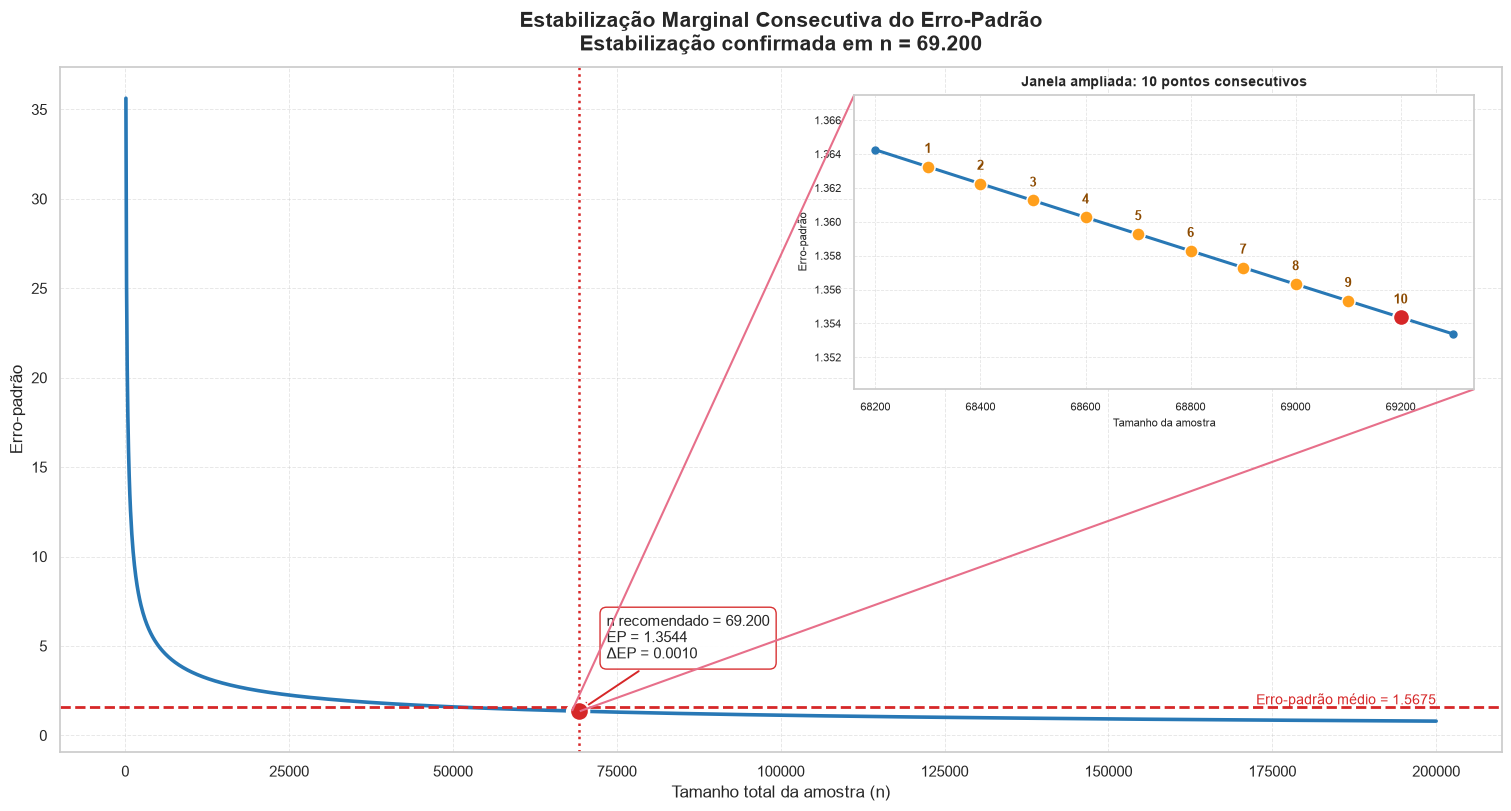

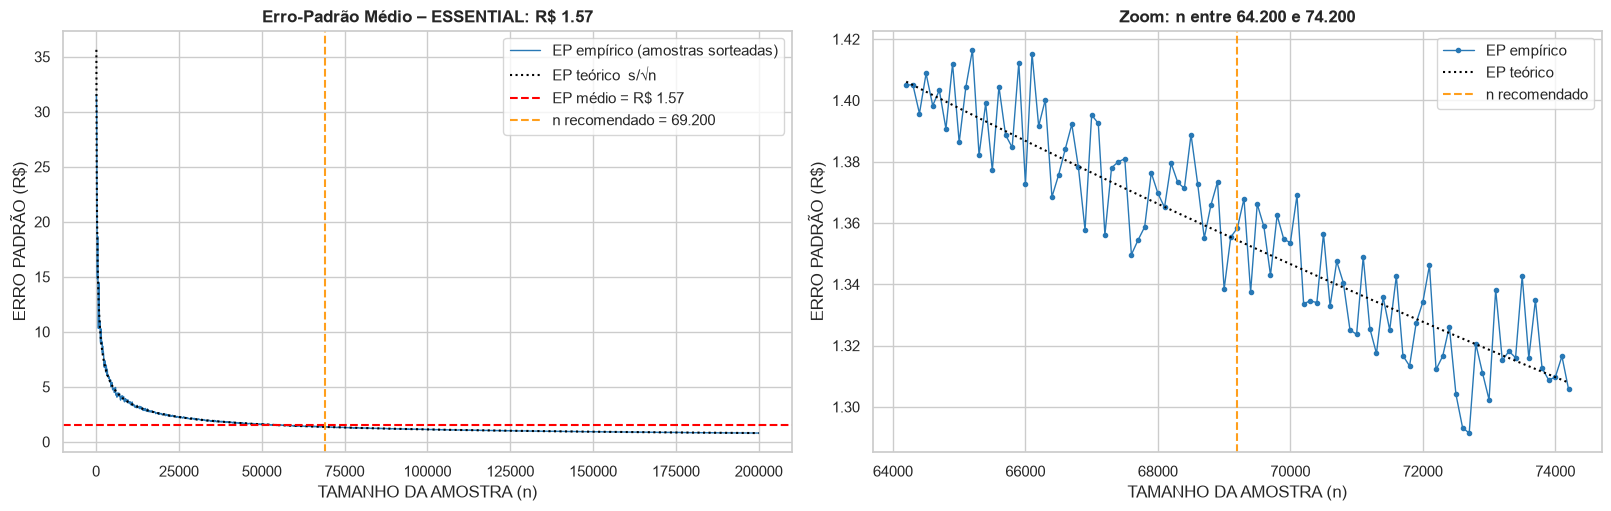

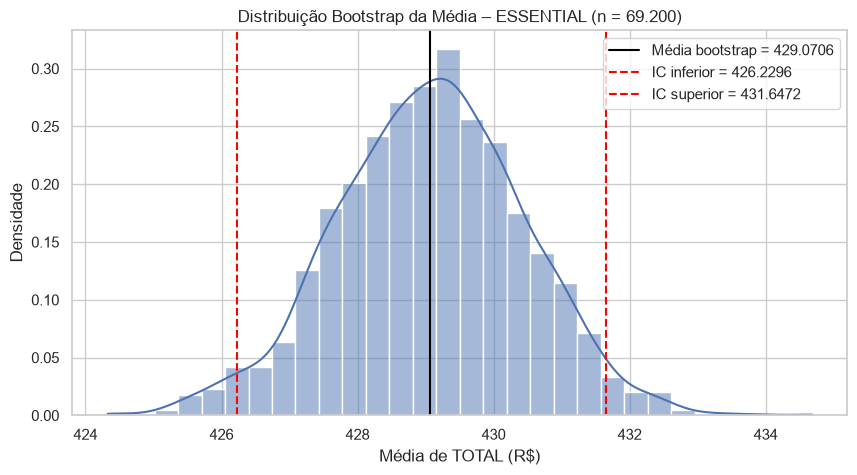

CONFIDENCE INTERVAL
LOW  : 426.2296
HIGH : 431.6472
SE   : 1.3685


## Categoria: **VIP**

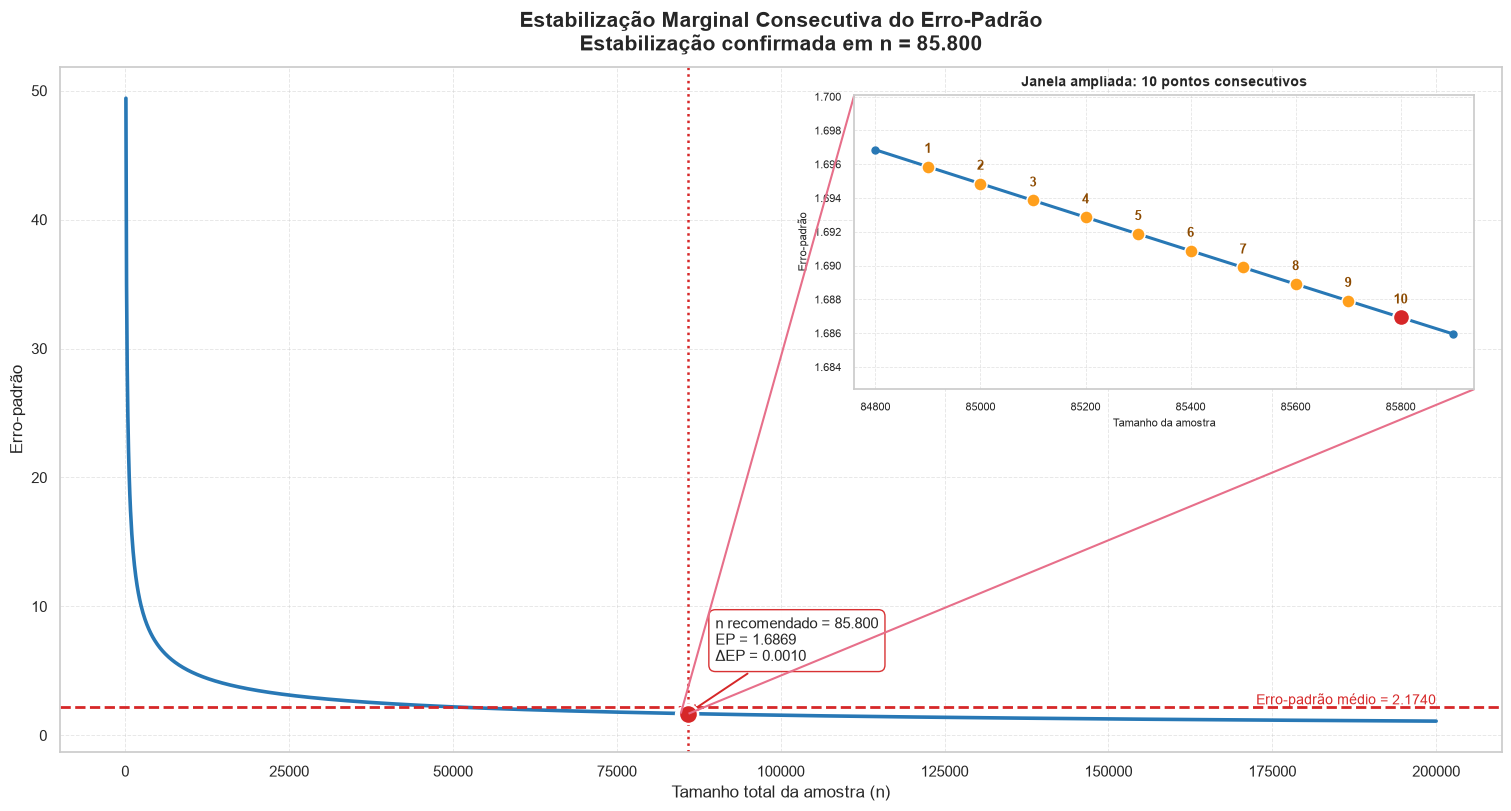

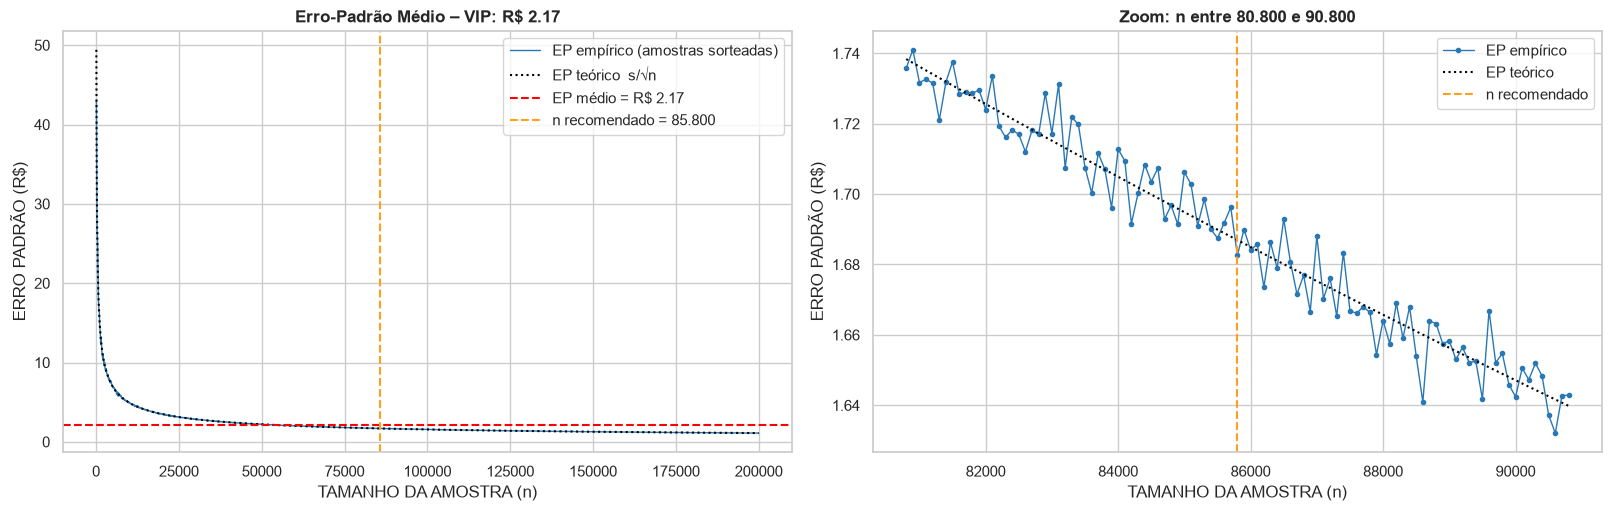

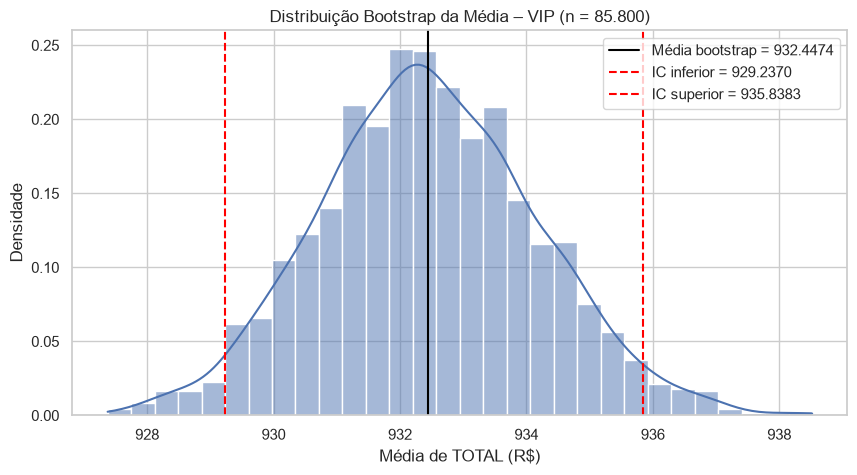

CONFIDENCE INTERVAL
LOW  : 929.2370
HIGH : 935.8383
SE   : 1.7115


## Categoria: **PRIME**

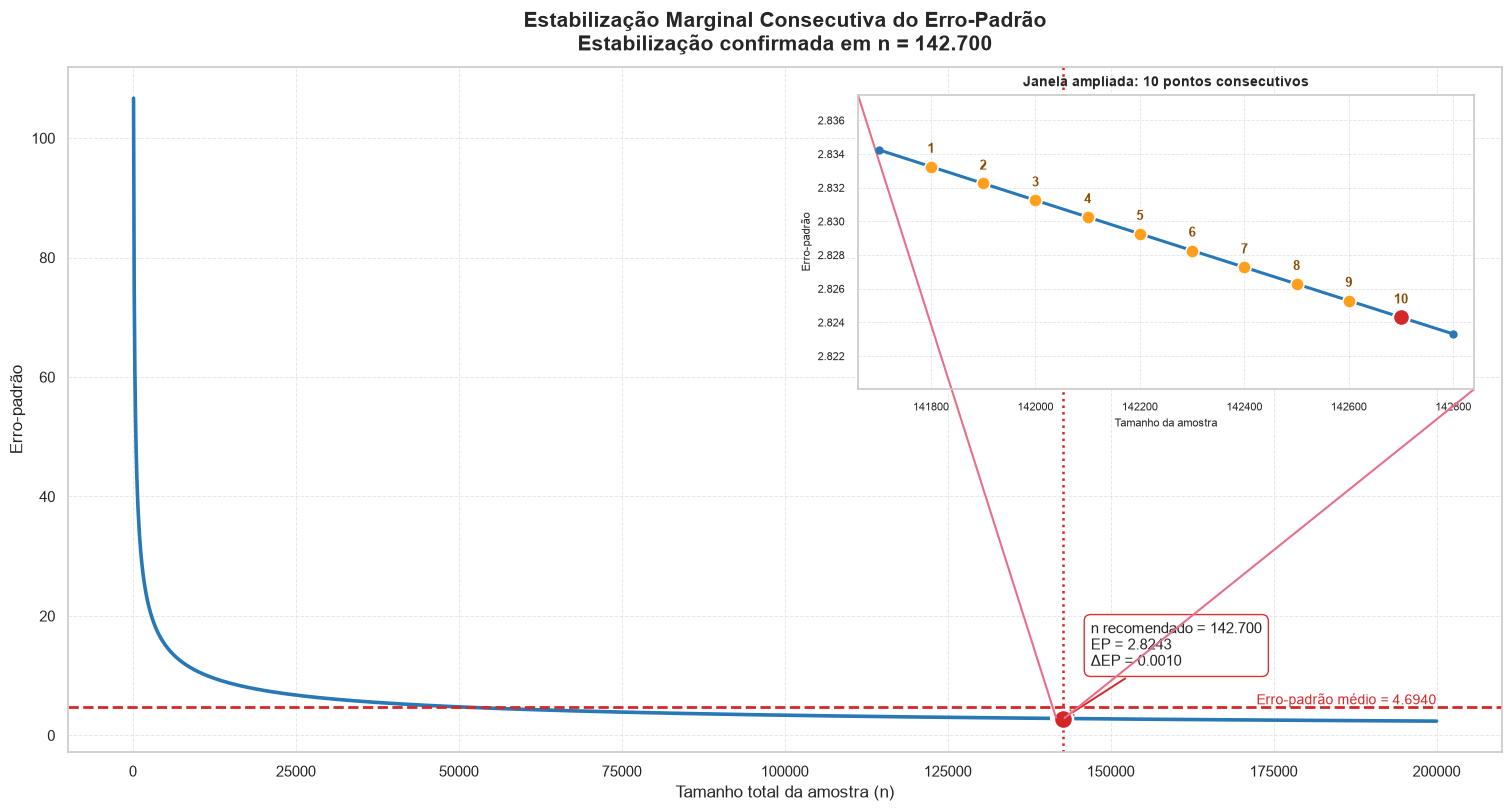

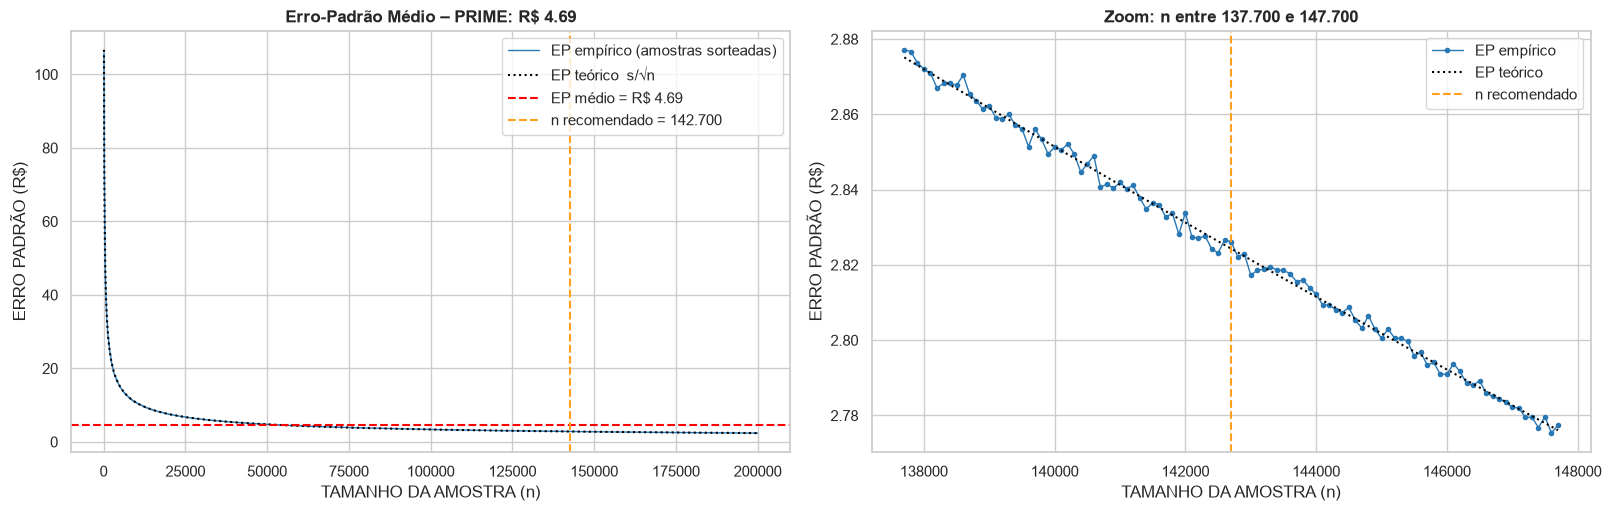

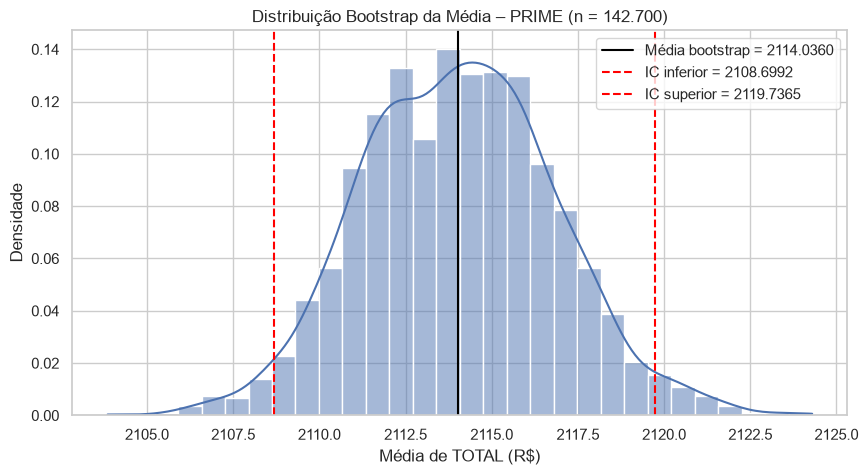

CONFIDENCE INTERVAL
LOW  : 2108.6992
HIGH : 2119.7365
SE   : 2.7928


## Categoria: **GERAL**

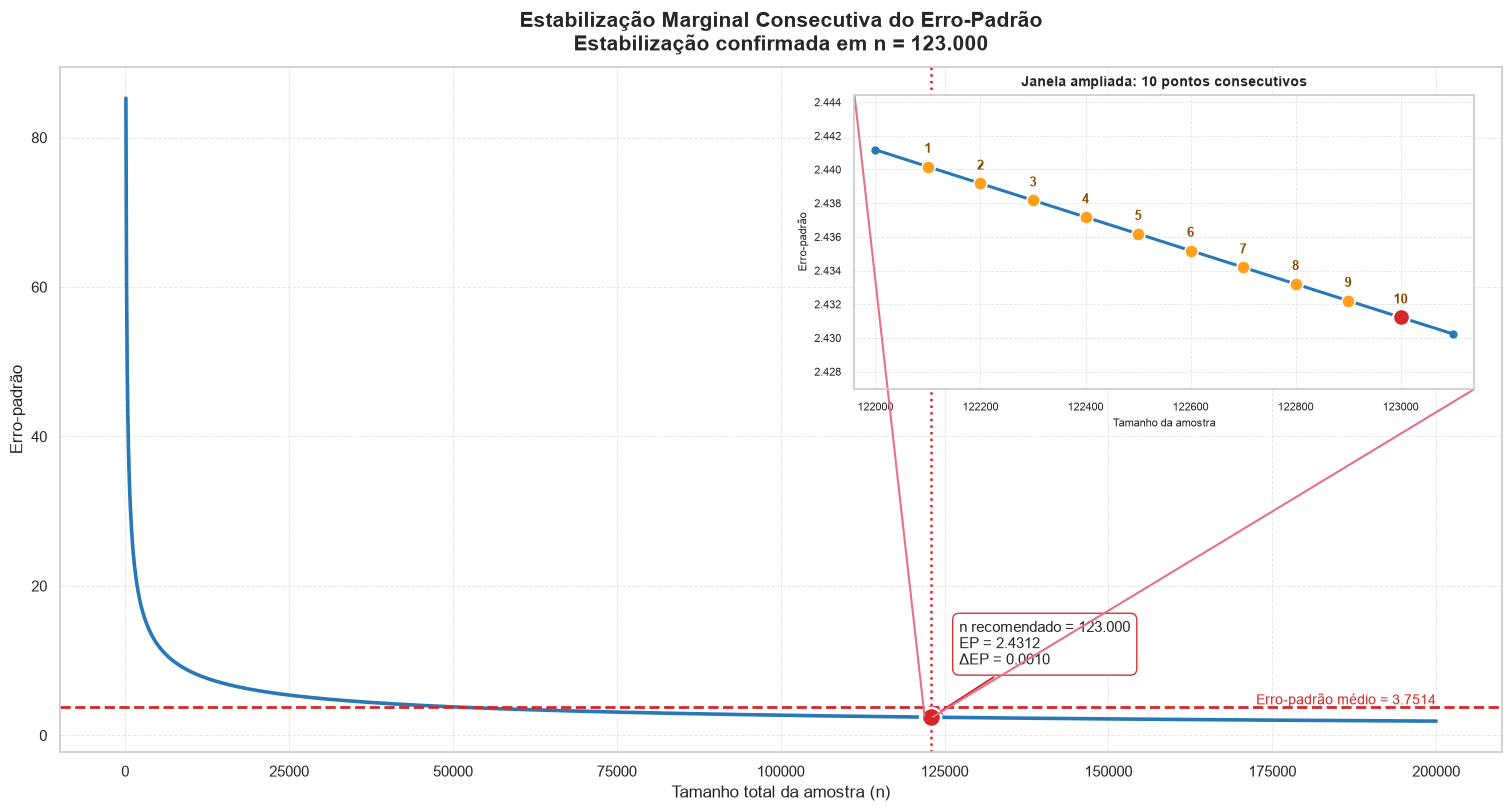

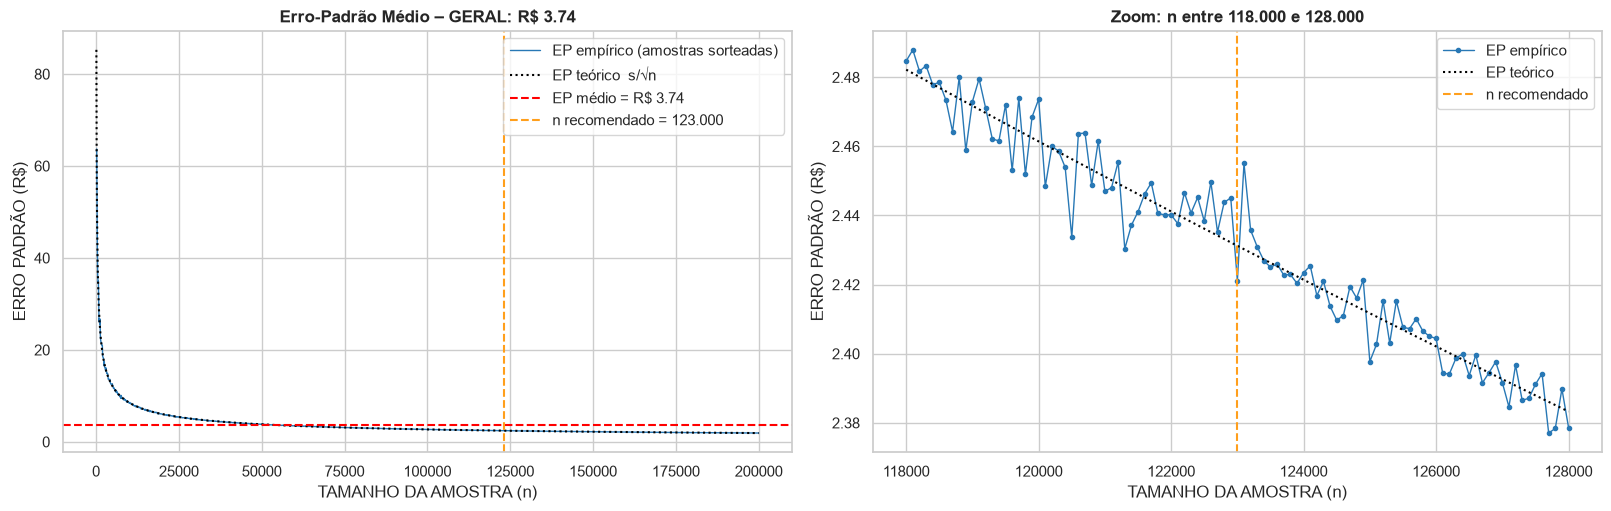

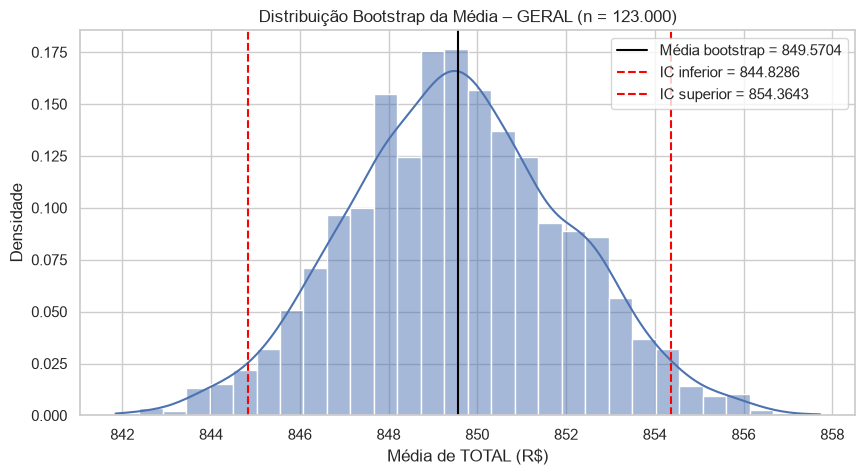

CONFIDENCE INTERVAL
LOW  : 844.8286
HIGH : 854.3643
SE   : 2.4454


## Resumo – Procedimento empírico + Bootstrap (por categoria)

,N população,Média pop. (R$),Desvio-padrão (R$),Início estabilização,n ideal (empírico),EP no n ideal (R$),EP médio da curva (R$),Média amostral (R$),IC95% inferior (R$),IC95% superior (R$),EP bootstrap (R$),Média pop. dentro do IC?
Categoria,,,,,,,,,,,,
ESSENTIAL,649727,428.3320,356.2757,68300,69200,1.3544,1.5681,429.1471,426.2296,431.6472,1.3685,True
VIP,270023,932.2796,494.1313,84900,85800,1.6869,2.1712,932.4999,929.2370,935.8383,1.7115,True
PRIME,200250,2115.2845,1066.8995,141800,142700,2.8243,4.6950,2113.9880,2108.6992,2119.7365,2.7928,True
GERAL,1120000,851.4478,852.6635,122100,123000,2.4312,3.7426,849.6345,844.8286,854.3643,2.4454,True


## Procedimento teórico-empírico: Estratificação + Alocação de Neyman

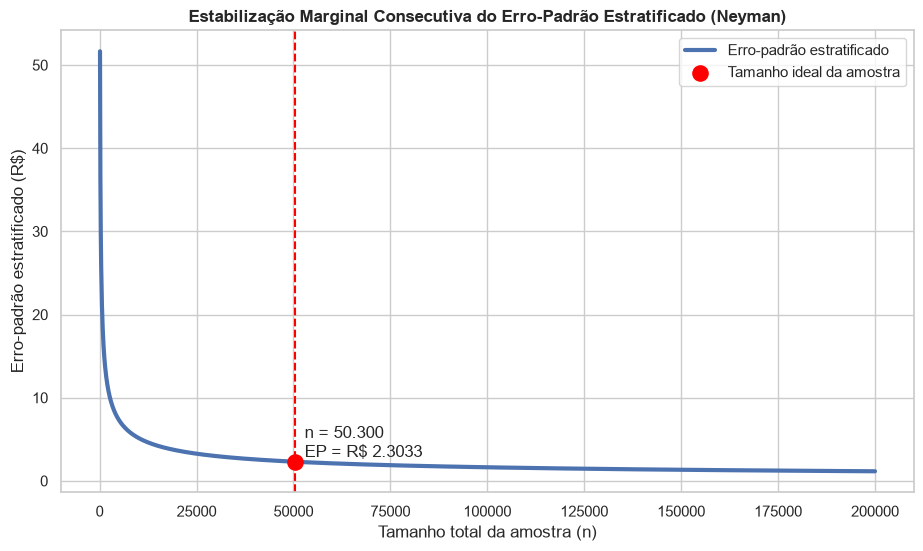

Tamanho ideal (Neyman): n = 50.300
Erro-padrão estratificado no ponto ideal: R$ 2.3033


,Estrato,Peso populacional (Wh),Desvio-padrão (Sh),Peso de Neyman (Wh x Sh),Amostra alocada (nh),Amostra alocada (%)
0,ESSENTIAL,0.5801,356.2757,206.6803,20125,0.4001
1,PRIME,0.1788,1066.8995,190.7559,18575,0.3693
2,VIP,0.2411,494.1313,119.1311,11600,0.2306


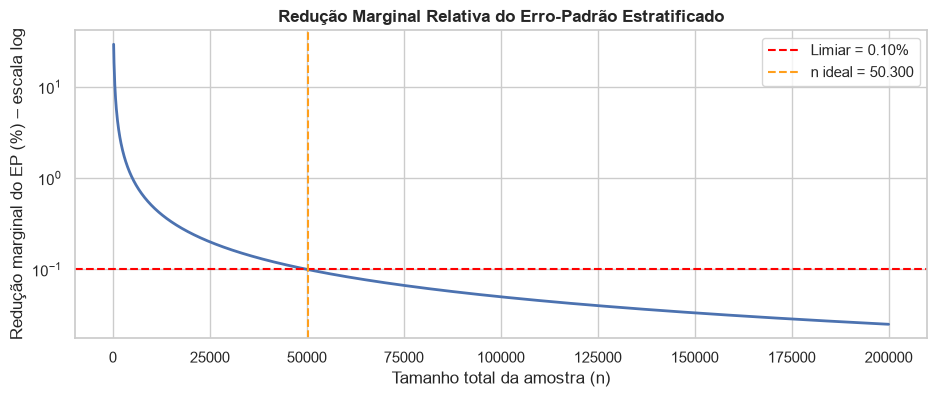

## Precisão dos desenhos amostrais para n = 50.300

,EP da média (R$),Margem de erro 95% (R$),Margem relativa (%),n de AAS com a mesma precisão
Estratificada – Neyman,2.3033,4.5144,0.5302,137047
Estratificada – Proporcional,2.5846,5.0659,0.5950,108833
Aleatória simples (AAS),3.8018,7.4516,0.8752,50300


In [26]:
# Relatório da Atividade A1.1 (modularizado)
res_A1_1 = AtividadeA1_1(table49)
RESULTADOS["A1.1"] = res_A1_1

In [27]:
help(AtividadeA1_1)

Help on function AtividadeA1_1 in module __main__:

AtividadeA1_1(
    df,
    n_min=100,
    n_max=200000,
    step=100,
    threshold_emp=0.001,
    k_emp=10,
    threshold_strat=0.001,
    k_strat=3,
    confidence_level=0.95
)
    ATIVIDADE A1.1 – Determinar o TAMANHO IDEAL da amostra (TARGET y: TOTAL (R$)).

    1) Procedimento EMPÍRICO (optimal_sample_size), para ESSENTIAL, VIP, PRIME e GERAL:
       EP(n) = s/√n; n ideal = ponto em que a redução marginal
       ΔEP(n) = EP(n-100) - EP(n) fica <= threshold_emp (R$ 0,001)
       por k_emp (10) incrementos consecutivos.
       + Gráfico do ERRO-PADRÃO MÉDIO (sorteios reais sem reposição – TÓPICO I).
       + ANÁLISE BOOTSTRAP da média numa amostra do tamanho recomendado
         (Intervalo de confiança e Erro-padrão).

    2) Procedimento TEÓRICO-EMPÍRICO (optimal_stratified_sample_size):
       estratificação por TIPO DA CONTA + alocação ótima de Neyman +
       redução marginal RELATIVA do EP estratificado < threshold_strat (0,1%

### RESPOSTA A1.1 – Qual é o "Tamanho Ideal" da amostra?

**Procedimento empírico** (`optimal_sample_size`, ΔEP ≤ R$ 0,001 por 10 incrementos consecutivos de 100):

| Categoria | s (R$) | n ideal | EP no n ideal | IC 95% bootstrap da média | EP bootstrap |
|---|---|---|---|---|---|
| ESSENTIAL | 356,28 | 69.200 | R$ 1,35 | [426,23 ; 431,65] | R$ 1,37 |
| VIP | 494,13 | 85.800 | R$ 1,69 | [929,24 ; 935,84] | R$ 1,71 |
| PRIME | 1.066,90 | 142.700 | R$ 2,82 | [2.108,70 ; 2.119,74] | R$ 2,79 |
| GERAL | 852,66 | 123.000 | R$ 2,43 | [844,83 ; 854,36] | R$ 2,45 |

* Nas 4 categorias a **média populacional está dentro do IC 95%** e o EP bootstrap ≈ EP teórico s/√n → as curvas são confiáveis.
* O critério absoluto (R$ 0,001) depende do desvio-padrão: quanto mais variável o estrato (PRIME), maior o n exigido.

**Procedimento teórico-empírico** (`optimal_stratified_sample_size`: estratificação por TIPO DA CONTA + Neyman, redução relativa < 0,1% por 3 pontos):

* **n ideal = 50.300 notas fiscais**, EP estratificado = **R$ 2,30** (margem de erro 95% = ±R$ 4,51 ≈ ±0,53% da média).
* Alocação de Neyman: ESSENTIAL 20.125 (40,0%) | PRIME 18.575 (36,9%) | VIP 11.600 (23,1%) – o PRIME, embora seja só 17,9% da população, recebe 36,9% da amostra por ter o maior desvio-padrão.
* Com 50.300 notas, a amostra estratificada de Neyman tem a **mesma precisão de uma amostra aleatória simples de ~137 mil** notas (o empírico GERAL pediu 123 mil).

✅ **TAMANHO IDEAL: n = 50.300 notas fiscais (amostra estratificada por TIPO DA CONTA)** – equivale a ~10 dias da entrada diária de 5.000 notas.

#### Definição de SAMPLE 1 e SAMPLE 2 (tamanho ideal, estratificadas e disjuntas)

In [28]:
# SAMPLE 1 e SAMPLE 2: duas amostras estratificadas, disjuntas, com o TAMANHO IDEAL
N_IDEAL = res_A1_1["n_ideal"]
SAMPLE_1, SAMPLE_2 = gerar_amostras_estratificadas(table49, N_IDEAL)

validacao = pd.DataFrame({
    "N população": table49[ESTRATO].value_counts(),
    "n SAMPLE 1": SAMPLE_1[ESTRATO].value_counts(),
    "n SAMPLE 2": SAMPLE_2[ESTRATO].value_counts(),
    "Média pop. (R$)": table49.groupby(ESTRATO)[TARGET].mean(),
    "Média SAMPLE 1 (R$)": SAMPLE_1.groupby(ESTRATO)[TARGET].mean(),
    "Média SAMPLE 2 (R$)": SAMPLE_2.groupby(ESTRATO)[TARGET].mean(),
})
validacao.loc["GERAL"] = [len(table49), len(SAMPLE_1), len(SAMPLE_2),
                          table49[TARGET].mean(), SAMPLE_1[TARGET].mean(), SAMPLE_2[TARGET].mean()]
validacao["Erro relativo S1 (%)"] = (validacao["Média SAMPLE 1 (R$)"] / validacao["Média pop. (R$)"] - 1) * 100
validacao["Erro relativo S2 (%)"] = (validacao["Média SAMPLE 2 (R$)"] / validacao["Média pop. (R$)"] - 1) * 100
print(f"SAMPLE 1: {len(SAMPLE_1):,} linhas | SAMPLE 2: {len(SAMPLE_2):,} linhas | "
      f"notas fiscais em comum: {len(set(SAMPLE_1['NOTA FISCAL']) & set(SAMPLE_2['NOTA FISCAL']))}")
RESULTADOS["validacao_amostras"] = validacao
validacao.round(4)

SAMPLE 1: 50,300 linhas | SAMPLE 2: 50,300 linhas | notas fiscais em comum: 0


,N população,n SAMPLE 1,n SAMPLE 2,Média pop. (R$),Média SAMPLE 1 (R$),Média SAMPLE 2 (R$),Erro relativo S1 (%),Erro relativo S2 (%)
TIPO DA CONTA,,,,,,,,
ESSENTIAL,649727.0,29180.0,29180.0,428.3320,426.4763,429.5325,-0.4332,0.2803
PRIME,200250.0,8993.0,8993.0,2115.2845,2100.7895,2135.9598,-0.6853,0.9774
VIP,270023.0,12127.0,12127.0,932.2796,933.6279,928.8615,0.1446,-0.3666
GERAL,1120000.0,50300.0,50300.0,851.4478,848.0931,855.0049,-0.3940,0.4178


**SAMPLE 1 e SAMPLE 2**: duas amostras de **50.300** notas fiscais cada, estratificadas por TIPO DA CONTA, **disjuntas** (nenhuma nota em comum) e sorteadas com seed 42.

* Foi usada **alocação proporcional** (ESSENTIAL 29.180 | VIP 12.127 | PRIME 8.993): ela é autoponderada, isto é, mantém as proporções de SEXO, REGIÃO, OPINIÃO etc. da população, o que permite fazer a estatística descritiva (A2) e a pesquisa de satisfação (A3) diretamente. O custo é pequeno: EP de R$ 2,58 contra R$ 2,30 da alocação de Neyman.
* Erro relativo da média de TOTAL em relação à população: **−0,39% (S1)** e **+0,42% (S2)**, dentro da margem esperada (±0,6%).

###Atividade A1.2: Analisar os outliers

### Outliers de TOTAL (R$) – IQR e Z-score

n  Limite inf. IQR (R$)  Limite sup. IQR (R$)  Outliers IQR  % IQR  Outliers |z|>3   % z  Média c/ outliers (R$)  Média s/ outliers IQR (R$)  Viés ao remover (%)
Base      Categoria                                                                                                                                                                         
POPULAÇÃO ESSENTIAL   649727               -141.78                890.24         29114   4.48           16624  2.56                  428.33                      364.96               -14.79
          VIP         270023               -386.31               2148.76          8274   3.06            5812  2.15                  932.28                      876.20                -6.01
          PRIME       200250              -1367.95               5545.28             2   0.00              10  0.00                 2115.28                     2115.25                -0.00
          GERAL      1120000               -795.51               2189.58        106948   9.55           29263  2.61                  851.45                      619.33               -27.26
SAMPLE 1  ESSENTIAL    29180               -136.52                886.63          1276   4.37             743  2.55                  426.48                      364.30               -14.58
          VIP          12127               -402.59               2165.35           382   3.15             256  2.11                  933.63                      876.71                -6.10
          PRIME         8993              -1353.47               5485.89             0   0.00               1  0.01                 2100.79                     2100.79                 0.00
          GERAL        50300               -794.07               2185.95          4809   9.56            1311  2.61                  848.09                      617.52               -27.19
SAMPLE 2  ESSENTIAL    29180               -132.27                886.05          1314   4.50             743  2.55                  429.53                      365.68               -14.86
          VIP          12127               -398.40               2154.58           377   3.11             261  2.15                  928.86                      872.72                -6.04
          PRIME         8993              -1303.50               5542.58             0   0.00               0  0.00                 2135.96                     2135.96                 0.00
          GERAL        50300               -803.17               2202.64          4776   9.50            1339  2.66                  855.00                      622.63               -27.18

### Outliers da categoria GERAL (TOTAL > R$ 2,189.58) por TIPO DA CONTA

,% dos outliers GERAIS
TIPO DA CONTA,
PRIME,85.44
VIP,7.37
ESSENTIAL,7.19


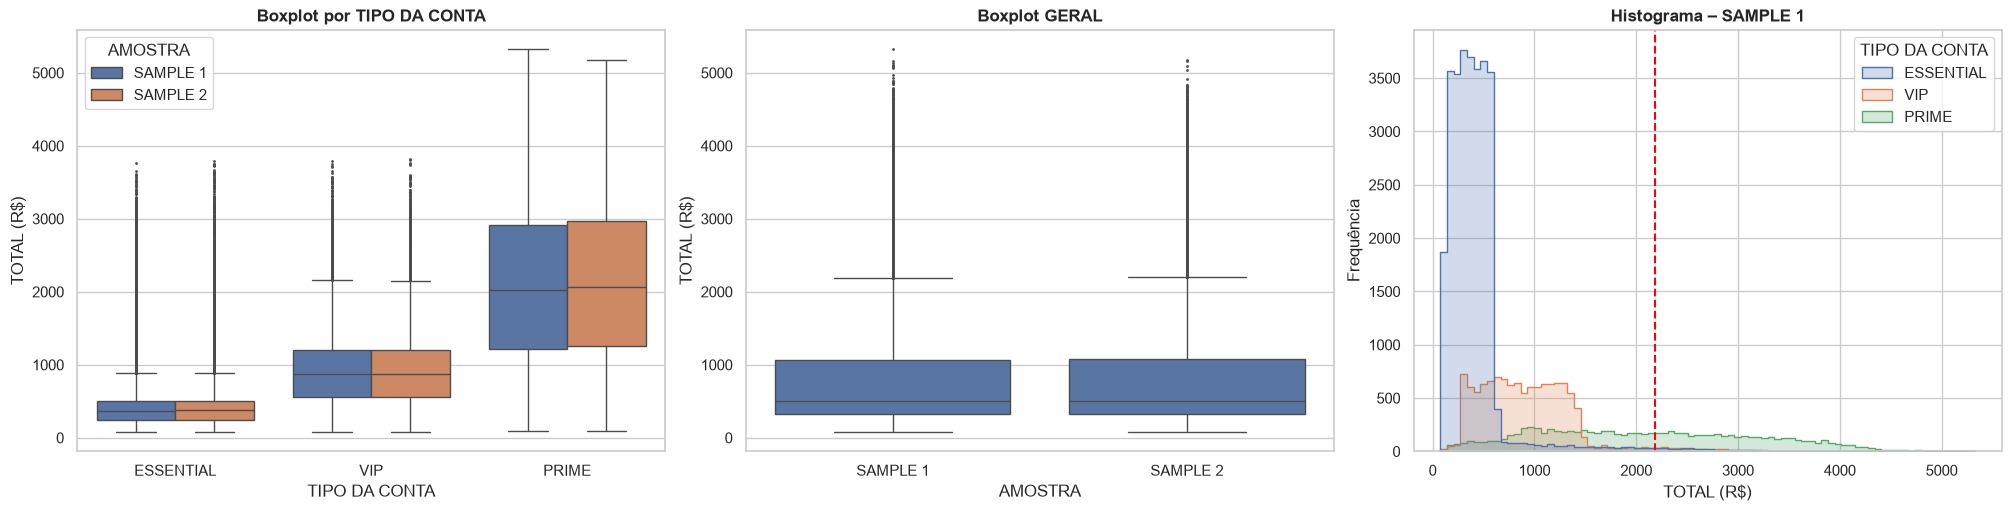

### Qualidade dos dados: valores negativos (impossíveis) nas variáveis MEAN:*

,Qtd. negativos (população),% da base
MEAN: malic_acid,20069,1.792
MEAN: total_phenols,130,0.012
MEAN: flavanoids,23284,2.079
MEAN: nonflavanoid_phenols,1954,0.174
MEAN: proanthocyanins,2972,0.265
MEAN: color_intensity,16194,1.446
MEAN: hue,10,0.001
MEAN: od280/od315_of_diluted_wines,119,0.011
MEAN: proline,9719,0.868


In [29]:
res_A1_2 = AtividadeA1_2(table49, SAMPLE_1, SAMPLE_2)
RESULTADOS["A1.2"] = res_A1_2

### CONCLUSÃO A1.2 – Outliers

* **Por estrato (IQR)**: ESSENTIAL 4,5% | VIP 3,1% | PRIME ≈ 0%. Z-score (|z|>3): 2,6% | 2,2% | 0%.
* **GERAL**: 9,6% das notas passam do limite superior (TOTAL > R$ 2.189,58), mas **85,4% delas são clientes PRIME**: não são erros, são o comportamento normal do estrato de maior gasto. Esses "outliers" aparecem justamente porque a população mistura estratos diferentes, e isso reforça a estratificação.
* Retirar os outliers baixaria a média GERAL em **27%** (de R$ 851 para R$ 619), ou seja, criaria um viés grave. **Decisão: manter os outliers** (são compras válidas, a assimetria à direita é real).
* SAMPLE 1 e SAMPLE 2 reproduzem as mesmas taxas de outliers da população, o que é mais um sinal de representatividade.
* ⚠️ **Qualidade dos dados**: as variáveis físico-químicas MEAN:* têm valores negativos, fisicamente impossíveis (por exemplo flavanoids 2,1%, malic_acid 1,8%, color_intensity 1,4%). Eles precisam de tratamento antes da modelagem (Parte 2).

###Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

**Objetivo dos testes A1.3:** verificar se duas amostras independentes do **tamanho ideal (50.300)** são estatisticamente equivalentes entre si. Se forem, o tamanho é suficiente para representar a população com estabilidade. Nível de significância α = 5%.

In [30]:
# SAMPLE 1 e SAMPLE 2 (definidas na A1.1) – resumo
pd.DataFrame({
    "n": [len(SAMPLE_1), len(SAMPLE_2)],
    "Média TOTAL (R$)": [SAMPLE_1[TARGET].mean(), SAMPLE_2[TARGET].mean()],
    "Desvio-padrão (R$)": [SAMPLE_1[TARGET].std(), SAMPLE_2[TARGET].std()],
    "Mediana (R$)": [SAMPLE_1[TARGET].median(), SAMPLE_2[TARGET].median()],
}, index=["SAMPLE 1", "SAMPLE 2"]).round(4)

,n,Média TOTAL (R$),Desvio-padrão (R$),Mediana (R$)
SAMPLE 1,50300,848.0931,848.3947,510.285
SAMPLE 2,50300,855.0049,858.2173,510.410


#### A1.3.1: Teste de Normalidade

Nesta ETAPA, você deve fazer o **TESTE DE HIPÓTESE DE NORMALIDADE: Anderson-Darling' Test (AD test)** sobre:

*   SAMPLE 1: amostra estratificada proporcional de n = N_IDEAL notas fiscais (seed 42)
*   SAMPLE 2: segunda amostra estratificada de mesmo tamanho, **disjunta** da SAMPLE 1

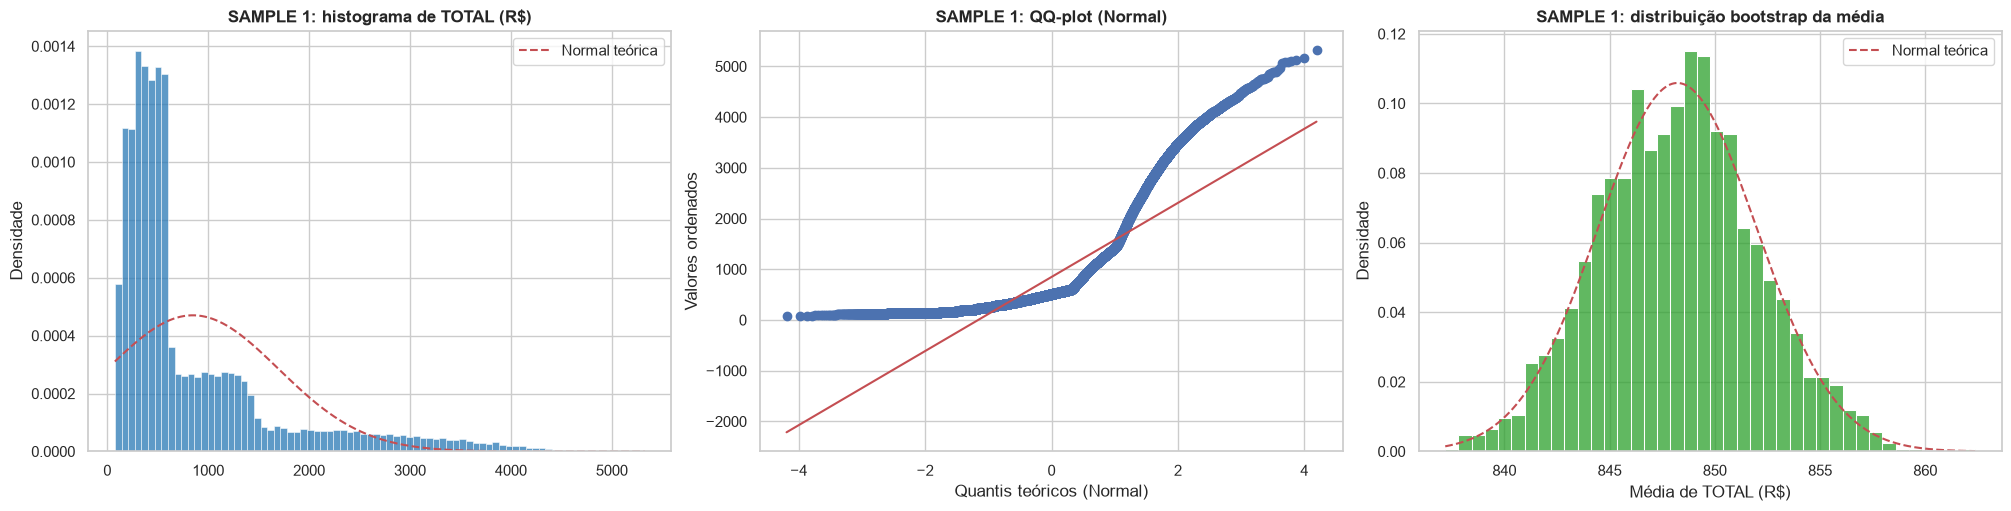

,n,A²,Valor crítico 5%,p_value,Decisão (α = 5%)
Amostra / variável,,,,,
SAMPLE 1 – GERAL (valores),50300,4538.887315,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 1 – ESSENTIAL (valores),29180,2822.936966,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 1 – VIP (valores),12127,204.041718,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 1 – PRIME (valores),8993,57.012064,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 1 – média bootstrap (TLC),2000,0.389108,0.785,0.384037,Não rejeita H0 (normal)


In [31]:
res_AD_S1 = AtividadeA1_3_1(SAMPLE_1, "SAMPLE 1")
RESULTADOS["A1.3.1_S1"] = res_AD_S1

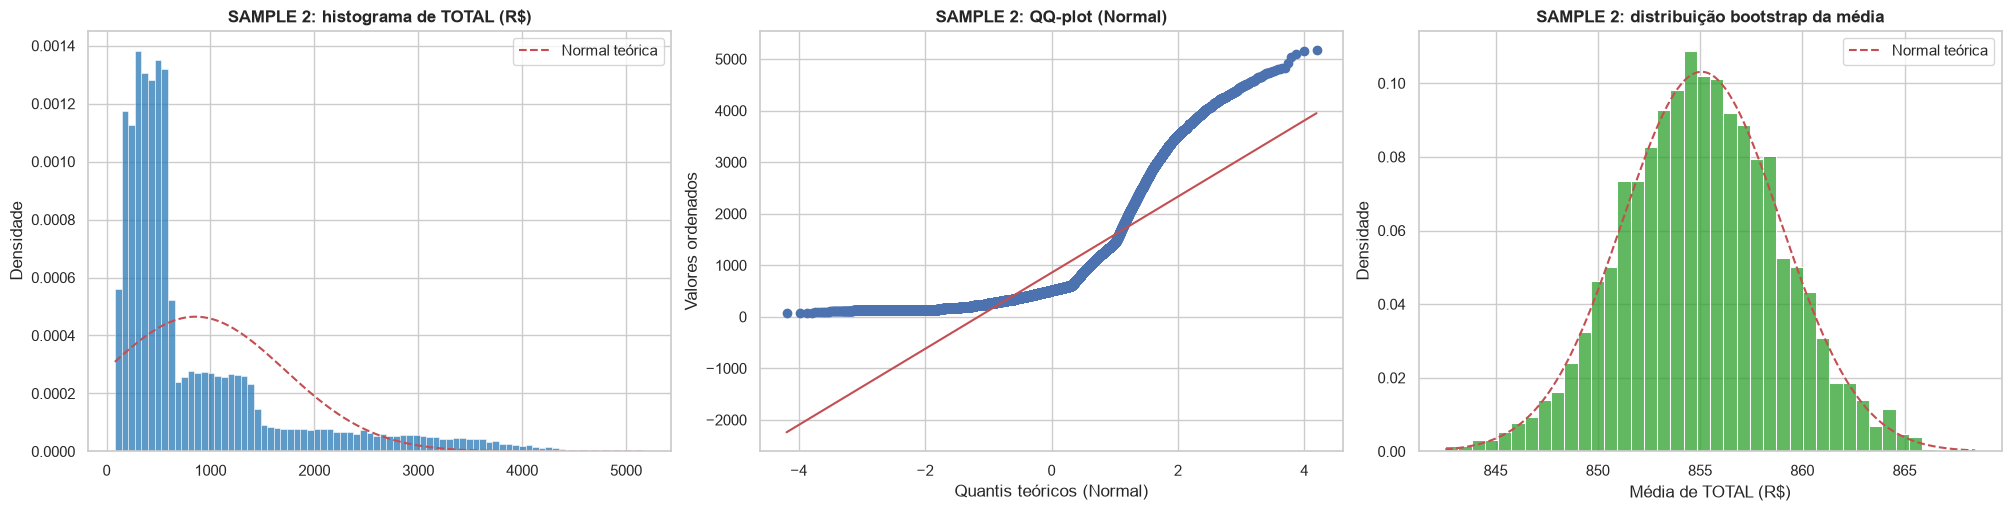

,n,A²,Valor crítico 5%,p_value,Decisão (α = 5%)
Amostra / variável,,,,,
SAMPLE 2 – GERAL (valores),50300,4579.942657,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 2 – ESSENTIAL (valores),29180,2869.506489,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 2 – VIP (valores),12127,199.337729,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 2 – PRIME (valores),8993,53.809804,0.787,0.000000,Rejeita H0 (não normal)
SAMPLE 2 – média bootstrap (TLC),2000,0.152401,0.785,0.959911,Não rejeita H0 (normal)


In [32]:
res_AD_S2 = AtividadeA1_3_1(SAMPLE_2, "SAMPLE 2")
RESULTADOS["A1.3.1_S2"] = res_AD_S2

**CONCLUSÃO A1.3.1 – Normalidade (Anderson-Darling):**
*   **TOTAL (R$) NÃO é normal** em nenhuma amostra nem estrato: A² = 4.539 (S1) e 4.580 (S2), muito acima do valor crítico de 0,787, com p_value ≈ 0. A distribuição tem assimetria à direita (1,98) e é leptocúrtica.
*   A **distribuição bootstrap da MÉDIA é normal** (S1: A² = 0,39, p = 0,38; S2: A² = 0,15, p = 0,96), como prevê o Teorema Central do Limite. Por isso: (1) para **distribuição/independência** usam-se testes **não paramétricos**; (2) para **médias**, testes paramétricos (ANOVA/t) são válidos.

#### A1.3.2: Teste de Independência

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Testes de Independência: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

,H0,Estatística,p_value,Decisão (α = 5%)
Teste,,,,
Pearson,ρ = 0,0.003165,0.477859,Não rejeita H0
Spearman,ρs = 0,-0.007421,0.096043,Não rejeita H0
Kendall Tau,τ = 0,-0.004962,0.095106,Não rejeita H0
Qui-quadrado (quartis),sem associação,14.405311,0.108620,Não rejeita H0


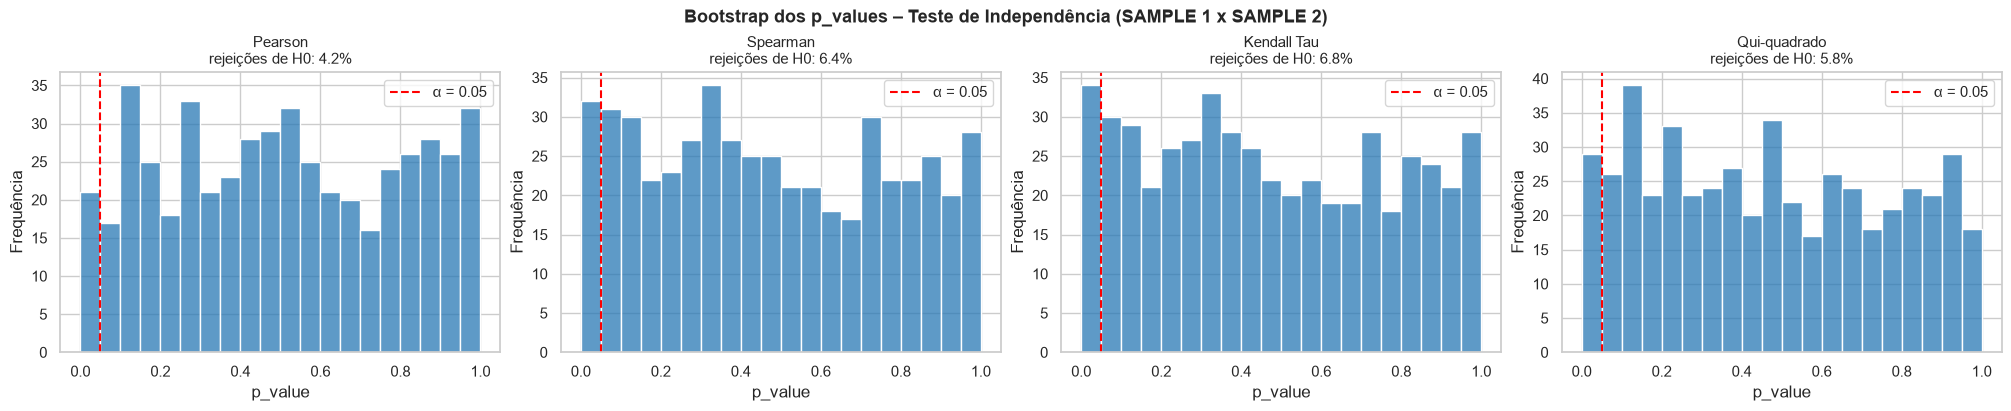

,p_value mediano (bootstrap),Taxa de rejeição de H0 (%)
Pearson,0.5002,4.2
Spearman,0.4478,6.4
Kendall Tau,0.4438,6.8
Qui-quadrado,0.4541,5.8


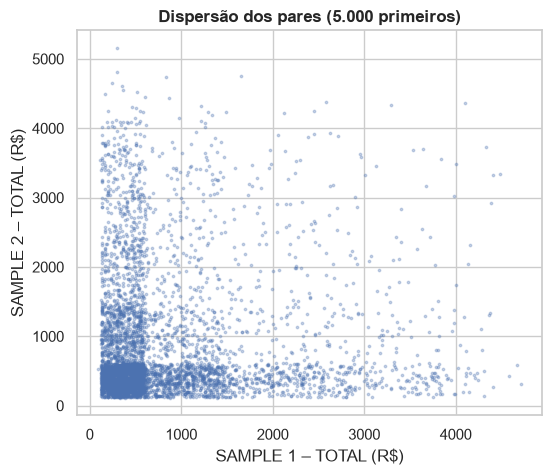

BEST FIT: Spearman  |  p_value = 0.0960  →  SAMPLE 1 e SAMPLE 2 são INDEPENDENTES (não rejeita H0)


In [33]:
# Normalidade (A1.3.1): ambas as amostras são normais?
AMOSTRAS_NORMAIS = bool((res_AD_S1.iloc[0]["Decisão (α = 5%)"].startswith("Não")) and
                        (res_AD_S2.iloc[0]["Decisão (α = 5%)"].startswith("Não")))
res_A1_3_2 = AtividadeA1_3_2(SAMPLE_1, SAMPLE_2, normais=AMOSTRAS_NORMAIS)
RESULTADOS["A1.3.2"] = res_A1_3_2

**RESPONDER: SAMPLE 1 e SAMPLE 2 são INDEPENDENTES ???**

CONCLUIR / RESPONDER AQUI:
*   **BEST FIT: Spearman**, porque os dados não são normais (A1.3.1) e a correlação de Pearson pressupõe normalidade. Resultado: ρs = −0,007, **p_value = 0,096 > 0,05** → não se rejeita H0. Pearson (p = 0,48), Kendall (p = 0,10) e Qui-quadrado (p = 0,11) concordam.
*   Bootstrap dos p_values (500 subamostras): as taxas de rejeição (4,2% a 6,8%) ficam ≈ α = 5% e os p_values são ~uniformes, como esperado sob H0. ✅ **SIM, SAMPLE 1 e SAMPLE 2 são INDEPENDENTES.**

#### A1.3.3: Teste de Distribuição

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste de Mesma Distribuição: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

,H0,Estatística,p_value,Decisão (α = 5%)
Teste,,,,
Kolmogorov-Smirnov,F1 = F2,0.003280,0.948695,Não rejeita H0
Anderson-Darling k-amostras,F1 = F2,-0.404761,0.250000,Não rejeita H0
Cramér-von Mises,F1 = F2,0.068667,0.759782,Não rejeita H0
Qui-quadrado (decis),F1 = F2,3.919208,0.916649,Não rejeita H0


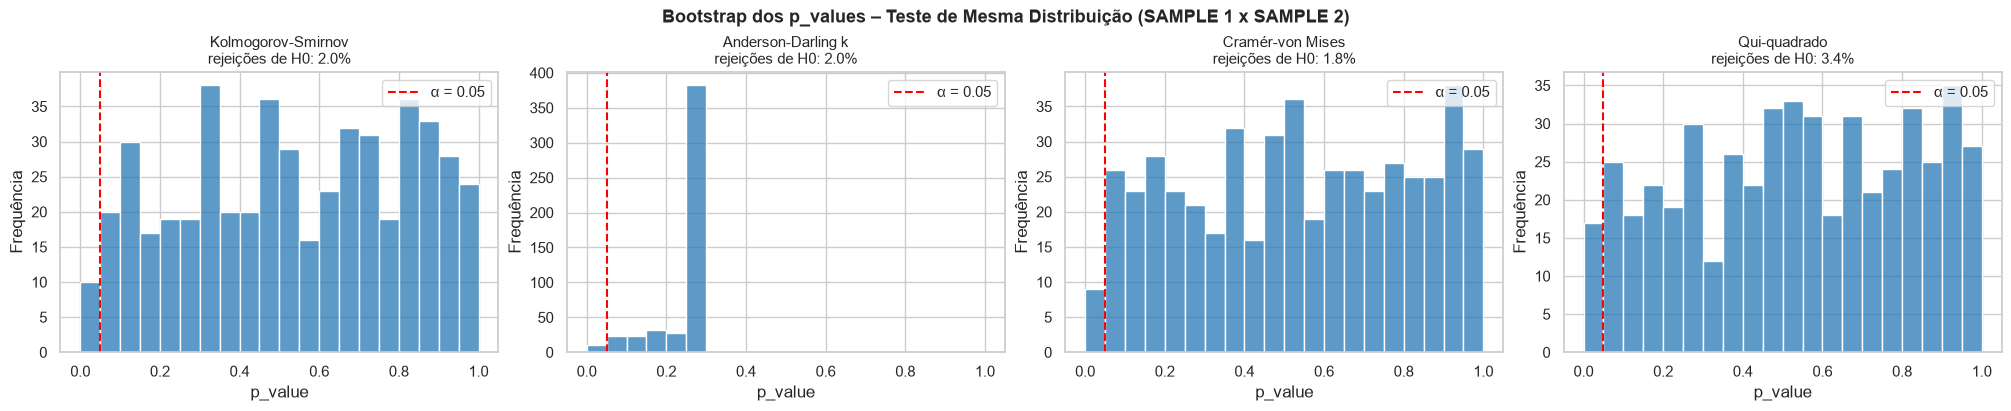

,p_value mediano (bootstrap),Taxa de rejeição de H0 (%)
Kolmogorov-Smirnov,0.5442,2.0
Anderson-Darling k,0.2500,2.0
Cramér-von Mises,0.5357,1.8
Qui-quadrado,0.5368,3.4


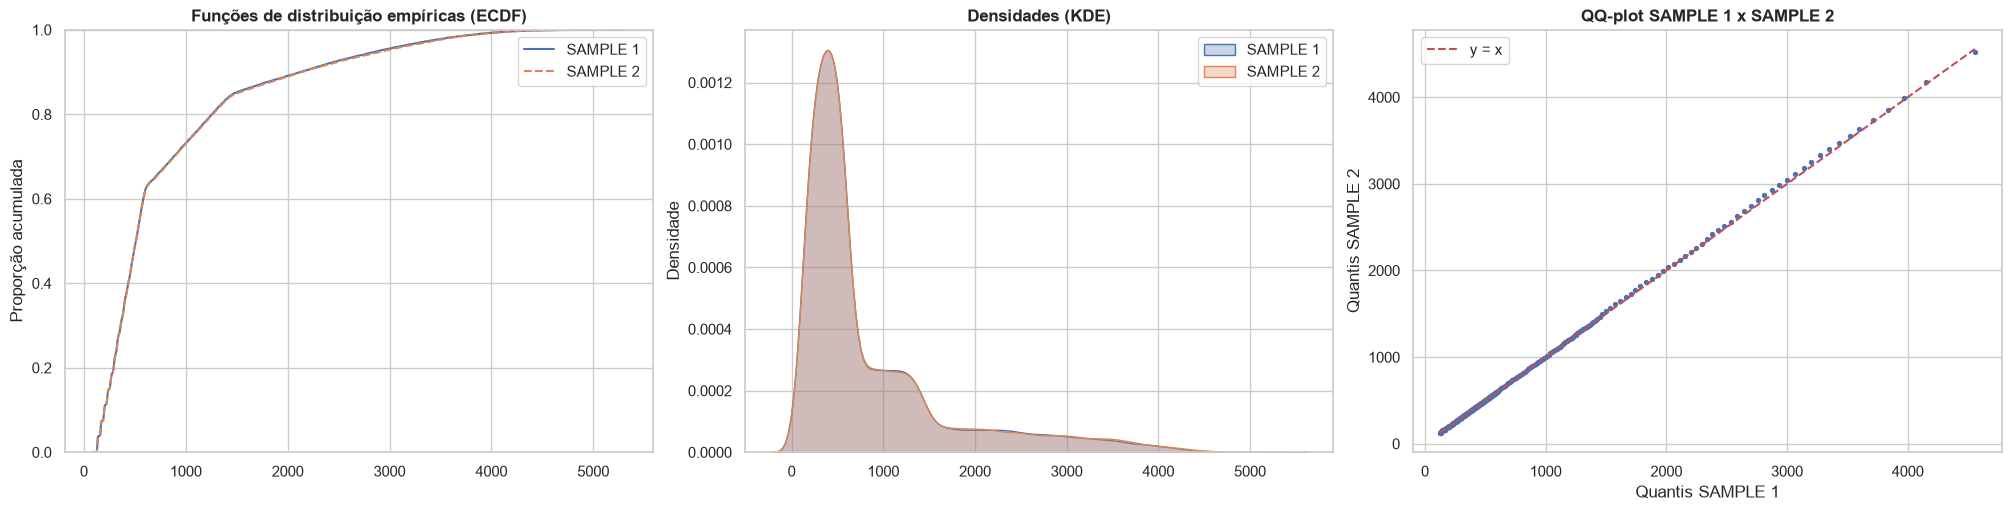

BEST FIT: Kolmogorov-Smirnov  |  p_value = 0.9487  →  SAMPLE 1 e SAMPLE 2 têm a MESMA DISTRIBUIÇÃO (não rejeita H0)


In [34]:
res_A1_3_3 = AtividadeA1_3_3(SAMPLE_1, SAMPLE_2)
RESULTADOS["A1.3.3"] = res_A1_3_3

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem a MESMA DISTRIBUIÇÃO DOS DADOS ???**

CONCLUIR / RESPONDER AQUI:
*   **BEST FIT: Kolmogorov-Smirnov (2 amostras)**: não paramétrico e adequado a uma variável contínua não normal. D = 0,0033, **p_value = 0,949 > 0,05** → não se rejeita H0. Anderson-Darling k-amostras (p ≥ 0,25), Cramér-von Mises (p = 0,76) e Qui-quadrado por decis (p = 0,92) confirmam.
*   Bootstrap dos p_values: taxa de rejeição entre 1,8% e 3,4% (< 5%). As ECDFs e o QQ-plot S1 × S2 ficam sobrepostos na reta y = x. ✅ **SIM, SAMPLE 1 e SAMPLE 2 têm a MESMA DISTRIBUIÇÃO.**

#### A1.3.4: Teste das Médias Amostrais

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste das Médias Amostrais: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

,H0,Estatística,p_value,Decisão (α = 5%)
Teste,,,,
Levene (variâncias),σ1² = σ2²,1.644332e+00,0.199735,Não rejeita H0
ANOVA one-way,μ1 = μ2,1.650033e+00,0.198957,Não rejeita H0
t de Student,μ1 = μ2,-1.284536e+00,0.198957,Não rejeita H0
t de Welch,μ1 = μ2,-1.284536e+00,0.198957,Não rejeita H0
Mann-Whitney U,postos iguais,1.261484e+09,0.439395,Não rejeita H0
Kruskal-Wallis,postos iguais,5.978620e-01,0.439395,Não rejeita H0


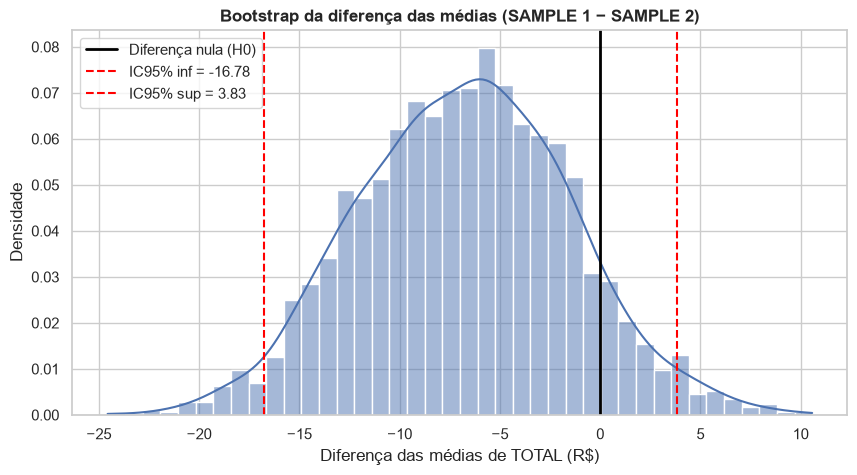

Diferença observada: R$ -6.9118 | IC95%: [-16.7819; 3.8297] | EP: 5.2447


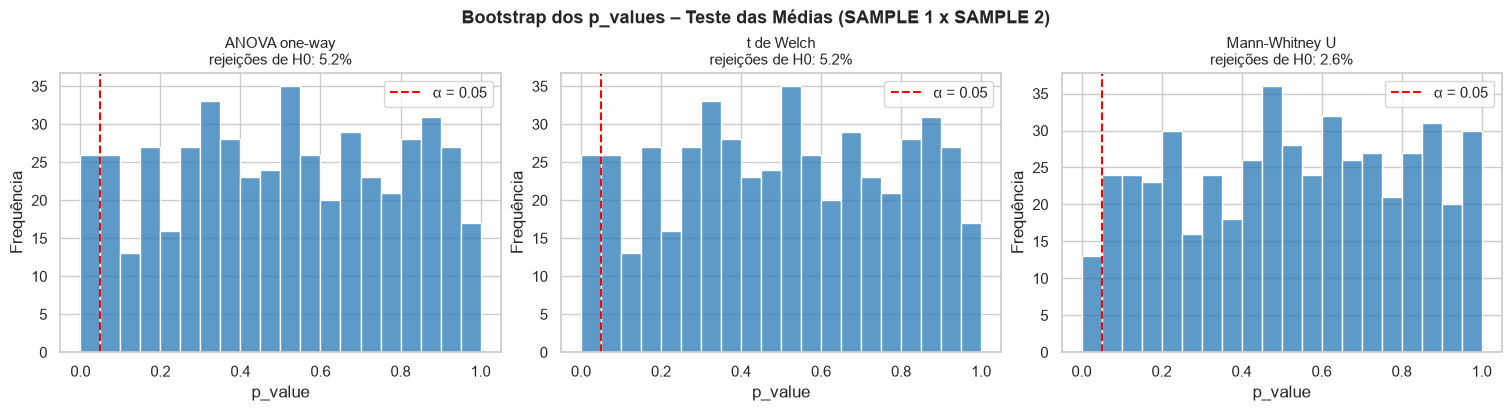

,p_value mediano (bootstrap),Taxa de rejeição de H0 (%)
ANOVA one-way,0.5064,5.2
t de Welch,0.5064,5.2
Mann-Whitney U,0.5277,2.6


**Complemento – ANOVA entre os estratos (justifica a estratificação):**

,H0,Estatística,p_value,Decisão (α = 5%)
Teste,,,,
ANOVA entre estratos (SAMPLE 1),μ_ESS = μ_VIP = μ_PRIME,28995.230996,0.0,Rejeita H0
Kruskal-Wallis entre estratos,postos iguais,25983.624853,0.0,Rejeita H0


BEST FIT: ANOVA one-way  |  p_value = 0.1990  →  SAMPLE 1 e SAMPLE 2 têm as MESMAS MÉDIAS (não rejeita H0)


In [35]:
MEDIAS_NORMAIS = bool(res_AD_S1.iloc[-1]["Decisão (α = 5%)"].startswith("Não") and
                      res_AD_S2.iloc[-1]["Decisão (α = 5%)"].startswith("Não"))
res_A1_3_4 = AtividadeA1_3_4(SAMPLE_1, SAMPLE_2, medias_normais=MEDIAS_NORMAIS)
RESULTADOS["A1.3.4"] = res_A1_3_4

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem as MESMAS MÉDIAS AMOSTRAIS ???**

CONCLUIR / RESPONDER AQUI:
*   **BEST FIT: ANOVA one-way**: as médias bootstrap são normais (TLC) e o Levene (p = 0,20) indica variâncias homogêneas. F = 1,65, **p_value = 0,199 > 0,05** → não se rejeita H0. t de Student e de Welch (p = 0,199) e Mann-Whitney (p = 0,44) concordam.
*   Diferença das médias: R$ −6,91, com IC 95% bootstrap de [−16,78 ; 3,83], que **contém o zero**. Taxa de rejeição no bootstrap: 5,2%. ✅ **SIM, SAMPLE 1 e SAMPLE 2 têm as MESMAS MÉDIAS.**
*   Complemento: a ANOVA **entre os estratos** (ESSENTIAL × VIP × PRIME) dá F = 28.995, p ≈ 0. As médias dos tipos de conta são muito diferentes, o que justifica a estratificação.

##Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

###Atividade A2.1: Analisar as variáveis Quantitativas

### Medidas de resumo – variáveis quantitativas (SAMPLE 1)

,mean,50%,mode,std,CV (%),min,25%,75%,max,range,assimetria,curtose
RENDA BRUTO (R$),7709.25,3364.29,3318.15,6627.44,85.967,1763.10,3239.22,8066.72,30984.75,29221.65,1.411,0.626
TOTAL (R$),848.09,510.28,131.51,848.39,100.035,75.52,323.44,1068.45,5326.89,5251.37,1.975,3.562
NOTA DE SATISFAÇÃO (%),68.98,68.68,68.68,1.37,1.986,68.68,68.68,68.68,89.08,20.40,5.746,37.686
DEPENDENTES,1.06,1.00,1.00,0.96,90.566,0.00,0.00,1.00,4.00,4.00,1.177,1.316
MEAN: alcohol,12.99,13.00,9.78,0.81,6.236,9.78,12.45,13.54,16.62,6.84,0.002,0.033
MEAN: malic_acid,2.33,2.34,-1.97,1.11,47.639,-1.97,1.58,3.08,6.47,8.44,-0.002,-0.031
MEAN: ash,2.37,2.37,1.23,0.27,11.392,1.23,2.18,2.55,3.55,2.32,0.005,-0.005
MEAN: alcalinity_of_ash,19.48,19.49,6.01,3.34,17.146,6.01,17.24,21.74,32.40,26.40,-0.007,0.013
MEAN: magnesium,99.73,99.84,40.29,14.27,14.309,40.29,90.11,109.42,162.43,122.15,-0.028,0.016
MEAN: total_phenols,2.29,2.29,-0.40,0.62,27.074,-0.40,1.87,2.72,5.20,5.61,-0.007,-0.010


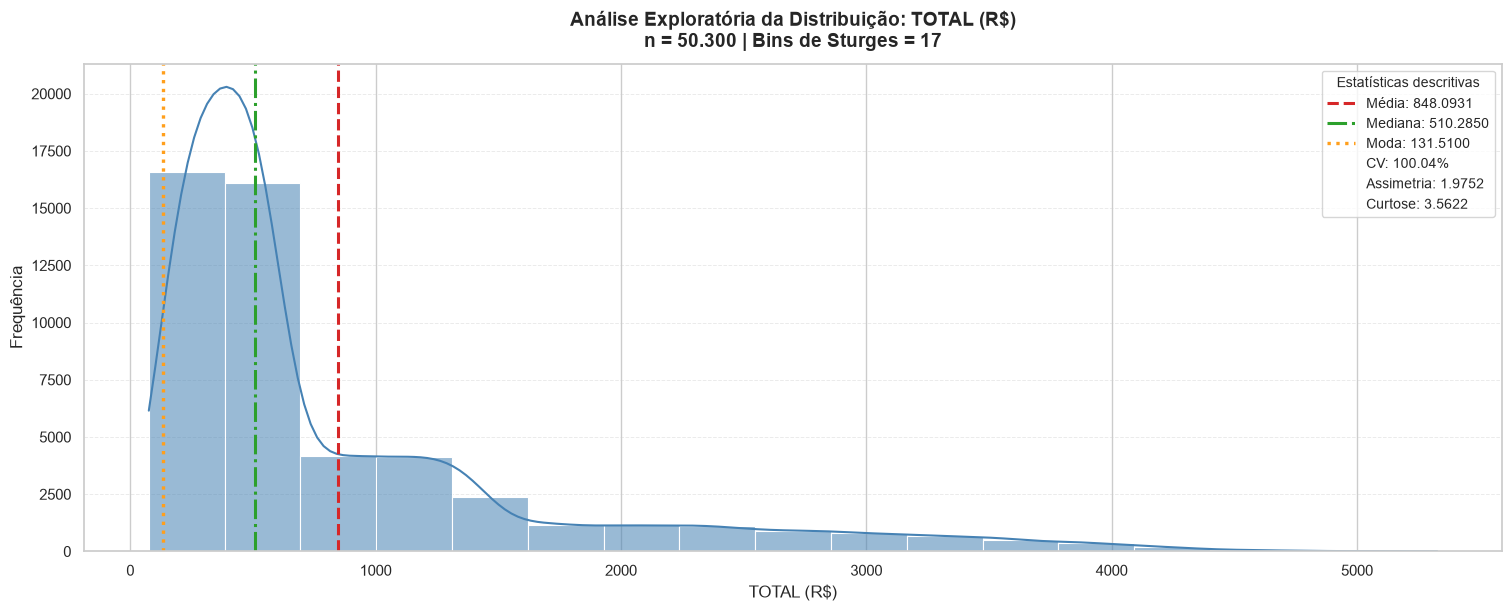


  ANÁLISE EXPLORATÓRIA DOS DADOS: TOTAL (R$)

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 50300
     Mínimo        : 75.5200
     Máximo        : 5326.8900
     Média         : 848.0931
     Mediana       : 510.2850
     Moda          : 131.5100
     Desvio-padrão : 848.3947
     CV            : 100.04%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 1.9752 → Assimetria acentuada à direita (positiva)
     Curtose       : 3.5622 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.739191
     Valor-p       : 1.04186e-66
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




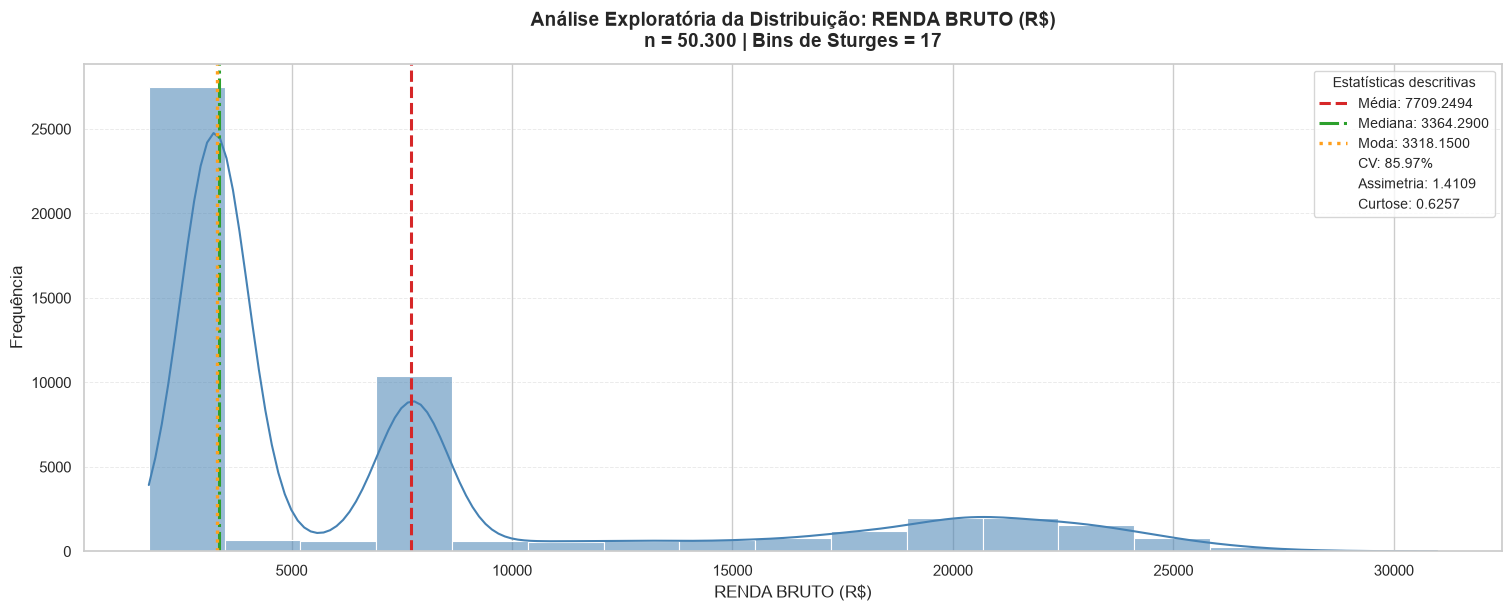


  ANÁLISE EXPLORATÓRIA DOS DADOS: RENDA BRUTO (R$)

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 50300
     Mínimo        : 1763.1000
     Máximo        : 30984.7500
     Média         : 7709.2494
     Mediana       : 3364.2900
     Moda          : 3318.1500
     Desvio-padrão : 6627.4399
     CV            : 85.97%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Alta dispersão relativa (CV ≥ 30%)
     Assimetria    : 1.4109 → Assimetria acentuada à direita (positiva)
     Curtose       : 0.6257 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.710913
     Valor-p       : 9.46276e-69
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




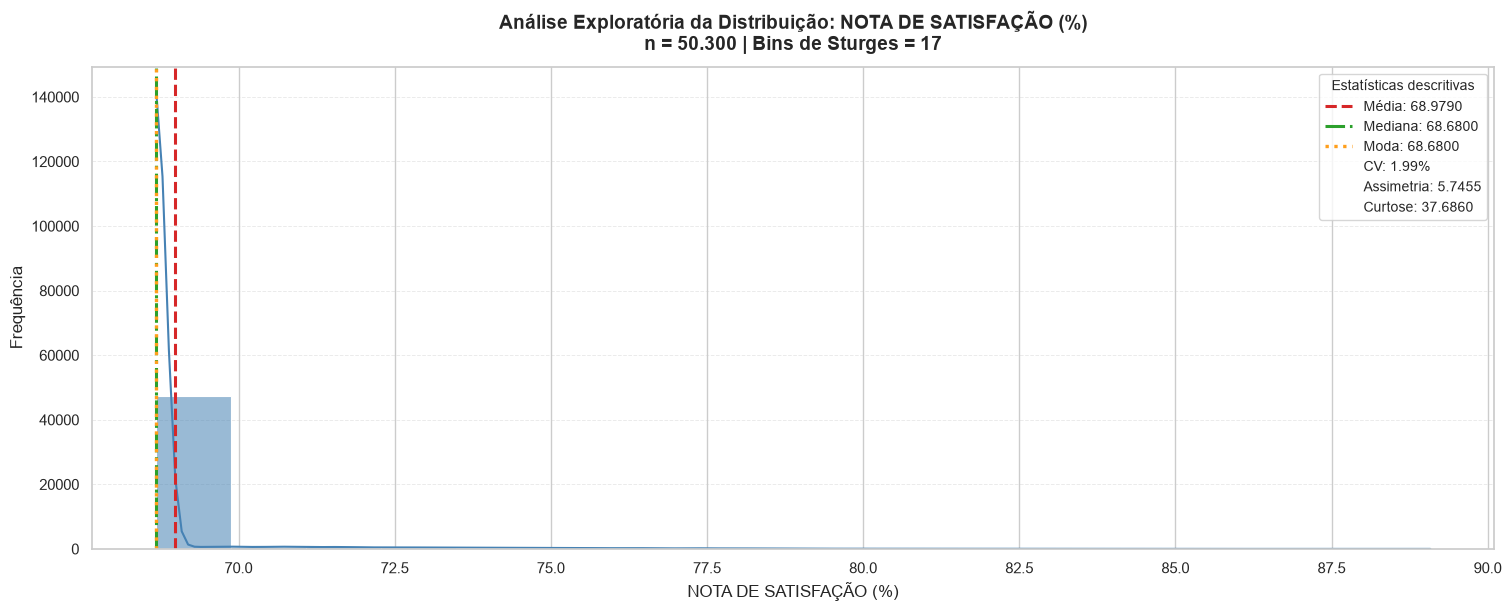


  ANÁLISE EXPLORATÓRIA DOS DADOS: NOTA DE SATISFAÇÃO (%)

  1. ESTATÍSTICAS DESCRITIVAS
     Observações   : 50300
     Mínimo        : 68.6800
     Máximo        : 89.0820
     Média         : 68.9790
     Mediana       : 68.6800
     Moda          : 68.6800
     Desvio-padrão : 1.3731
     CV            : 1.99%

  2. DIAGNÓSTICO EXPLORATÓRIO
     Dispersão     : Baixa dispersão relativa (CV < 15%)
     Assimetria    : 5.7455 → Assimetria acentuada à direita (positiva)
     Curtose       : 37.6860 → LEPTOCÚRTICA: maior concentração central e/ou caudas pesadas
     Heurística    : Não compatível com normalidade pelos critérios heurísticos

  3. TESTE DE SHAPIRO–WILK
     Dados usados  : amostra aleatória reprodutível de 5.000 observações
     Estatística W : 0.237321
     Valor-p       : 1.52122e-89
     Significância : 0.05
     Conclusão     : Rejeita-se H₀: há evidências de que os dados não seguem uma distribuição normal ao nível de 5%.




,Assimetria,Curtose,Dispersão,Shapiro-Wilk
TOTAL (R$),Assimetria acentuada à direita (positiva),LEPTOCÚRTICA: maior concentração central e/ou ...,Alta dispersão relativa (CV ≥ 30%),Rejeita-se H₀: há evidências de que os dados n...
RENDA BRUTO (R$),Assimetria acentuada à direita (positiva),LEPTOCÚRTICA: maior concentração central e/ou ...,Alta dispersão relativa (CV ≥ 30%),Rejeita-se H₀: há evidências de que os dados n...
NOTA DE SATISFAÇÃO (%),Assimetria acentuada à direita (positiva),LEPTOCÚRTICA: maior concentração central e/ou ...,Baixa dispersão relativa (CV < 15%),Rejeita-se H₀: há evidências de que os dados n...


### TOTAL, RENDA e NOTA por TIPO DA CONTA

TOTAL (R$)                   RENDA BRUTO (R$)                    NOTA DE SATISFAÇÃO (%)             
                    mean   median      std             mean    median      std                   mean median   std
TIPO DA CONTA                                                                                                     
ESSENTIAL         426.48   370.99   352.93          3865.55   3257.04  2643.05                  68.68  68.68  0.00
PRIME            2100.79  2030.14  1065.11         19119.36  20689.74  5719.23                  70.35  68.68  2.87
VIP               933.63   874.88   495.77          8496.60   7782.38  2898.75                  68.68  68.68  0.10

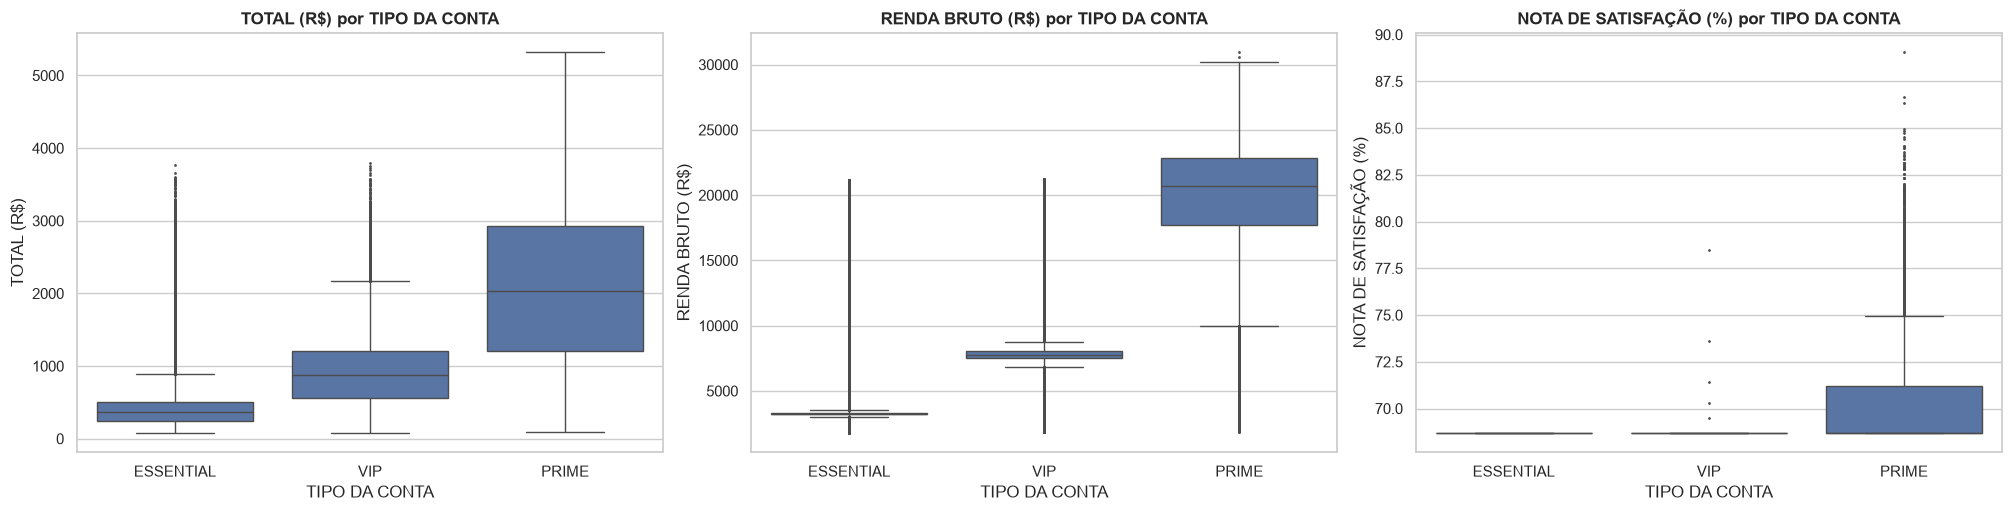

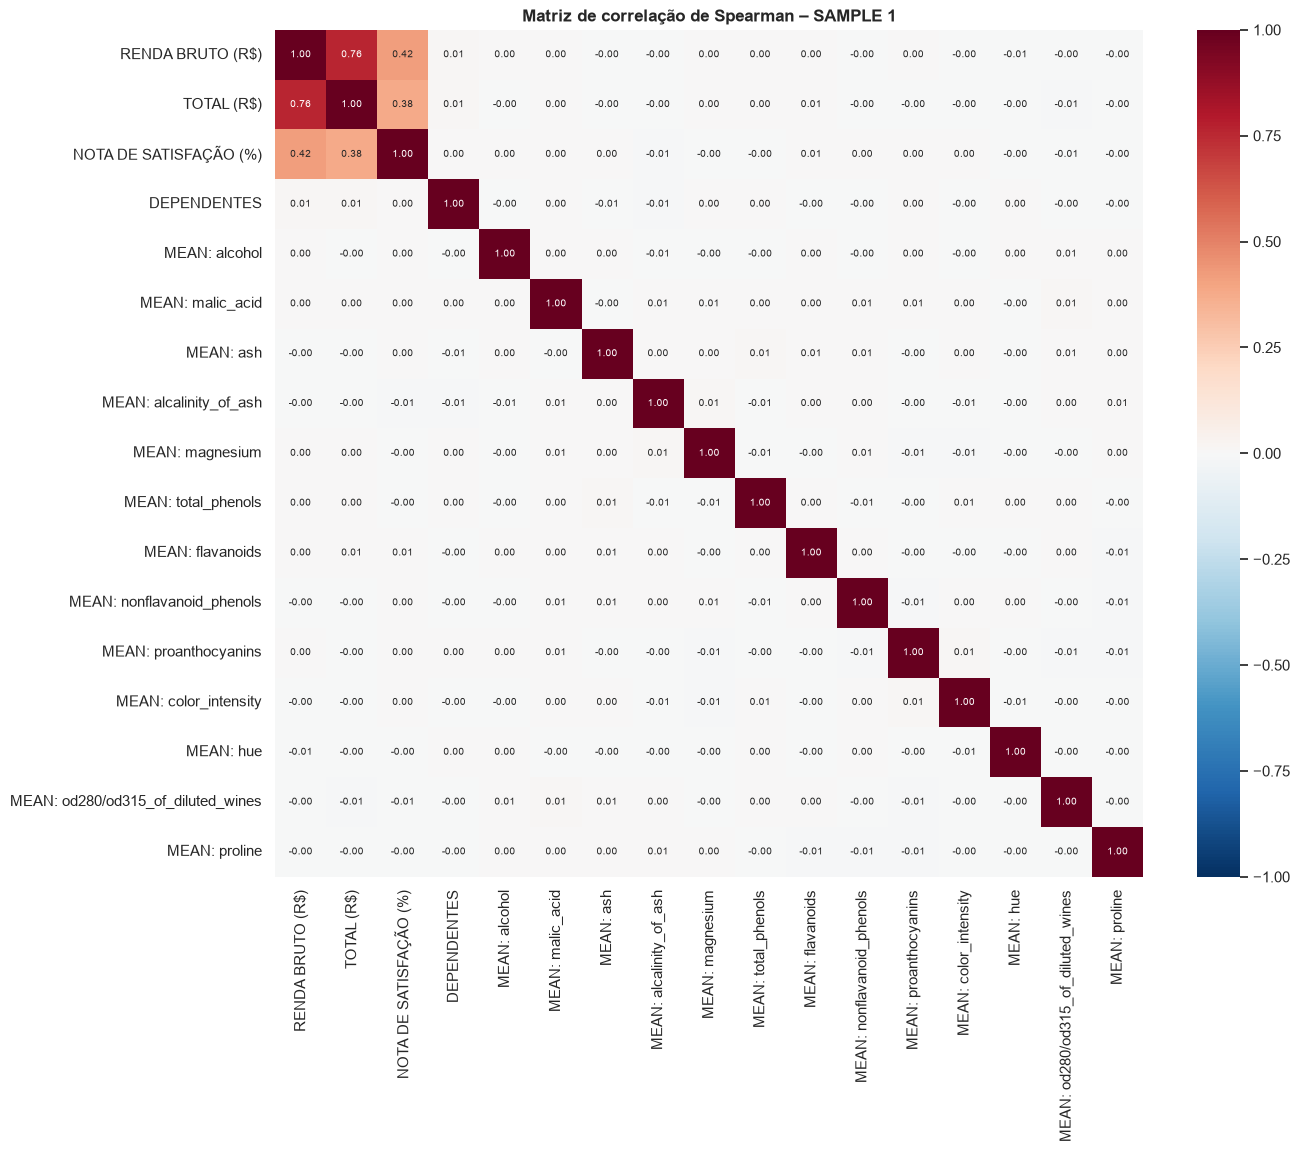

### Acurácia da amostra: média amostral x média populacional

,Média população,Média SAMPLE 1,Erro relativo (%)
RENDA BRUTO (R$),7717.5422,7709.2494,-0.1075
TOTAL (R$),851.4478,848.0931,-0.3940
NOTA DE SATISFAÇÃO (%),68.9812,68.9790,-0.0033
DEPENDENTES,1.0598,1.0615,0.1621
MEAN: alcohol,13.0004,12.9948,-0.0426
MEAN: malic_acid,2.3372,2.3318,-0.2287
MEAN: ash,2.3665,2.3679,0.0564
MEAN: alcalinity_of_ash,19.4891,19.4831,-0.0308
MEAN: magnesium,99.7546,99.7347,-0.0199
MEAN: total_phenols,2.2948,2.2937,-0.0485


In [36]:
res_A2_1 = AtividadeA2_1(SAMPLE_1, table49)
RESULTADOS["A2.1"] = res_A2_1

### CONCLUSÃO A2.1 – Variáveis Quantitativas (SAMPLE 1)

* **TOTAL (R$)**: média R$ 848,09, mediana R$ 510,28, desvio R$ 848,39 (CV = 100%). Tem assimetria forte à direita (1,98) e é leptocúrtica. A média por conta cresce de ESSENTIAL (R$ 426) para VIP (R$ 934) e PRIME (R$ 2.101).
* **RENDA BRUTO (R$)**: média R$ 7.709, mediana R$ 3.364 (CV = 86%), assimétrica à direita. Acompanha o tipo de conta: ESSENTIAL R$ 3.866 | VIP R$ 8.497 | PRIME R$ 19.119.
* **NOTA DE SATISFAÇÃO (%)**: praticamente constante em 68,68 (CV = 2%). Só varia no PRIME (média 70,35), e por isso informa pouco sobre a satisfação.
* **DEPENDENTES**: mediana 1 (53% têm 1 dependente).
* **MEAN:* (físico-químicas)**: simétricas e aproximadamente normais (assimetria e curtose ≈ 0), com os valores negativos já apontados na A1.2.
* Nenhuma variável principal é normal (Shapiro-Wilk p ≈ 0).
* **Acurácia**: o erro relativo entre as médias da amostra e da população é **< 0,4%** em todas as 17 variáveis quantitativas.

###Atividade A2.2: Analisar as variáveis Qualitativas

### Tabelas de frequência – SAMPLE 1 x População

Freq. SAMPLE 1  % SAMPLE 1  % População  Diferença (p.p.)
REGIÃO        SUDESTE                            33829      67.254       67.044             0.210
              SUL                                 8052      16.008       15.980             0.028
              CENTRO-OESTE                        4406       8.759        9.008            -0.248
              NORDESTE                            2999       5.962        5.989            -0.027
              NORTE                               1014       2.016        1.979             0.037
SEXO          MASCULINO                          43712      86.903       87.026            -0.124
              FEMININO                            6588      13.097       12.974             0.124
ESTADO CIVIL  CASADO                             27716      55.101       55.073             0.028
              SOLTEIRO                           18423      36.626       36.930            -0.304
              DESQUITADO(A) / VIÚVO(A)            4161       8.272        7.997             0.276
TIPO DA CONTA ESSENTIAL                          29180      58.012       58.011             0.001
              VIP                                12127      24.109       24.109             0.000
              PRIME                               8993      17.879       17.879            -0.001
DEPENDENTES   1                                  26617      52.917       53.057            -0.141
              0                                  13610      27.058       26.978             0.080
              2                                   4954       9.849        9.986            -0.137
              3                                   3606       7.169        6.965             0.204
              4                                   1513       3.008        3.015            -0.007

### Qui-quadrado de aderência (representatividade da amostra)

,H0,Estatística,p_value,Decisão (α = 5%)
Teste,,,,
Aderência – REGIÃO,% amostra = % população,4.1994,0.3797,Não rejeita H0
Aderência – SEXO,% amostra = % população,0.6813,0.4091,Não rejeita H0
Aderência – ESTADO CIVIL,% amostra = % população,6.0433,0.0487,Rejeita H0
Aderência – TIPO DA CONTA,% amostra = % população,0.0000,1.0000,Não rejeita H0
Aderência – DEPENDENTES,% amostra = % população,4.2712,0.3705,Não rejeita H0


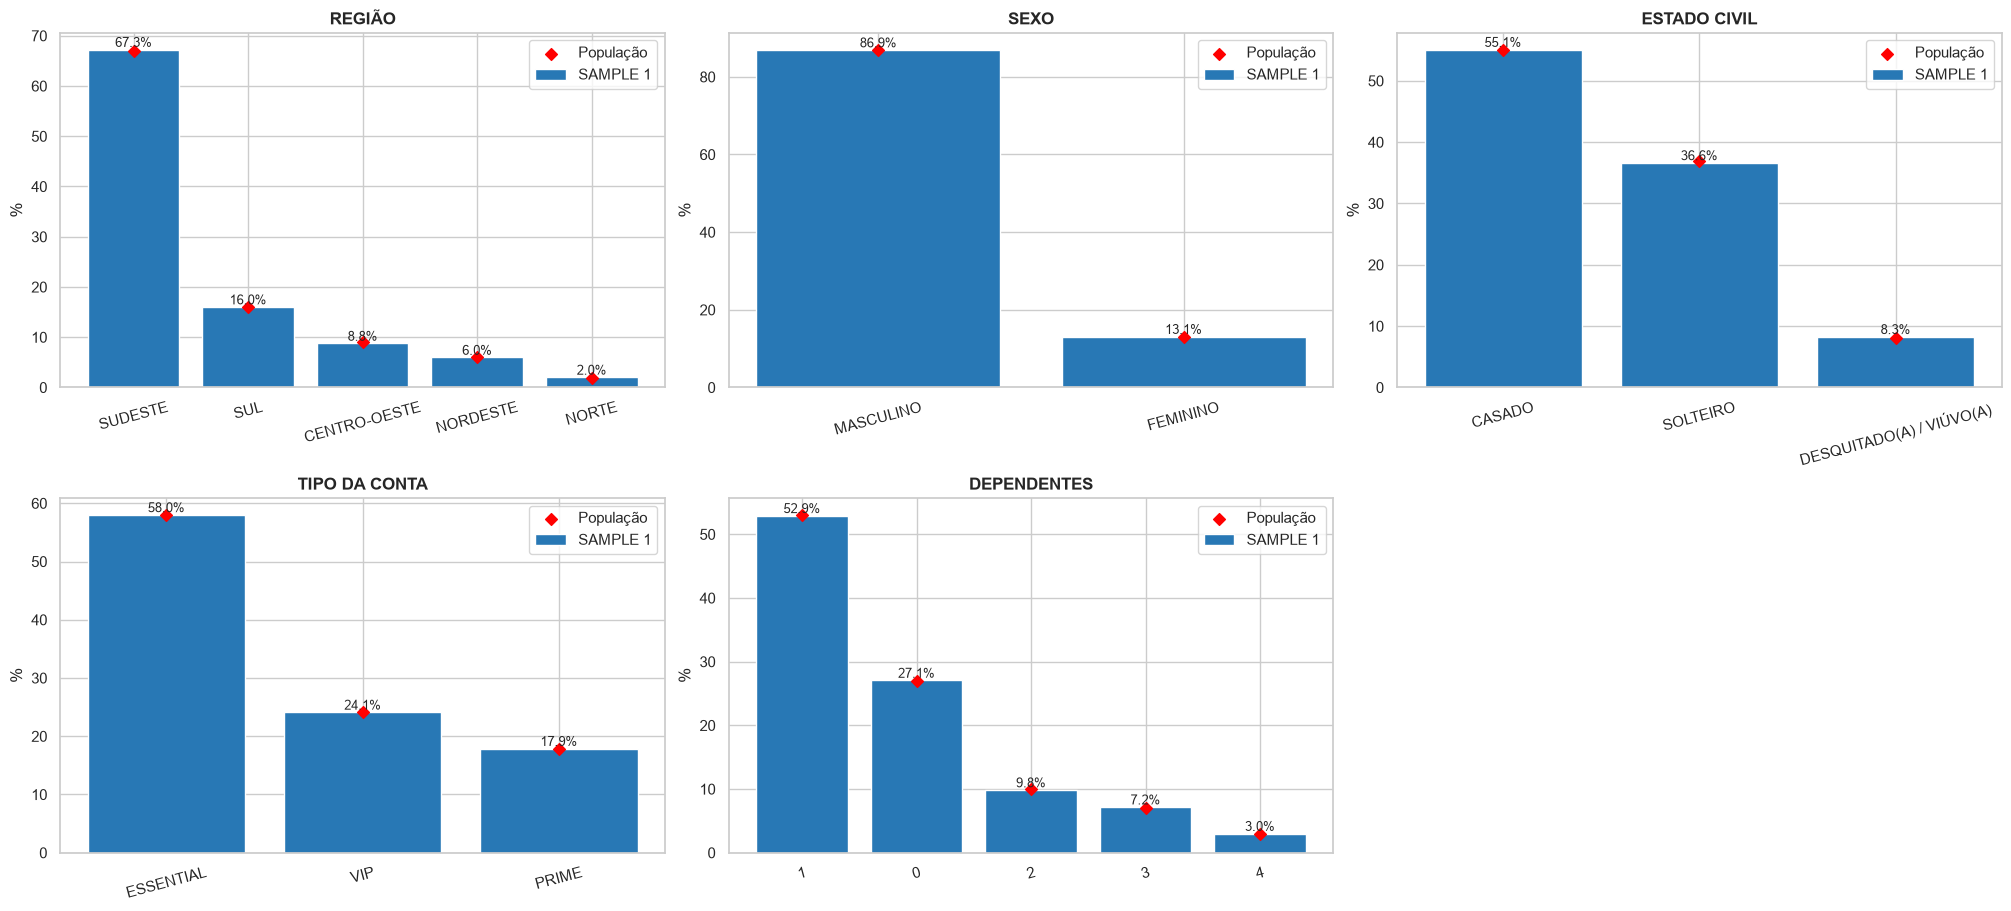

### Qui-quadrado de independência entre variáveis qualitativas

,Qui²,p_value,V de Cramér,Decisão (α = 5%)
Par,,,,
TIPO DA CONTA x SEXO,3.8109,0.1488,0.0087,Independentes
TIPO DA CONTA x REGIÃO,5.6466,0.6867,0.0075,Independentes
TIPO DA CONTA x ESTADO CIVIL,5.9528,0.2027,0.0077,Independentes
TIPO DA CONTA x DEPENDENTES,7.8999,0.4433,0.0089,Independentes
SEXO x REGIÃO,4.6066,0.3301,0.0096,Independentes
SEXO x ESTADO CIVIL,1.6350,0.4415,0.0057,Independentes


**TIPO DA CONTA x REGIÃO (% por linha):**

REGIÃO,CENTRO-OESTE,NORDESTE,NORTE,SUDESTE,SUL
TIPO DA CONTA,,,,,
ESSENTIAL,8.84,5.95,1.99,67.36,15.85
PRIME,8.61,5.89,2.09,66.64,16.77
VIP,8.67,6.04,2.01,67.44,15.83


### OPINIÃO DO CLIENTE – frequências (25 frases)

,Freq.,%
OPINIÃO DO CLIENTE,,
Funcionou bem e me atendeu no prazo certo a UVVine,7821,15.549
Fiquei satisfeito com o serviço da UVVine,7813,15.533
"Serviço eficiente, recomendo o clube: UVVine",7715,15.338
Gostei do atendimento prestado pela UVVine,7680,15.268
Entrega foi boa e rápida na UVVine,7664,15.237
Foi indiferente minha experiência com a UVVine,1601,3.183
Não tenho muito a dizer sobre a UVVine,1537,3.056
Nada digno de nota com a UVVine,1506,2.994
Sem opinião formada sobre a UVVine,1491,2.964


In [37]:
res_A2_2 = AtividadeA2_2(SAMPLE_1, table49)
RESULTADOS["A2.2"] = res_A2_2

### CONCLUSÃO A2.2 – Variáveis Qualitativas (SAMPLE 1)

* **Perfil do cliente**: predominantemente **MASCULINO (86,9%)**, do **SUDESTE (67,3%)**, **CASADO (55,1%)**, com 1 dependente (52,9%). Contas: ESSENTIAL 58,0% | VIP 24,1% | PRIME 17,9%.
* **Representatividade**: as proporções da amostra diferem das da população em **≤ 0,31 p.p.** Pelo qui-quadrado de aderência não há diferença em REGIÃO, SEXO, TIPO e DEPENDENTES. ESTADO CIVIL fica no limite (p = 0,049, diferença máxima de 0,3 p.p.), resultado esperado ao acaso quando se fazem 5 testes a 5%.
* **Associações**: todos os pares testados são **independentes** (p > 0,05, V de Cramér < 0,01). O tipo de conta não depende de sexo, região, estado civil ou dependentes.
* **Opinião**: 5 frases positivas concentram ~77% das respostas.

##Atividade A3: Resultado da Pesquisa de Satisfação

Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

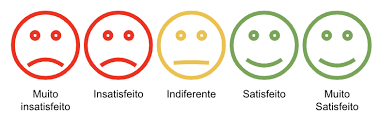

###Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

In [38]:
res_A3_1 = AtividadeA3_1(SAMPLE_1, table49)
RESULTADOS["A3.1"] = res_A3_1

Frases não mapeadas: 0


Freq. SAMPLE 1
SATISFAÇÃO         OPINIÃO DO CLIENTE                                                
Muito insatisfeito Não gostei do atendimento na UVVine                             99
                   Produto chegou atrasado na UVVine                               94
                   Senti que faltou qualidade no atendimento da UV...              84
                   Serviço deixou a desejar na UVVine                             106
                   Tive uma experiência ruim com a UVVine                         105
Insatisfeito       Atendimento comum, poderia melhorar em cordiali...             420
                   Experiência regular, não atendeu a política de ...             397
                   Foi aceitável, esperava mais da UVVine                         417
                   Nada demais, serviço regular na UVVine                         391
                   Razoável, com margem de melhora no preço médio ...             403
Indiferente        Compro exponenciamente, opinião neutra sobre UV...            1482
                   Foi indiferente minha experiência com a UVVine                1601
                   Nada digno de nota com a UVVine                               1506
                   Não tenho muito a dizer sobre a UVVine                        1537
                   Sem opinião formada sobre a UVVine                            1491
Satisfeito         Entrega foi boa e rápida na UVVine                            7664
                   Fiquei satisfeito com o serviço da UVVine                     7813
                   Funcionou bem e me atendeu no prazo certo a UVVine            7821
                   Gostei do atendimento prestado pela UVVine                    7680
                   Serviço eficiente, recomendo o clube:  UVVine                 7715
Muito satisfeito   Excelente experiência, recomendo muito a UVVine                262
                   Produto perfeito, chegou antes do prazo de prev...             315
                   Serviço impecável, adorei o clube:  UVVine                     323
                   Superou expectativas o atendimento na UVVine                   289
                   Ótimo! Tudo ocorreu maravilhosamente bem com a ...             285

,Freq. SAMPLE 1,% SAMPLE 1
SATISFAÇÃO,,
Muito insatisfeito,488,0.97
Insatisfeito,2028,4.03
Indiferente,7617,15.14
Satisfeito,38693,76.92
Muito satisfeito,1474,2.93


**CONCLUSÃO A3.1:** as 25 frases da OPINIÃO DO CLIENTE foram discretizadas, pelo sentimento do texto, em uma escala ordinal de 5 níveis (5 frases por nível, 0 frases sem classificação): Muito insatisfeito (1) | Insatisfeito (2) | Indiferente (3) | Satisfeito (4) | Muito satisfeito (5). Frases de experiência "regular/aceitável/razoável" foram classificadas como **Insatisfeito**, e as de experiência "ruim/atraso/deixou a desejar" como **Muito insatisfeito**.

###Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

n  Proporção (%)  IC95% inf (%)  IC95% sup (%)  EP (p.p.)
Grupo     Nível                                                                                              
GERAL     Muito insatisfeito                    50300          0.970          0.883          1.060      0.044
          Insatisfeito                          50300          4.032          3.853          4.191      0.088
          Indiferente                           50300         15.143         14.825         15.467      0.165
          Satisfeito                            50300         76.924         76.553         77.314      0.192
          Muito satisfeito                      50300          2.930          2.773          3.082      0.076
          CSAT (Satisfeito + Muito satisfeito)  50300         79.855         79.503         80.223      0.180
MASCULINO Muito insatisfeito                    43712          0.977          0.890          1.073      0.047
          Insatisfeito                          43712          4.003          3.827          4.186      0.092
          Indiferente                           43712         15.124         14.792         15.456      0.170
          Satisfeito                            43712         76.988         76.583         77.398      0.204
          Muito satisfeito                      43712          2.908          2.745          3.061      0.079
          CSAT (Satisfeito + Muito satisfeito)  43712         79.896         79.525         80.275      0.191
FEMININO  Muito insatisfeito                     6588          0.926          0.698          1.154      0.117
          Insatisfeito                           6588          4.220          3.719          4.721      0.250
          Indiferente                            6588         15.270         14.451         16.181      0.444
          Satisfeito                             6588         76.503         75.470         77.489      0.518
          Muito satisfeito                       6588          3.081          2.687          3.522      0.213
          CSAT (Satisfeito + Muito satisfeito)   6588         79.584         78.613         80.540      0.493

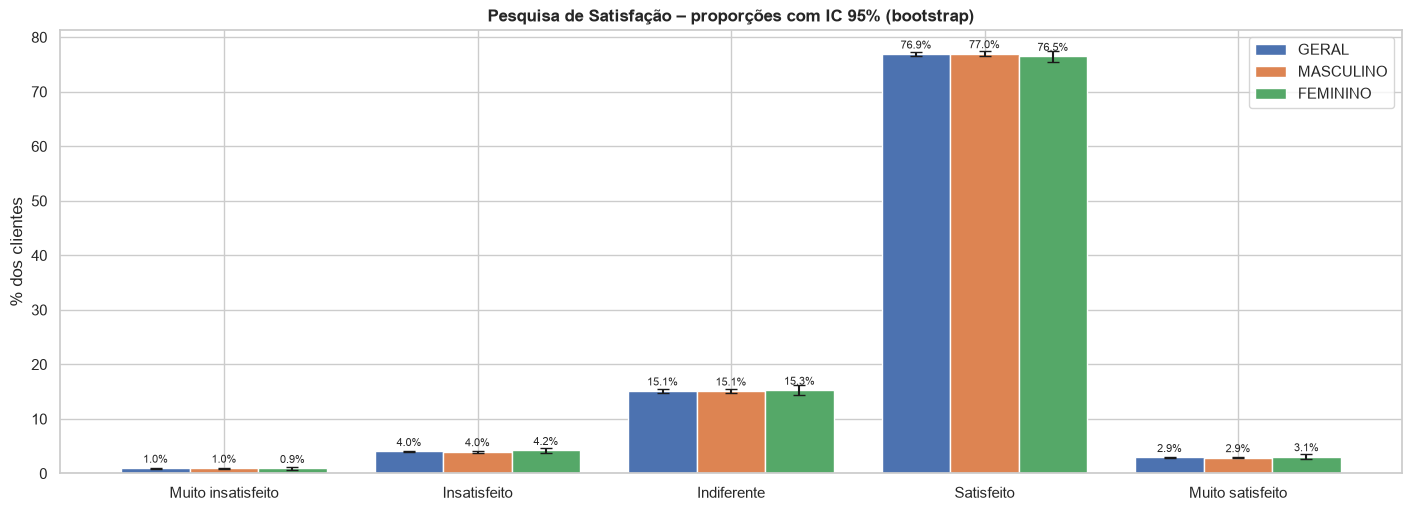

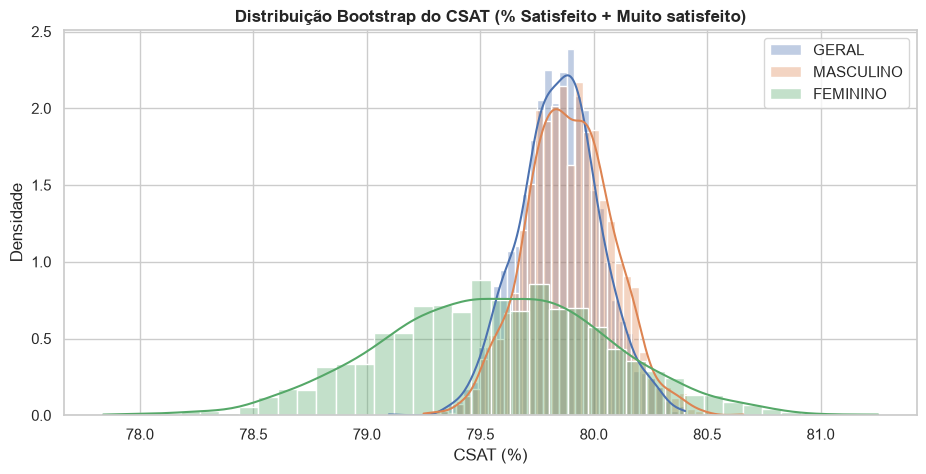

In [39]:
res_A3_2 = AtividadeA3_2(SAMPLE_1)
RESULTADOS["A3.2"] = res_A3_2

**CONCLUSÃO A3.2:** o bootstrap (2.000 reamostragens) dá intervalos estreitos. No GERAL o EP fica ≤ 0,19 p.p.; no FEMININO, que tem n menor (6.588), o EP chega a ≤ 0,52 p.p. Os ICs de MASCULINO e FEMININO se sobrepõem em todos os níveis, e as distribuições bootstrap do CSAT dos dois sexos também se sobrepõem.

###Atividade A3.3: Resultado Final da Pesquisa de Satisfação

### RESULTADO FINAL – Pesquisa de Satisfação: % [IC 95%]

Grupo,GERAL,MASCULINO,FEMININO
Nível,,,
Muito insatisfeito,0.97% [0.88; 1.06],0.98% [0.89; 1.07],0.93% [0.70; 1.15]
Insatisfeito,4.03% [3.85; 4.19],4.00% [3.83; 4.19],4.22% [3.72; 4.72]
Indiferente,15.14% [14.82; 15.47],15.12% [14.79; 15.46],15.27% [14.45; 16.18]
Satisfeito,76.92% [76.55; 77.31],76.99% [76.58; 77.40],76.50% [75.47; 77.49]
Muito satisfeito,2.93% [2.77; 3.08],2.91% [2.75; 3.06],3.08% [2.69; 3.52]
CSAT (Satisfeito + Muito satisfeito),79.85% [79.50; 80.22],79.90% [79.53; 80.28],79.58% [78.61; 80.54]


### Validação: amostra x população

,% SAMPLE 1,% População (real),Diferença (p.p.),Valor real dentro do IC?
SATISFAÇÃO,,,,
Muito insatisfeito,0.970,1.0,-0.030,True
Insatisfeito,4.032,4.0,0.032,True
Indiferente,15.143,15.0,0.143,True
Satisfeito,76.924,77.0,-0.076,True
Muito satisfeito,2.930,3.0,-0.070,True


### Nota média de satisfação (escala 1 a 5)

,mean,std,count
SEXO,,,
FEMININO,3.7659,0.6172,6588.0
MASCULINO,3.7685,0.6122,43712.0
GERAL,3.7681,0.6128,50300.0


### A satisfação difere entre os sexos?

,H0,Estatística,p_value,Decisão (α = 5%),V de Cramér
Teste,,,,,
Qui-quadrado SEXO x SATISFAÇÃO,satisfação independe do sexo,1.663000e+00,0.7974,Não rejeita H0,0.0057
Mann-Whitney (nota 1-5) M x F,mesma distribuição de notas,1.442427e+08,0.7521,Não rejeita H0,NaN


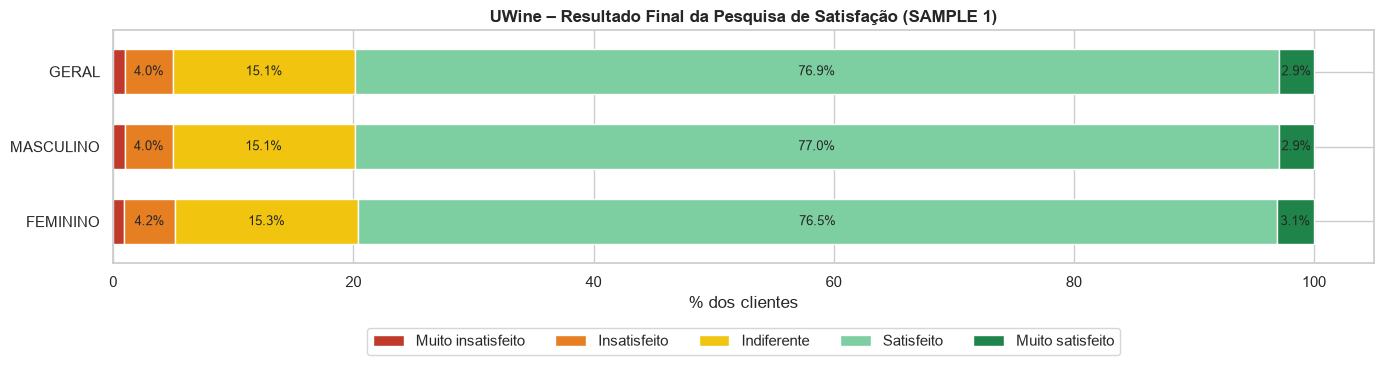

In [40]:
res_A3_3 = AtividadeA3_3(SAMPLE_1, table49, res_A3_2)
RESULTADOS["A3.3"] = res_A3_3

### RESULTADO FINAL A3.3 – Pesquisa de Satisfação (%)

| Nível | GERAL | MASCULINO | FEMININO |
|---|---|---|---|
| Muito insatisfeito | 0,97% | 0,98% | 0,93% |
| Insatisfeito | 4,03% | 4,00% | 4,22% |
| Indiferente | 15,14% | 15,12% | 15,27% |
| Satisfeito | 76,92% | 76,99% | 76,50% |
| Muito satisfeito | 2,93% | 2,91% | 3,08% |
| **CSAT (satisfeitos)** | **79,85% [79,50; 80,22]** | **79,90%** | **79,58%** |

* **~80% dos clientes estão satisfeitos**, 15% indiferentes e só 5% insatisfeitos. Nota média: 3,77 de 5.
* **Não há diferença entre os sexos**: qui-quadrado p = 0,80 e Mann-Whitney p = 0,75.
* **Validação**: os percentuais reais da população (1% | 4% | 15% | 77% | 3%) estão **todos dentro dos IC 95%** da amostra.
* Oportunidade de negócio: apenas 2,9% dos clientes estão "Muito satisfeitos". Converter os 77% "Satisfeitos" em encantados é a principal alavanca. Os 15% "Indiferentes" e as queixas de cashback, preço e cordialidade são os pontos de melhoria.

# RELATÓRIO FINAL - PARTE 1

Fazer aqui:

*   **RELATÓRIO FINAL - PARTE 1** com todas as conclusões e resultados que serão apresentados as gestores da **EMPRESA: UVVine**.
*   Responder a pergunta principal: **QUAL O TAMANHO IDEAL DA AMOSTRA ?**

Justifique sua resposta com os resultados obtidos:

    * Atividade A1: Estratificação amostral da população
    * Atividade A2: Estatística Descritiva

In [41]:
RelatorioFinal()

## TAMANHO IDEAL DA AMOSTRA: **n = 50.300 notas fiscais**

**Alocação por estrato (Neyman) e precisão dos desenhos:**

,Estrato,Peso populacional (Wh),Desvio-padrão (Sh),Peso de Neyman (Wh x Sh),Amostra alocada (nh),Amostra alocada (%)
0,ESSENTIAL,0.5801,356.2757,206.6803,20125,0.4001
1,PRIME,0.1788,1066.8995,190.7559,18575,0.3693
2,VIP,0.2411,494.1313,119.1311,11600,0.2306


,EP da média (R$),Margem de erro 95% (R$),Margem relativa (%),n de AAS com a mesma precisão
Estratificada – Neyman,2.3033,4.5144,0.5302,137047
Estratificada – Proporcional,2.5846,5.0659,0.5950,108833
Aleatória simples (AAS),3.8018,7.4516,0.8752,50300


**Procedimento empírico por categoria:**

,n ideal (empírico),EP no n ideal (R$),IC95% inferior (R$),IC95% superior (R$),EP bootstrap (R$)
Categoria,,,,,
ESSENTIAL,69200,1.3544,426.2296,431.6472,1.3685
VIP,85800,1.6869,929.2370,935.8383,1.7115
PRIME,142700,2.8243,2108.6992,2119.7365,2.7928
GERAL,123000,2.4312,844.8286,854.3643,2.4454


**Testes de hipóteses (SAMPLE 1 x SAMPLE 2):**

,Resultado
Normalidade (AD) – valores,Rejeita H0 (não normal)
Normalidade (AD) – média bootstrap,Não rejeita H0 (normal)
Independência – Spearman,Não rejeita H0
Mesma distribuição – Kolmogorov-Smirnov,Não rejeita H0
Mesmas médias – ANOVA one-way,Não rejeita H0


**Pesquisa de satisfação:**

Grupo,GERAL,MASCULINO,FEMININO
Nível,,,
Muito insatisfeito,0.97% [0.88; 1.06],0.98% [0.89; 1.07],0.93% [0.70; 1.15]
Insatisfeito,4.03% [3.85; 4.19],4.00% [3.83; 4.19],4.22% [3.72; 4.72]
Indiferente,15.14% [14.82; 15.47],15.12% [14.79; 15.46],15.27% [14.45; 16.18]
Satisfeito,76.92% [76.55; 77.31],76.99% [76.58; 77.40],76.50% [75.47; 77.49]
Muito satisfeito,2.93% [2.77; 3.08],2.91% [2.75; 3.06],3.08% [2.69; 3.52]
CSAT (Satisfeito + Muito satisfeito),79.85% [79.50; 80.22],79.90% [79.53; 80.28],79.58% [78.61; 80.54]


## RELATÓRIO FINAL – PARTE 1 (para os gestores da UVVine)

### ❓ QUAL O TAMANHO IDEAL DA AMOSTRA?
# ✅ n = 50.300 notas fiscais, estratificadas por TIPO DA CONTA

**Justificativa – Atividade A1 (Estratificação amostral da população):**
1. **Procedimento teórico-empírico (estratificação + Neyman)**: o erro-padrão se estabiliza em **n = 50.300**, com EP = R$ 2,30 e margem de erro 95% de ±R$ 4,51 (±0,53% da média de R$ 851). Alocação de Neyman: ESSENTIAL 20.125 | PRIME 18.575 | VIP 11.600.
2. **Procedimento empírico** (sem estratificar): exigiria 123.000 notas no GERAL (69,2 mil ESSENTIAL, 85,8 mil VIP, 142,7 mil PRIME). A estratificação alcança a mesma precisão de uma amostra aleatória simples de ~137 mil notas com **63% menos dados**.
3. **Bootstrap**: em todas as categorias o IC 95% contém a média real e o EP bootstrap confirma o EP teórico.
4. **Outliers** (A1.2): os valores altos são legítimos (85% são PRIME) e foram mantidos; removê-los distorceria a média em −27%.
5. **Testes de hipóteses** (A1.3) entre duas amostras disjuntas de 50.300 notas: os dados não são normais (AD), mas a média é (TLC). As amostras são **independentes** (Spearman p = 0,10), têm a **mesma distribuição** (KS p = 0,95) e as **mesmas médias** (ANOVA p = 0,20). Ou seja, com 50.300 notas qualquer amostra sorteada leva às mesmas conclusões, e o tamanho é estável e suficiente.

**Justificativa – Atividade A2 (Estatística descritiva):**
* As médias das 17 variáveis quantitativas diferem da população em menos de 0,4%, e as proporções das qualitativas em menos de 0,31 p.p. A amostra é **acurada e representativa**.
* O perfil é predominantemente masculino (87%), do Sudeste (67%) e casado (55%). O gasto e a renda crescem de ESSENTIAL para VIP e PRIME, e o tipo de conta não depende de sexo nem de região.

**Pesquisa de satisfação (A3):** **CSAT = 79,9%** (IC 95%: 79,5% a 80,2%), igual entre homens (79,9%) e mulheres (79,6%). Há 15% de indiferentes e 5% de insatisfeitos, e só 2,9% estão muito satisfeitos.

**Recomendações:**
* Usar amostras estratificadas de **~50 mil notas** (≈ 10 dias de entrada no sistema) para monitorar o ticket médio, com reamostragem periódica.
* Tratar os valores negativos das variáveis físico-químicas antes da modelagem (Parte 2).
* Criar ações de encantamento (cashback, preço, cordialidade) para levar os "Satisfeitos" e "Indiferentes" a "Muito satisfeitos".